# Confidence analysis
## Three run-1 models: ResNet18 224, ResNet50 28 and original ViT; full test split

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

threshold, n_bins = 0.90, 10
model_names = ['resnet18', 'resnet50', 'vit']
class_names = list(json.loads(Path('data/metadata.json').read_text())['label'].values())
class_names[3] = 'immature granulocytes'
with np.load('data/bloodmnist.npz', allow_pickle=False) as data:
    images, labels = data['test_images'], data['test_labels'].ravel()
probabilities = []
for name in model_names:
    rows = np.loadtxt(f'predictions/{name}_test.csv', delimiter=',', skiprows=1)
    np.testing.assert_array_equal(rows[:, 0], np.arange(len(labels)))
    np.testing.assert_array_equal(rows[:, 1], labels)
    probabilities.append(rows[:, 3:])
probabilities = np.stack(probabilities)
np.testing.assert_allclose(probabilities.sum(-1), 1, atol=1e-6)
predicted = probabilities.argmax(-1)
confidence = probabilities.max(-1)
correct = predicted == labels
bins = np.linspace(0, 1, n_bins + 1)
centers = (bins[:-1] + bins[1:]) / 2

def bin_ids(values):
    return np.clip(np.searchsorted(bins, values, side='right') - 1, 0, n_bins - 1)

def entropy(p):
    p = np.asarray(p, dtype=float)
    return -(p * np.log(np.maximum(p, 1e-300))).sum(-1) / np.log(p.shape[-1])

uncertainty = entropy(probabilities)
print(f'{len(labels)} test images; high-confidence threshold: {threshold:.0%}')
from itertools import combinations
pairs = list(combinations(range(len(model_names)), 2))
model_colors = ['#2678ad', '#3b9956', '#c25a7c']
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=model_colors)


3421 test images; high-confidence threshold: 90%


## Reliability diagram — equal-width confidence bins; ECE weighted by bin counts; empty bins omitted

resnet18: accuracy=96.61%, mean confidence=98.73%, ECE=0.0219
resnet50: accuracy=95.73%, mean confidence=98.66%, ECE=0.0298
vit: accuracy=96.99%, mean confidence=98.62%, ECE=0.0167


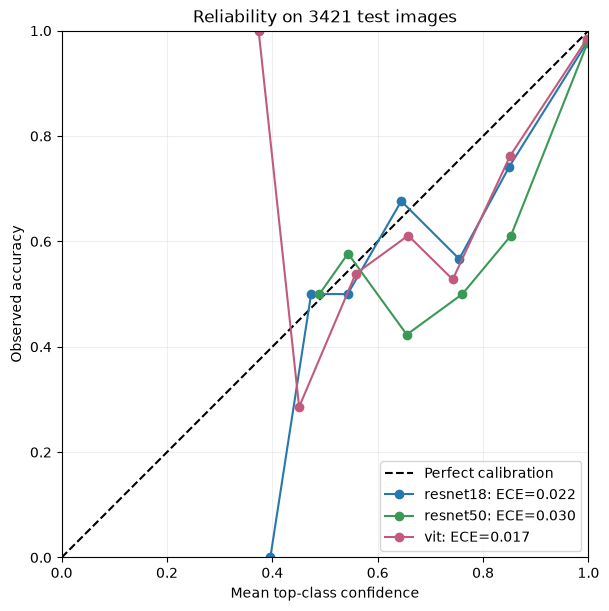

In [3]:
fig, ax = plt.subplots(figsize=(7, 6), layout='constrained')
ax.plot([0, 1], [0, 1], 'k--', label='Perfect calibration')
for m, name in enumerate(model_names):
    groups = bin_ids(confidence[m])
    occupied = [groups == b for b in range(n_bins) if (groups == b).any()]
    x = np.array([confidence[m, mask].mean() for mask in occupied])
    y = np.array([correct[m, mask].mean() for mask in occupied])
    counts = np.array([mask.sum() for mask in occupied])
    ece = np.sum(counts * np.abs(y - x)) / len(labels)
    ax.plot(x, y, 'o-', label=f'{name}: ECE={ece:.3f}')
    print(f'{name}: accuracy={correct[m].mean():.2%}, mean confidence={confidence[m].mean():.2%}, ECE={ece:.4f}')
ax.set(xlabel='Mean top-class confidence', ylabel='Observed accuracy',
       title=f'Reliability on {len(labels)} test images', xlim=(0, 1), ylim=(0, 1))
ax.set_aspect('equal')
ax.grid(alpha=0.2)
ax.legend()
plt.show()

Compare each reliability curve with the diagonal, where confidence equals observed accuracy. Mean confidence exceeds accuracy by about 2.1 percentage points for ResNet18, 2.9 for ResNet50 and 1.6 for ViT. These test results indicate overconfidence, without establishing its training-time cause, and motivate checking calibration on separate data.

## Top-class confidence — all models overlaid, aggregated across classes; all correct and all incorrect test predictions

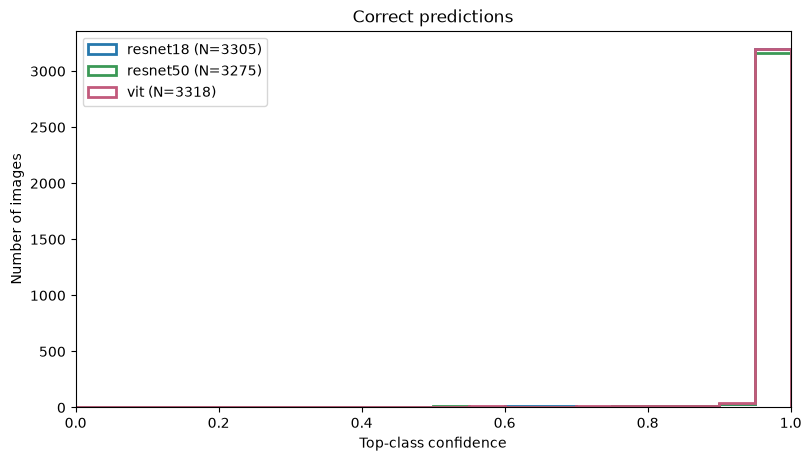

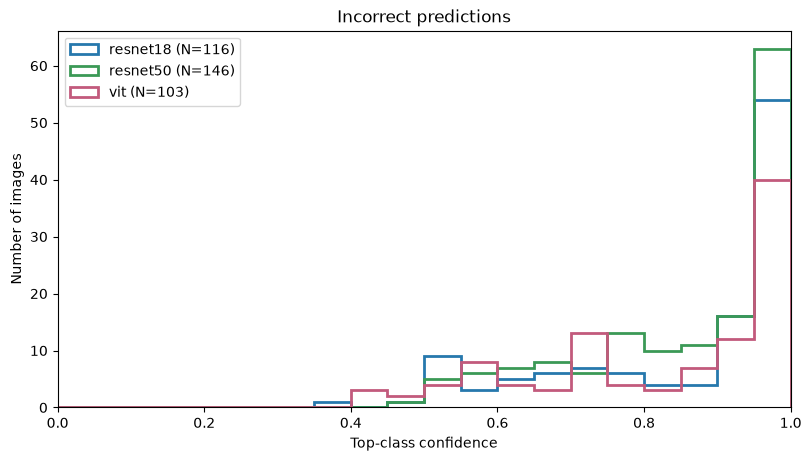

In [4]:
for is_correct, title in [(True, 'Correct predictions'), (False, 'Incorrect predictions')]:
    fig, ax = plt.subplots(figsize=(8, 4.5), layout='constrained')
    for m, color in enumerate(model_colors):
        mask = correct[m] == is_correct
        ax.hist(confidence[m, mask], bins=np.linspace(0, 1, 21), histtype='step',
                linewidth=2, color=color, label=f'{model_names[m]} (N={mask.sum()})')
    ax.set(title=title, xlabel='Top-class confidence', ylabel='Number of images', xlim=(0, 1))
    ax.legend()
    plt.show()

Compare the confidence distributions of correct and incorrect predictions, especially their overlap near one. Incorrect predictions also accumulate at high confidence, despite the models assigning higher average confidence to correct predictions. Maximum confidence alone therefore cannot reliably distinguish correct decisions from errors.

## Confidence disagreement — each model's own maximum probability, not necessarily the same class

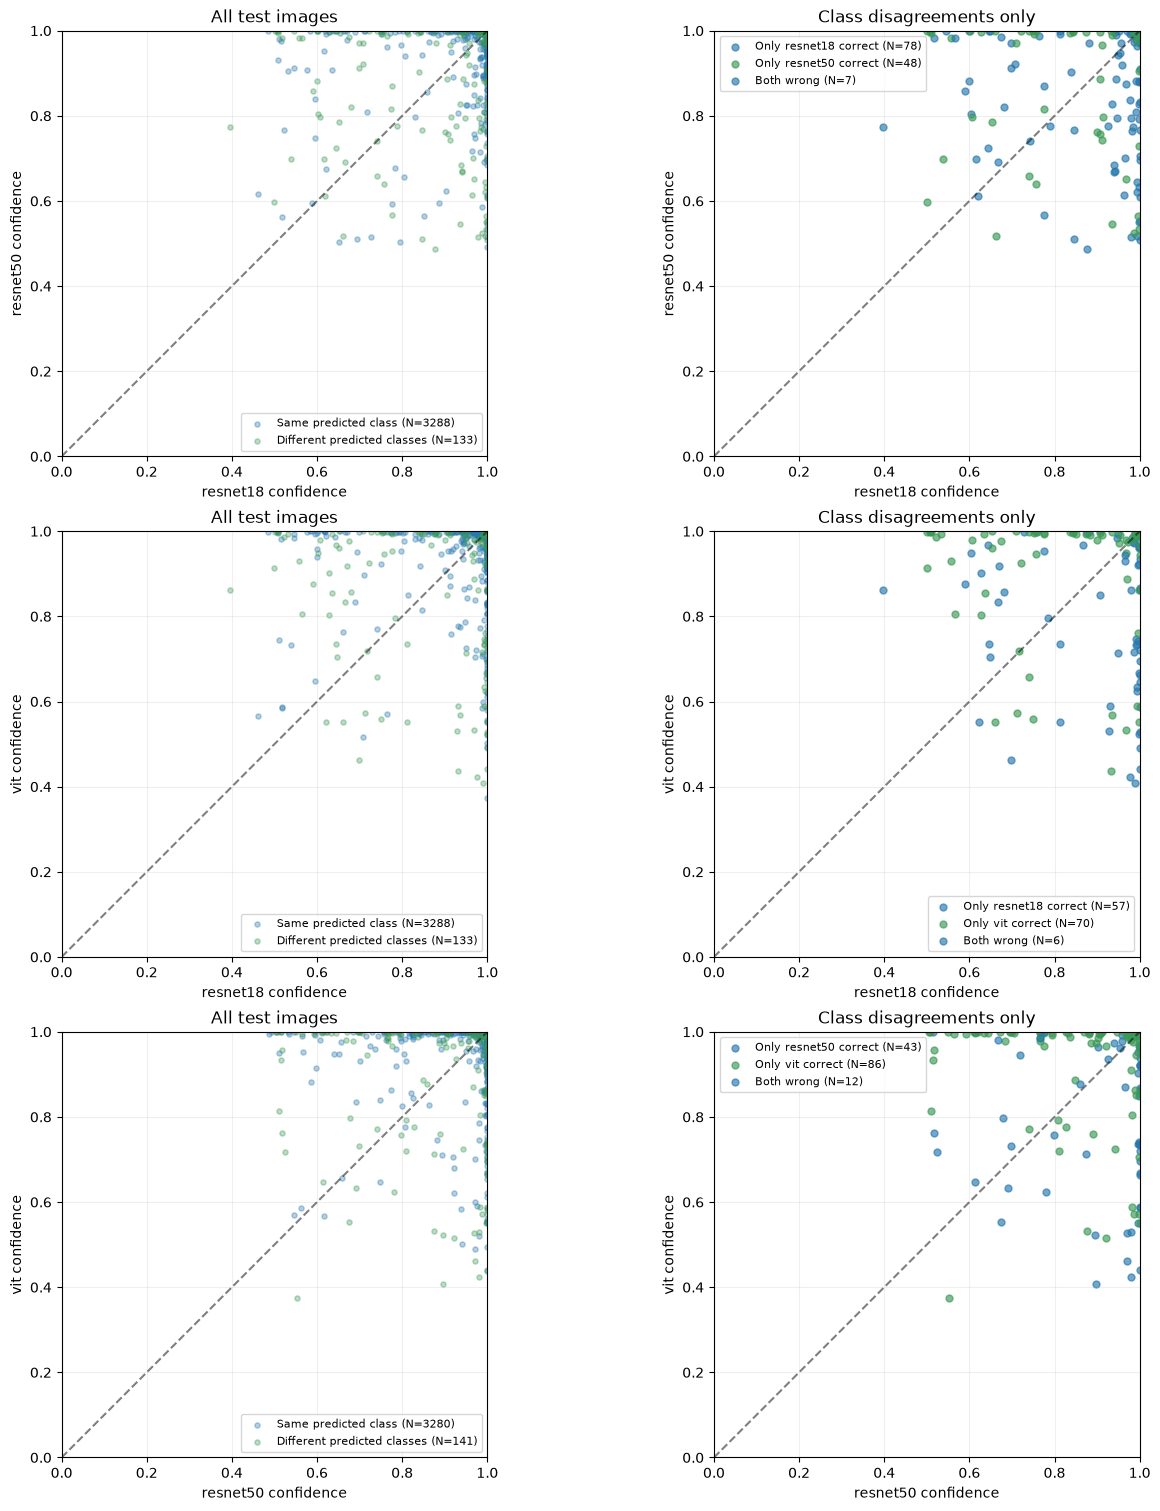

In [5]:
fig, axes = plt.subplots(len(pairs), 2, figsize=(13, 5 * len(pairs)), layout='constrained')
for row, (i, j) in enumerate(pairs):
    agree = predicted[i] == predicted[j]
    for mask, color, title in [(agree, 'C0', 'Same predicted class'), (~agree, 'C1', 'Different predicted classes')]:
        axes[row, 0].scatter(confidence[i, mask], confidence[j, mask], s=14, alpha=0.35,
                              color=color, label=f'{title} (N={mask.sum()})')
    groups = [(correct[i] & ~correct[j], 'C0', f'Only {model_names[i]} correct'),
              (~correct[i] & correct[j], 'C1', f'Only {model_names[j]} correct'),
              (~correct[i] & ~correct[j], 'C3', 'Both wrong')]
    for mask, color, title in groups:
        mask = mask & ~agree
        axes[row, 1].scatter(confidence[i, mask], confidence[j, mask], s=25, alpha=0.65,
                              color=color, label=f'{title} (N={mask.sum()})')
    for ax, title in zip(axes[row], ['All test images', 'Class disagreements only']):
        ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
        ax.set(title=title, xlabel=f'{model_names[i]} confidence', ylabel=f'{model_names[j]} confidence',
               xlim=(0, 1), ylim=(0, 1))
        ax.set_aspect('equal')
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8)
plt.show()


Look for model pairs that disagree on the label while both assign high confidence to their own predictions. On disagreement cases, choosing the more confident model is correct in only about 59–65% of cases across the three pairs. Resolving disagreement therefore requires a tested decision rule rather than assuming that the largest confidence score identifies the correct model.

## Predictive entropy — left: correct/error distributions; right: error percentage within each entropy bin

Entropy ranges from 0 (one class dominates) to 1 (all eight classes are equally probable). Each right-hand bar covers an entropy interval of width 0.1, with errors divided by all images in that interval; labels show errors/total and empty bins are omitted. The dashed line is the model’s overall test error rate, so bars above it identify bins with a higher observed error rate.

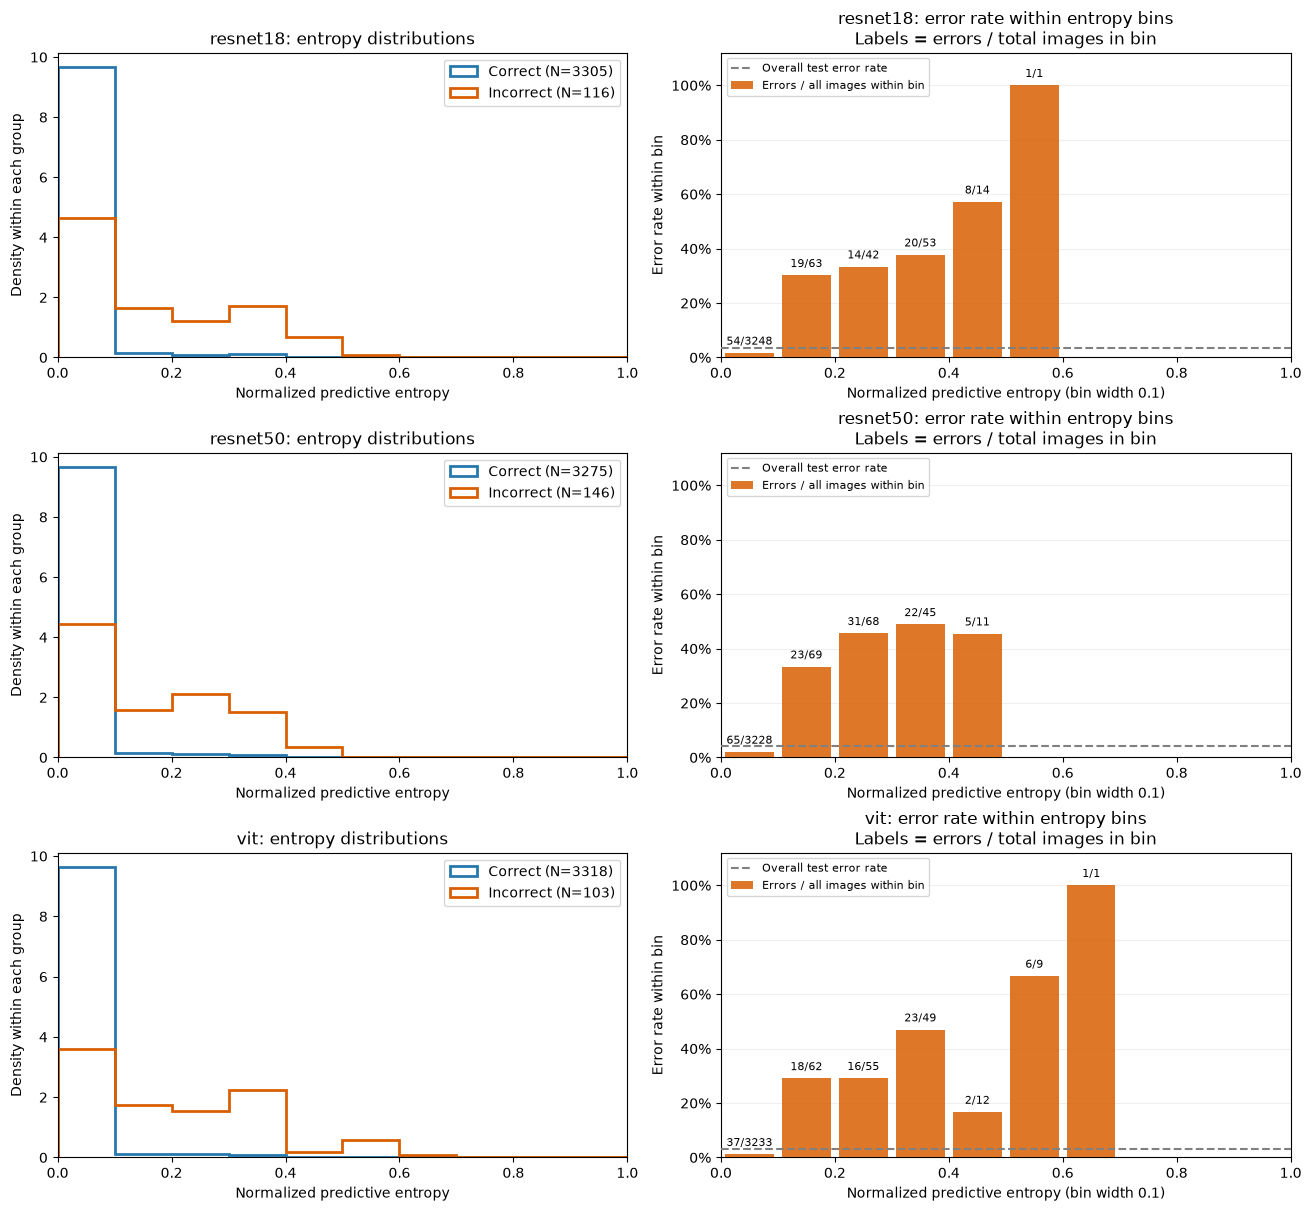

In [6]:
from matplotlib.ticker import PercentFormatter

correct_color, error_color = '#2678ad', '#d95f02'
fig, axes = plt.subplots(len(model_names), 2, figsize=(13, 4 * len(model_names)), layout='constrained')
for m, name in enumerate(model_names):
    for mask, color, title in [(correct[m], correct_color, 'Correct'), (~correct[m], error_color, 'Incorrect')]:
        if mask.any():
            axes[m, 0].hist(uncertainty[m, mask], bins=bins, density=True, histtype='step',
                            linewidth=2, color=color, label=f'{title} (N={mask.sum()})')
    axes[m, 0].set(title=f'{name}: entropy distributions', xlabel='Normalized predictive entropy',
                   ylabel='Density within each group', xlim=(0, 1))
    axes[m, 0].legend()
    groups = bin_ids(uncertainty[m])
    counts = np.bincount(groups, minlength=n_bins)
    errors = np.bincount(groups, weights=~correct[m], minlength=n_bins).astype(int)
    occupied = counts > 0
    rates = errors[occupied] / counts[occupied]
    ax = axes[m, 1]
    ax.bar(centers[occupied], rates, width=0.85 / n_bins, color=error_color, alpha=0.85,
           label='Errors / all images within bin', zorder=3)
    ax.axhline((~correct[m]).mean(), color='gray', ls='--', label='Overall test error rate', zorder=4)
    for x, y, e, count in zip(centers[occupied], rates, errors[occupied], counts[occupied]):
        ax.annotate(f'{e}/{count}', (x, y), xytext=(0, 6), textcoords='offset points',
                    ha='center', fontsize=8)
    ax.set(title=f'{name}: error rate within entropy bins\nLabels = errors / total images in bin',
           xlabel='Normalized predictive entropy (bin width 0.1)', ylabel='Error rate within bin',
           xlim=(0, 1), ylim=(0, 1.12), yticks=np.linspace(0, 1, 6))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.legend(loc='upper left', fontsize=8)
    ax.grid(axis='y', alpha=0.2, zorder=0)
plt.show()

Compare the blue correct and orange incorrect distributions on the left with the error percentages on the right, whose labels show errors/total images in each bin. For ResNet18, the lowest-entropy bin contains 54/3,248 errors, an error rate of only 1.7%, even though those 54 images account for 47% of its 116 errors. The left plots therefore show where each group lies while the right plots show error risk within a bin, and extreme percentages based on one or a few images provide weak evidence.

## Confidence under transformations — directly comparable probability changes; all 3,421 test images

Compare maximum-confidence change with the change in support for the fixed original class on the same −100 to +10 percentage-point scale, shared by all transformation figures. The lower panels use fixed 0–100% error-rate and 0–1 entropy scales, with noise repeats averaged within each of the 3,421 test images. Dashed lines mark unmodified references, and confident-error rates include pre-existing mistakes rather than only newly induced errors.

In [7]:
with np.load('predictions/stability.npz', allow_pickle=False) as saved:
    np.testing.assert_array_equal(saved['model_names'], model_names)
    indices, stability_labels = saved['indices'], saved['labels']
    baseline = saved['baseline']
    levels = {key[7:]: saved[key] for key in saved.files if key.startswith('levels_')}
    transformed = {kind: saved[kind] for kind in levels}
np.testing.assert_array_equal(stability_labels, labels[indices])
np.testing.assert_allclose(baseline, probabilities[:, indices], atol=1e-9)
base_confidence = baseline.max(-1)
base_entropy = entropy(baseline)
base_high_wrong = (baseline.argmax(-1) != stability_labels) & (base_confidence >= threshold)
from matplotlib.ticker import PercentFormatter

change_limits = (-100, 10)
original_class = baseline.argmax(-1)
confidence_changes = {}
for kind, p in transformed.items():
    conf = p.max(-1)
    support = np.take_along_axis(p, original_class[:, None, None, :, None], axis=-1)[..., 0]
    high_wrong = (p.argmax(-1) != stability_labels) & (conf >= threshold)
    # Average repeats and images without retaining another per-image experiment array.
    confidence_changes[kind] = {
        'Maximum confidence: change': conf.mean((2, 3), dtype=float) - base_confidence.mean(-1)[:, None],
        'Original-class support: change': support.mean((2, 3), dtype=float) - base_confidence.mean(-1)[:, None],
        f'Confidently wrong (≥{threshold:.0%})': high_wrong.mean((2, 3)),
        'Normalized predictive entropy': entropy(p).mean((2, 3)),
    }

def plot_confidence_change(kind, p):
    references = [np.zeros(len(model_names)), np.zeros(len(model_names)),
                  base_high_wrong.mean(-1), base_entropy.mean(-1)]
    fig, axes = plt.subplots(2, 2, figsize=(13, 7.5), sharex=True, layout='constrained')
    reference = 1 if kind.endswith('_scale') or kind == 'brightness' else 0
    for j, (ax, (title, curves), original) in enumerate(zip(axes.flat, confidence_changes[kind].items(), references)):
        factor = 100 if j < 2 else 1
        for m, name in enumerate(model_names):
            y = factor * curves[m]
            if j < 2:
                assert change_limits[0] <= y.min() and y.max() <= change_limits[1], 'Change would be clipped.'
            ax.plot(levels[kind], y, 'o-', color=model_colors[m], label=name)
            if j >= 2:
                ax.axhline(original[m], color=model_colors[m], ls='--', alpha=0.4)
        if j < 2:
            ax.axhline(0, color='gray', ls='--')
            ax.set(ylim=change_limits, ylabel='Change (percentage points)')
        else:
            ax.set(ylim=(0, 1), yticks=np.linspace(0, 1, 5),
                   ylabel='Fraction of all test images' if j == 2 else 'Entropy (0–1)')
            if j == 2:
                ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
        ax.axvline(reference, color='gray', ls=':', alpha=0.5)
        ax.set(title=title, xlabel=kind)
        ax.grid(alpha=0.2)
    axes[0, 0].legend()
    fig.suptitle(f'{kind} · N={len(stability_labels)} · fixed y-scales across transformations')
    plt.show()


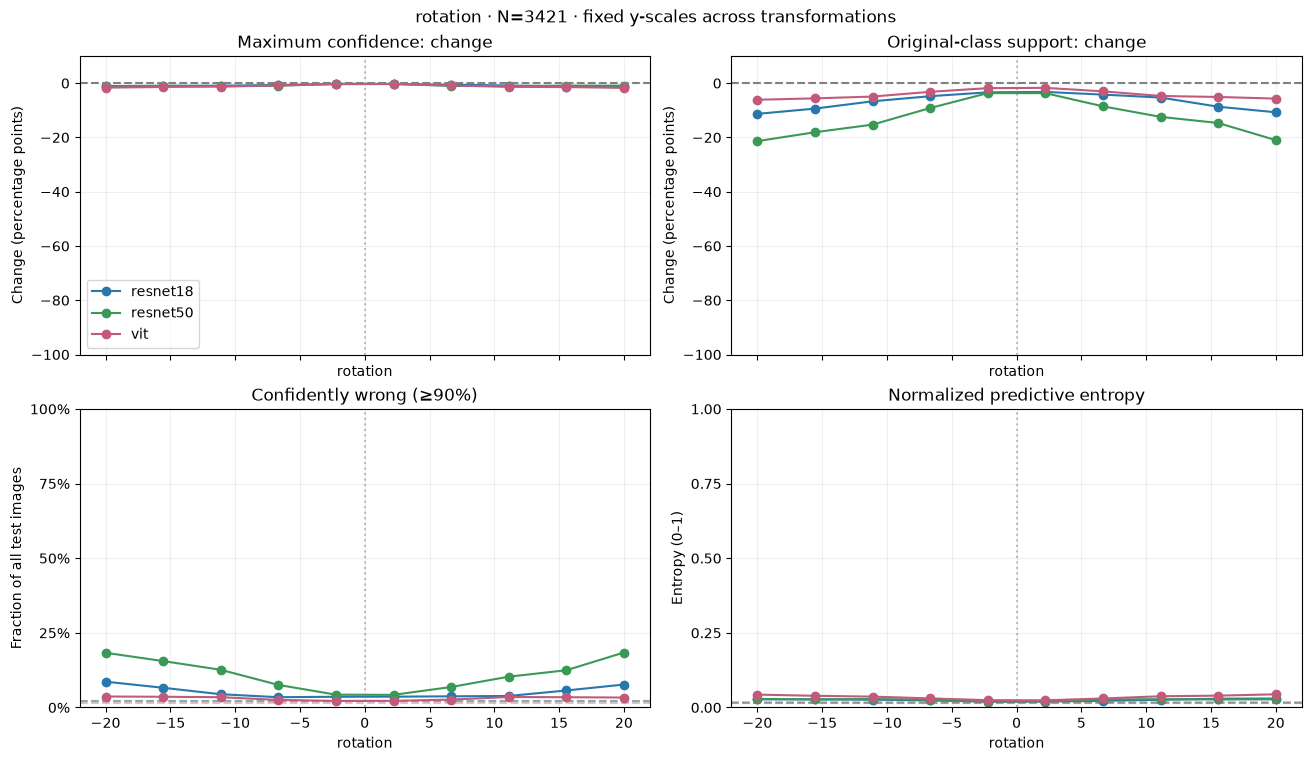

In [8]:
plot_confidence_change('rotation', transformed['rotation'])

Compare the two upper panels on their identical percentage-point scales to see whether rotation changes certainty or support for the original answer. ResNet50 loses only 0.9 percentage points of maximum confidence but 12.8 points of original-class support, while its high-confidence-error fraction averages 11.1%. Rotation can therefore change the answer without making the model much less certain, and the confident-error fraction includes pre-existing errors.

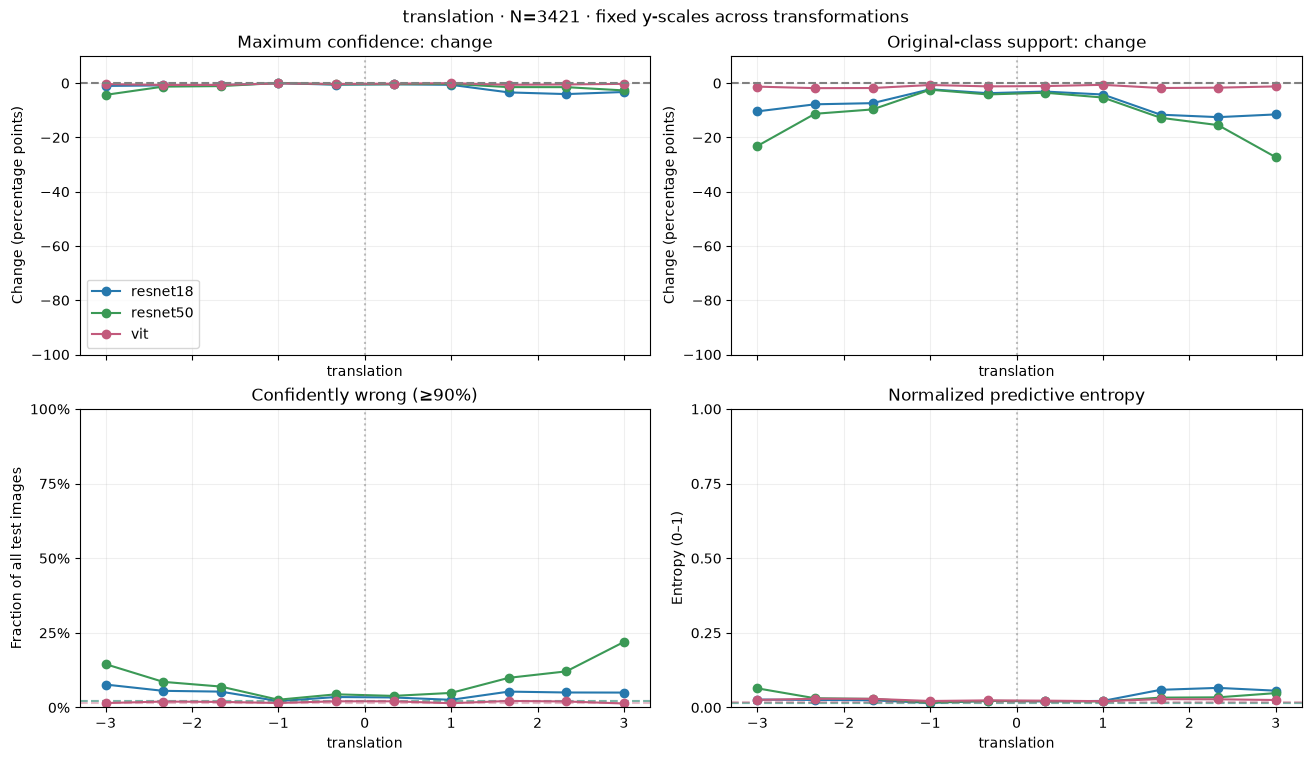

In [9]:
plot_confidence_change('translation', transformed['translation'])

Compare maximum-confidence change with original-class support on the shared scale before checking the confident-error panel. ResNet50 loses only 1.3 percentage points of maximum confidence but 11.5 points of original-class support, with a 9.0% high-confidence-error fraction versus 1.8% for ViT. Translation therefore changes ResNet50’s answers more than its certainty, so nearly constant maximum confidence is not evidence of consistent decisions.

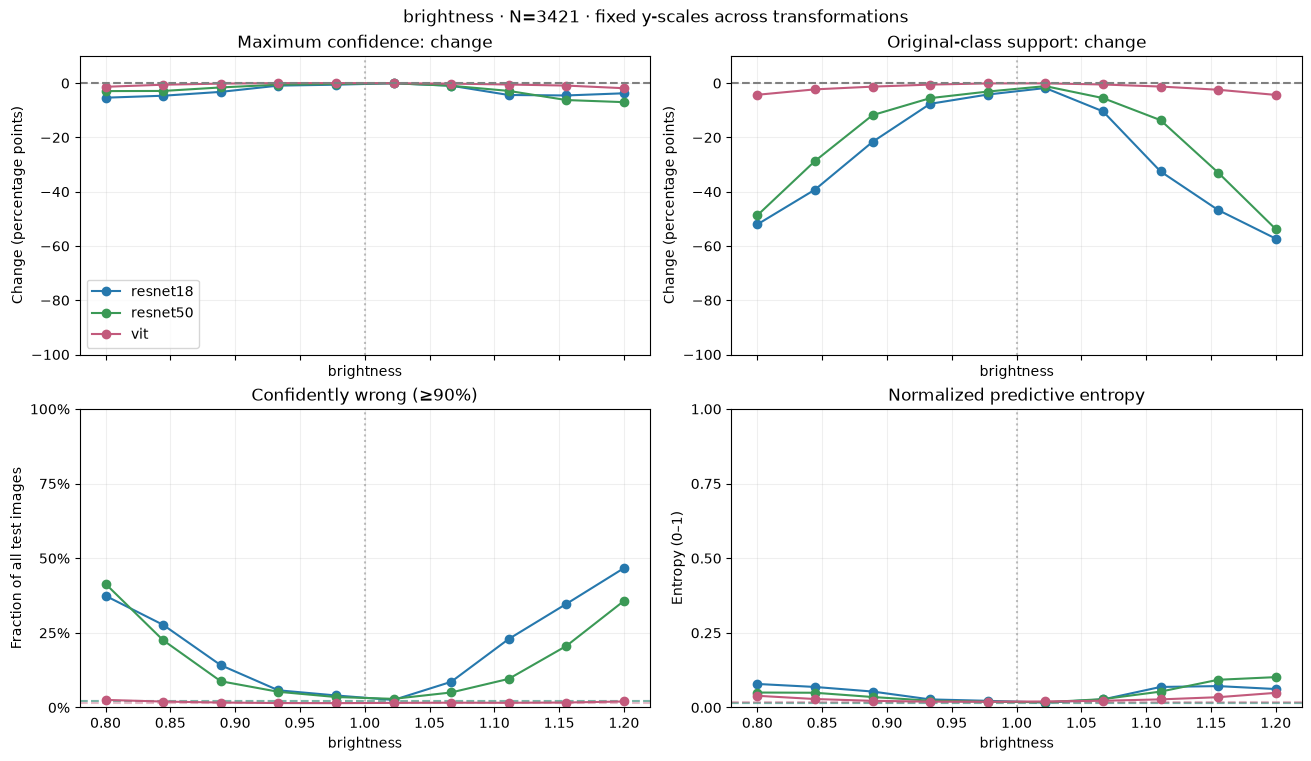

In [10]:
plot_confidence_change('brightness', transformed['brightness'])

Compare the two upper curves on their shared scale and check whether confident-error frequency rises as brightness changes. ResNet18 loses 2.8 percentage points of maximum confidence but 27.3 points of original-class support, with mean confident-error fractions of 20.5% for ResNet18, 15.5% for ResNet50 and 1.8% for ViT. The CNNs therefore often retain concentrated outputs while brightness redirects support away from the original answer.

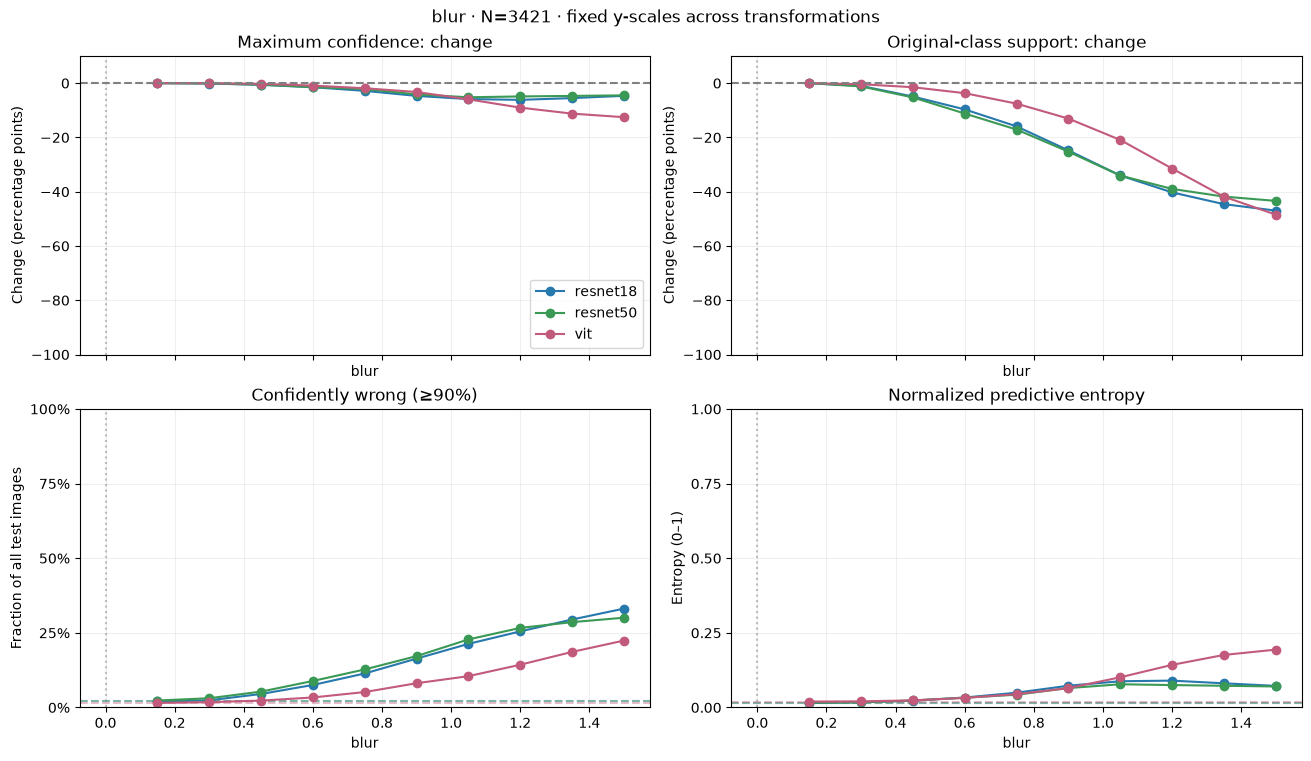

In [11]:
plot_confidence_change('blur', transformed['blur'])

Compare how entropy and confident-error frequency change as blur removes spatial detail. ViT reaches a mean normalized entropy of 0.082, versus 0.054 and 0.049 for the CNNs, and has a lower confident-error fraction of 8.8%. Its blur response spreads probability across competing classes more strongly, so fewer confident errors do not imply that its decisions remain unchanged.

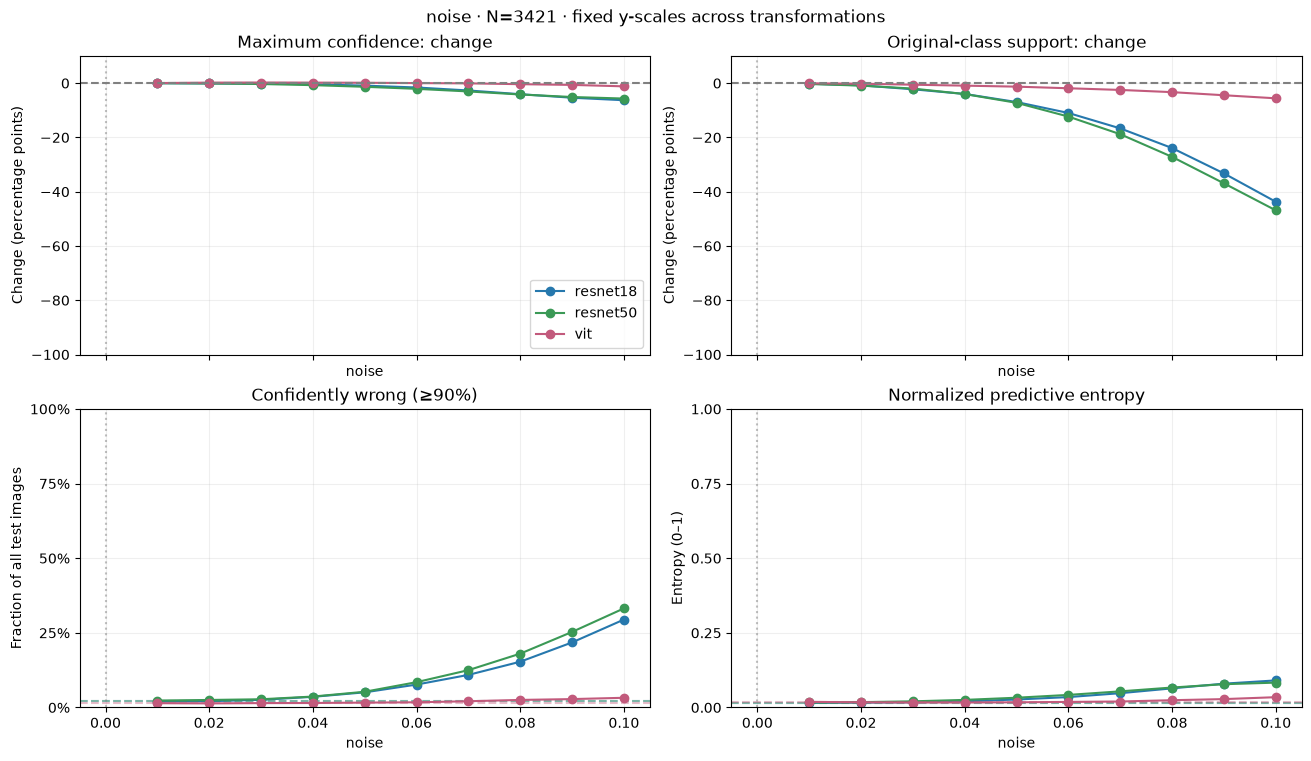

In [12]:
plot_confidence_change('noise', transformed['noise'])

Check whether nearly unchanged confidence under noise accompanies stable accuracy or hides additional confident errors. ViT loses only 0.2 percentage points of maximum confidence and averages 96.2% accuracy, close to its 97.0% baseline, with a 2.0% high-confidence-error fraction. Here confidence stability largely accompanies decision stability, unlike the CNN brightness response, although the confident-error fraction still includes original errors.

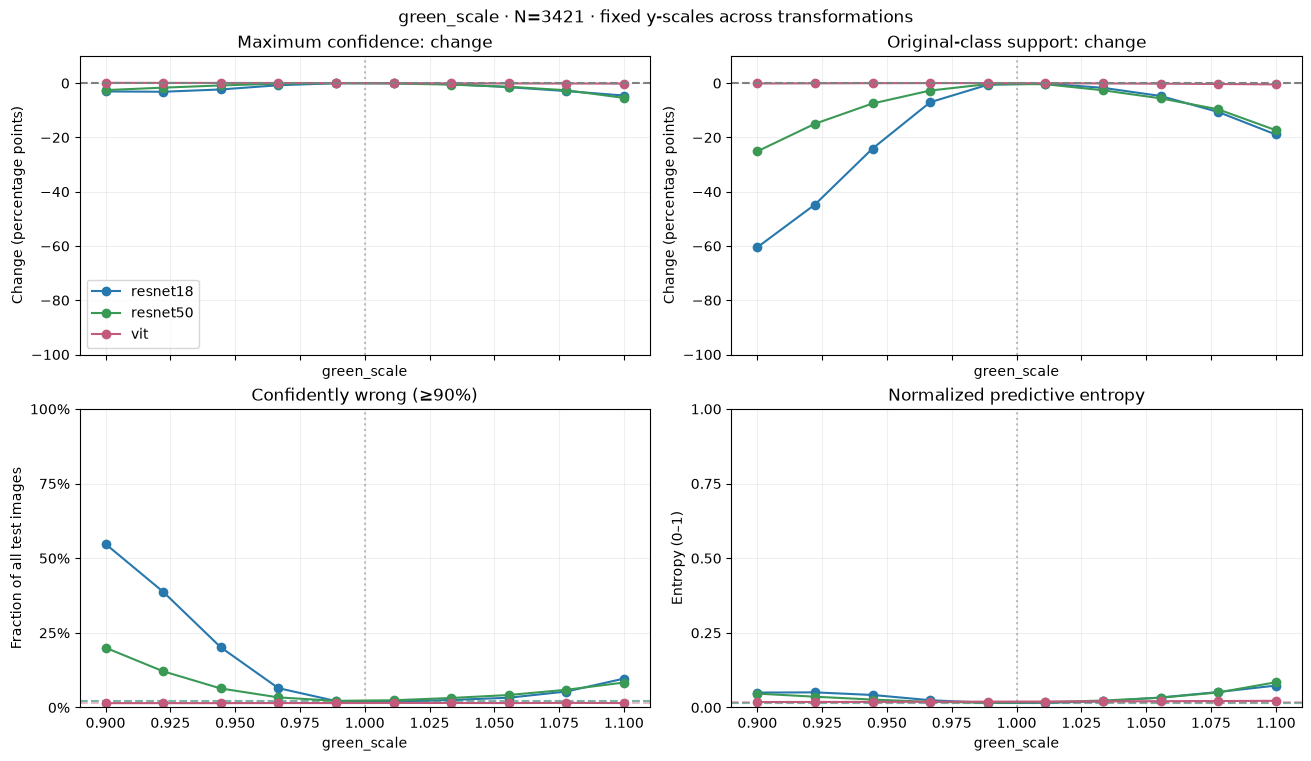

In [13]:
plot_confidence_change('green_scale', transformed['green_scale'])

Compare the direction of green scaling with changes in confidence and confidently wrong predictions. ResNet18 produces high-confidence errors on 14.5% of image–level pairs despite a mean maximum-confidence loss of only 1.9 percentage points, while ViT changes much less. Green-channel sensitivity is therefore strongly checkpoint-dependent and can redirect confident CNN decisions without a proportional uncertainty signal.

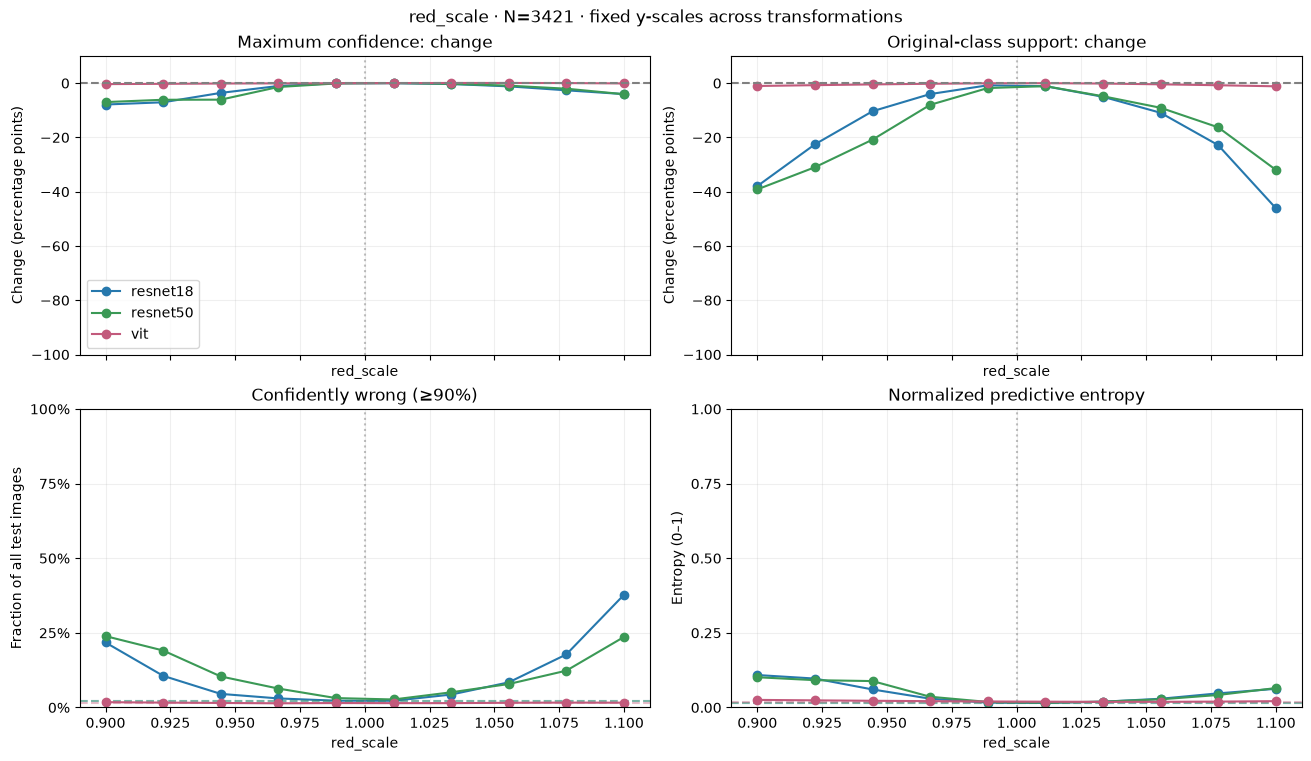

In [14]:
plot_confidence_change('red_scale', transformed['red_scale'])

Compare the two upper panels on their identical scale and use the lower-left panel to check how often confident predictions are wrong. The CNNs lose about 16 percentage points of original-class support but only 2.8 points of maximum confidence, with confident-error fractions of 11.3% and 11.4%. Red scaling therefore changes which answer receives concentrated support more strongly than it reduces certainty.

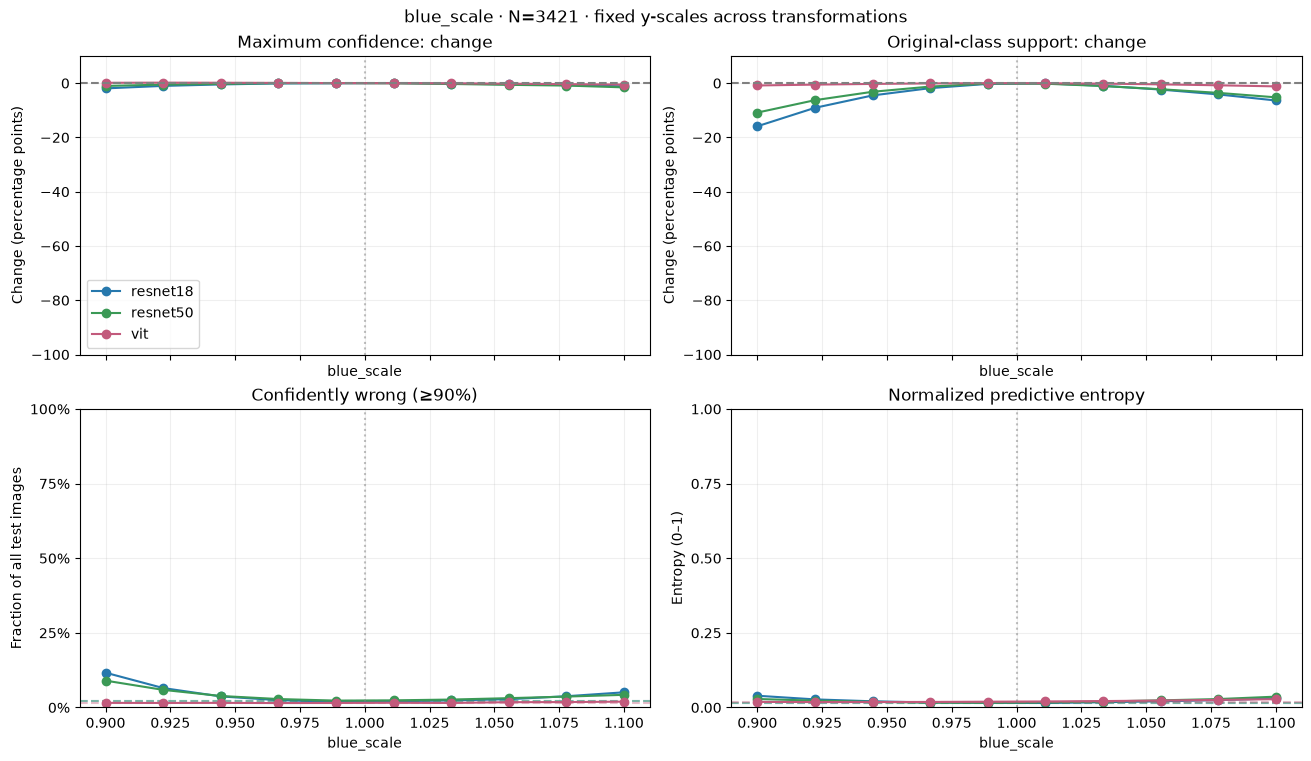

In [15]:
plot_confidence_change('blue_scale', transformed['blue_scale'])

Compare the blue-scaling confident-error curves with the red- and green-scaling curves over the same factor interval. The CNN high-confidence-error fractions are only 4.2% and 4.0% under blue scaling, below their corresponding red and green values. Color sensitivity is therefore channel-specific rather than a uniform response to multiplying any RGB channel.

## Extract every high-confidence error — original RGB image, test index, labels, all probabilities, confidence and entropy; threshold editable above

In [16]:
high_confidence_wrong = {}
for m, name in enumerate(model_names):
    ids = np.flatnonzero(~correct[m] & (confidence[m] >= threshold))
    ids = ids[np.argsort(-confidence[m, ids], kind='stable')]
    high_confidence_wrong[name] = ids
    path = Path(f'predictions/high_confidence_wrong_{name}.npz')
    np.savez_compressed(path, images=images[ids], sample_index=ids, true_label=labels[ids],
                        predicted_label=predicted[m, ids], probabilities=probabilities[m, ids],
                        confidence=confidence[m, ids], normalized_entropy=uncertainty[m, ids],
                        class_names=class_names, model=name, split='test', threshold=threshold,
                        logits=np.load(f'predictions/{name}_test.npz')['logits'][ids])
    print(f'{name}: {len(ids)} high-confidence errors → {path}')


resnet18: 70 high-confidence errors → predictions\high_confidence_wrong_resnet18.npz
resnet50: 79 high-confidence errors → predictions\high_confidence_wrong_resnet50.npz
vit: 52 high-confidence errors → predictions\high_confidence_wrong_vit.npz


## High-confidence-error overlap — all three models and each model pair; model-relative percentages and Jaccard have different denominators

Errors shared by all three: 18 test IDs: [35, 340, 476, 496, 642, 839, 1413, 1462, 1629, 1750, 1762, 2384, 2434, 2649, 3015, 3126, 3329, 3373]
resnet18 / resnet50: shared 36, fractions 51.4% / 45.6%, Jaccard 31.9%
Same wrong class among shared errors: 97.2%
resnet18 / vit: shared 22, fractions 31.4% / 42.3%, Jaccard 22.0%
Same wrong class among shared errors: 95.5%
resnet50 / vit: shared 23, fractions 29.1% / 44.2%, Jaccard 21.3%
Same wrong class among shared errors: 95.7%


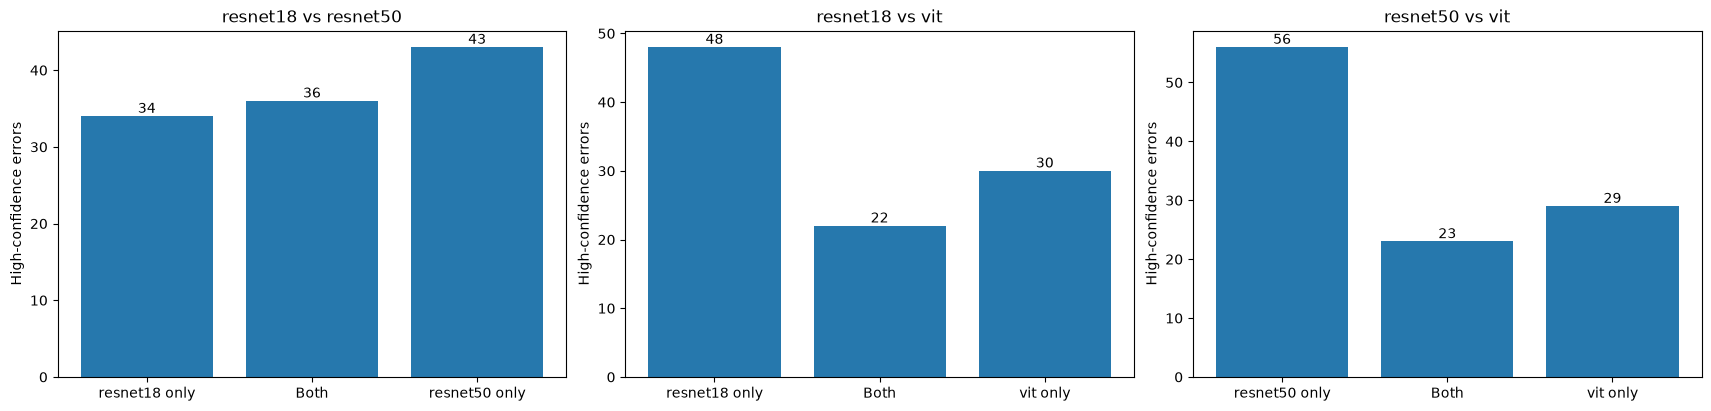

In [17]:
error_ids = [high_confidence_wrong[name] for name in model_names]
shared, union = error_ids[0].copy(), error_ids[0].copy()
for ids in error_ids[1:]:
    shared, union = np.intersect1d(shared, ids), np.union1d(union, ids)
print('Errors shared by all three:', len(shared), 'test IDs:', shared.tolist())
pair_overlap = np.zeros((len(model_names), len(model_names)), dtype=int)
pair_jaccard = np.full_like(pair_overlap, np.nan, dtype=float)
fig, axes = plt.subplots(1, len(pairs), figsize=(17, 4), layout='constrained')
for ax, (i, j) in zip(axes, pairs):
    common, combined = np.intersect1d(error_ids[i], error_ids[j]), np.union1d(error_ids[i], error_ids[j])
    pair_overlap[i, j] = pair_overlap[j, i] = len(common)
    pair_jaccard[i, j] = pair_jaccard[j, i] = len(common) / len(combined) if len(combined) else np.nan
    fractions = [len(common) / len(error_ids[m]) if len(error_ids[m]) else np.nan for m in (i, j)]
    print(f'{model_names[i]} / {model_names[j]}: shared {len(common)}, fractions {fractions[0]:.1%} / {fractions[1]:.1%}, Jaccard {pair_jaccard[i, j]:.1%}')
    if len(common):
        print(f'Same wrong class among shared errors: {(predicted[i, common] == predicted[j, common]).mean():.1%}')
    counts = [len(error_ids[i]) - len(common), len(common), len(error_ids[j]) - len(common)]
    ax.bar([f'{model_names[i]} only', 'Both', f'{model_names[j]} only'], counts)
    ax.bar_label(ax.containers[0])
    ax.set(ylabel='High-confidence errors', title=f'{model_names[i]} vs {model_names[j]}')
for m, ids in enumerate(error_ids):
    pair_overlap[m, m], pair_jaccard[m, m] = len(ids), 1 if len(ids) else np.nan
plt.show()


Compare pairwise high-confidence-error counts together with Jaccard overlap, which accounts for different cohort sizes. ResNet18 and ResNet50 share 36 errors with 31.9% Jaccard overlap, versus 22 and 23 errors and about 21–22% overlap for the CNN–ViT pairs. The CNNs share more of their confident failures, but their non-shared errors also show that the checkpoints are not interchangeable.

## True class → wrong predicted class — counts and percentages within each model's high-confidence errors, not class-specific error rates

resnet18: immature granulocytes → monocyte: 13/70 (18.6%)
resnet18: immature granulocytes → neutrophil: 11/70 (15.7%)
resnet18: neutrophil → immature granulocytes: 9/70 (12.9%)
resnet18: immature granulocytes → lymphocyte: 6/70 (8.6%)
resnet18: monocyte → immature granulocytes: 5/70 (7.1%)
resnet50: monocyte → immature granulocytes: 12/79 (15.2%)
resnet50: neutrophil → immature granulocytes: 11/79 (13.9%)
resnet50: immature granulocytes → monocyte: 10/79 (12.7%)
resnet50: immature granulocytes → neutrophil: 10/79 (12.7%)
resnet50: basophil → immature granulocytes: 5/79 (6.3%)
vit: monocyte → immature granulocytes: 9/52 (17.3%)
vit: immature granulocytes → monocyte: 8/52 (15.4%)
vit: neutrophil → immature granulocytes: 8/52 (15.4%)
vit: basophil → immature granulocytes: 7/52 (13.5%)
vit: immature granulocytes → neutrophil: 6/52 (11.5%)


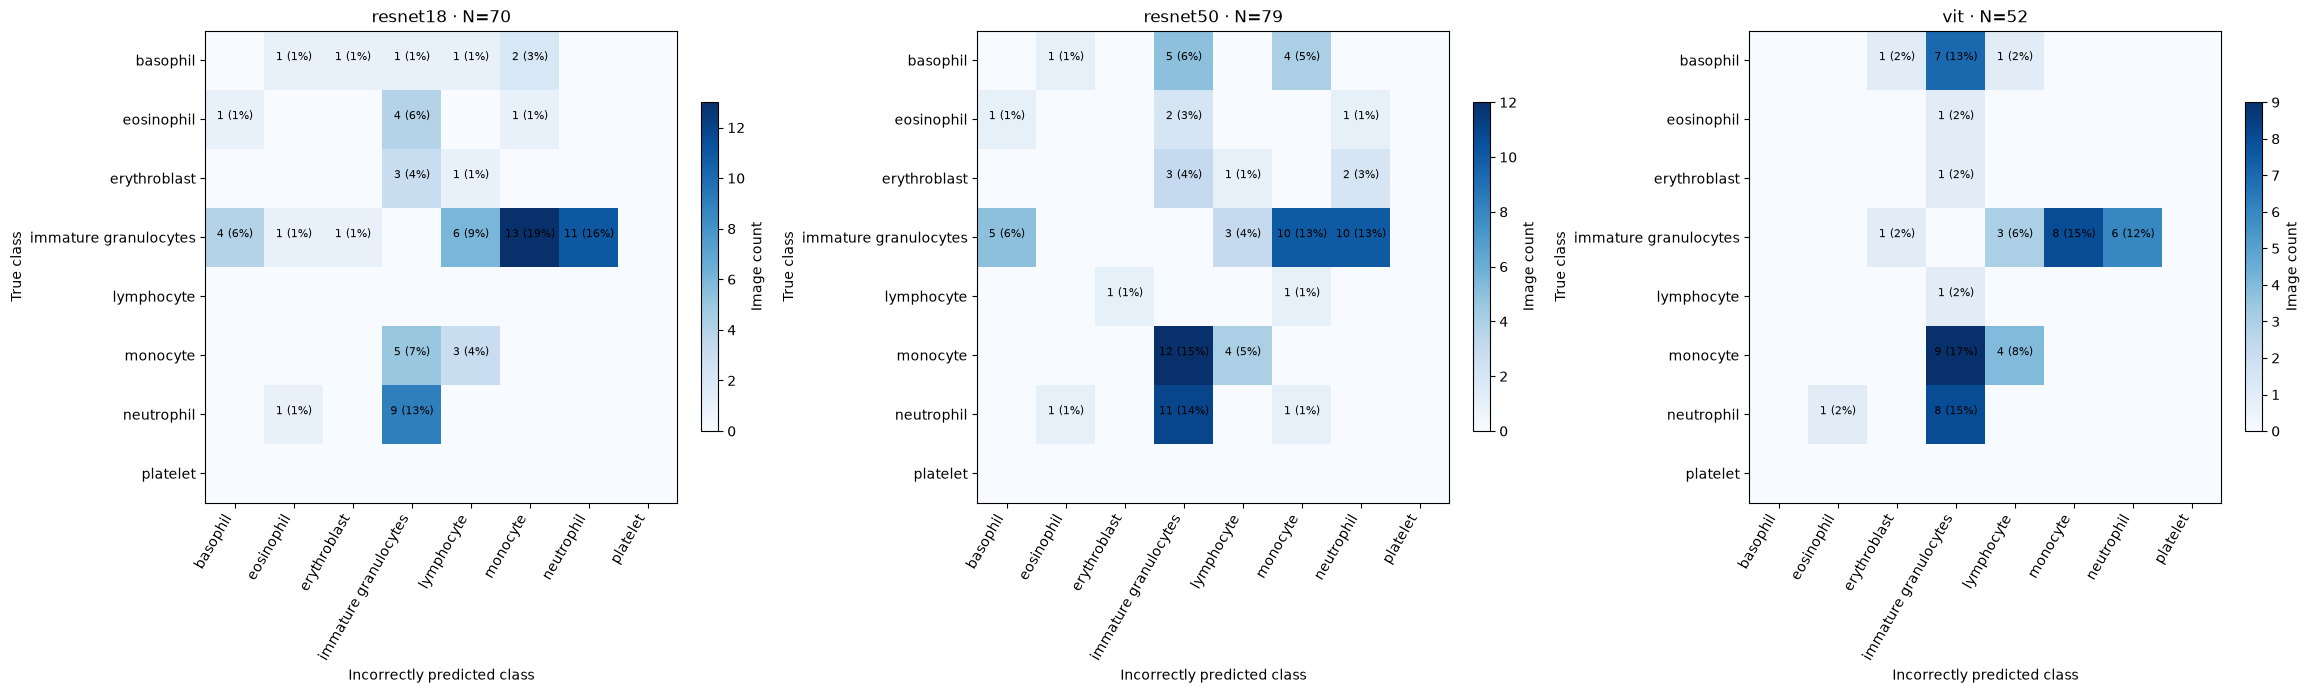

In [18]:
confusions, example_ids = [], []
fig, axes = plt.subplots(1, len(model_names), figsize=(23, 7), layout='constrained')
for m, (ax, ids) in enumerate(zip(axes, error_ids)):
    matrix = np.zeros((8, 8), dtype=int)
    np.add.at(matrix, (labels[ids], predicted[m, ids]), 1)
    confusions.append(matrix)
    im = ax.imshow(matrix, cmap='Blues', vmin=0, vmax=max(matrix.max(), 1))
    ax.set(title=f'{model_names[m]} · N={len(ids)}', xlabel='Incorrectly predicted class', ylabel='True class',
           xticks=range(8), xticklabels=class_names, yticks=range(8), yticklabels=class_names)
    plt.setp(ax.get_xticklabels(), rotation=60, ha='right')
    for c, d in zip(*np.nonzero(matrix)):
        ax.text(d, c, f'{matrix[c, d]} ({matrix[c, d] / len(ids):.0%})', ha='center', fontsize=8)
    fig.colorbar(im, ax=ax, shrink=0.6, label='Image count')
    pairs = np.dstack(np.unravel_index(np.argsort(-matrix.ravel(), kind='stable'), matrix.shape))[0]
    pairs = [(c, d) for c, d in pairs if matrix[c, d] > 0]
    for c, d in pairs[:5]:
        print(f'{model_names[m]}: {class_names[c]} → {class_names[d]}: {matrix[c, d]}/{len(ids)} ({matrix[c, d] / len(ids):.1%})')
    example_ids.append(np.array([ids[np.flatnonzero((labels[ids] == c) & (predicted[m, ids] == d))[0]] for c, d in pairs[:3]], dtype=int))
plt.show()

Read the true-to-predicted class counts to identify recurring substitutions, without treating them as per-class error rates. Immature granulocytes occur on either side of 58/70 ResNet18 error pairs, 61/79 ResNet50 pairs and 45/52 ViT pairs. These failures concentrate around particular class competitions, while the later class-rate view is needed to separate that concentration from class frequency.

## Simple RGB features — boundary gradient energy is only a proxy for edge content, not cell location or segmentation

In [19]:
rgb = images.astype(float) / 255
luminance = rgb @ np.array([0.299, 0.587, 0.114])
maximum, minimum = rgb.max(-1), rgb.min(-1)
saturation = np.divide(maximum - minimum, maximum, out=np.zeros_like(maximum), where=maximum > 0)
gy, gx = np.gradient(luminance, axis=(1, 2))
energy = np.hypot(gx, gy)
border = np.ones((28, 28), dtype=bool)
border[4:-4, 4:-4] = False
boundary_energy = energy[:, border].sum(-1) / np.maximum(energy.sum((1, 2)), 1e-12)
features = np.column_stack((luminance.mean((1, 2)), saturation.mean((1, 2)),
                            rgb.mean((1, 2)), luminance.std((1, 2)), boundary_energy))
feature_names = ['Mean brightness', 'Mean saturation', 'Mean red', 'Mean green', 'Mean blue',
                 'Luminance contrast (std)', 'Boundary gradient fraction']
control_weights, feature_effects = [], []
for m, ids in enumerate(error_ids):
    weights = np.zeros(len(labels))
    for c in range(8):
        mask = correct[m] & (labels == c)
        if mask.any() and len(ids):
            weights[mask] = (labels[ids] == c).mean() / mask.sum()
    control_weights.append(weights)
    if not len(ids):
        feature_effects.append(np.full(len(feature_names), np.nan))
        continue
    mean = np.average(features, axis=0, weights=weights)
    std = np.sqrt(np.average((features - mean) ** 2, axis=0, weights=weights))
    effects = (features[ids].mean(0) - mean) / np.maximum(std, 1e-12)
    feature_effects.append(effects)

def plot_feature_comparison(m):
    ids = error_ids[m]
    weights, effects = control_weights[m], feature_effects[m]
    fig, axes = plt.subplots(2, 4, figsize=(16, 7), layout='constrained')
    for j, ax in enumerate(axes.flat[:7]):
        edges = np.linspace(features[:, j].min(), features[:, j].max() + 1e-12, 16)
        ax.hist(features[:, j], bins=edges, weights=weights, histtype='step', linewidth=2, label='Correct, class-matched weights')
        ax.hist(features[ids, j], bins=edges, weights=np.full(len(ids), 1 / len(ids)),
                histtype='step', linewidth=2, label='High-confidence errors')
        ax.set(title=feature_names[j], ylabel='Fraction within group')
    axes[0, 0].legend(fontsize=7)
    axes[1, 3].barh(feature_names, effects)
    axes[1, 3].axvline(0, color='gray')
    axes[1, 3].set(title='Error minus correct mean', xlabel='Correct-control standard deviations')
    fig.suptitle(f'{model_names[m]} — correct controls weighted to the error group’s true-class proportions')
    plt.show()

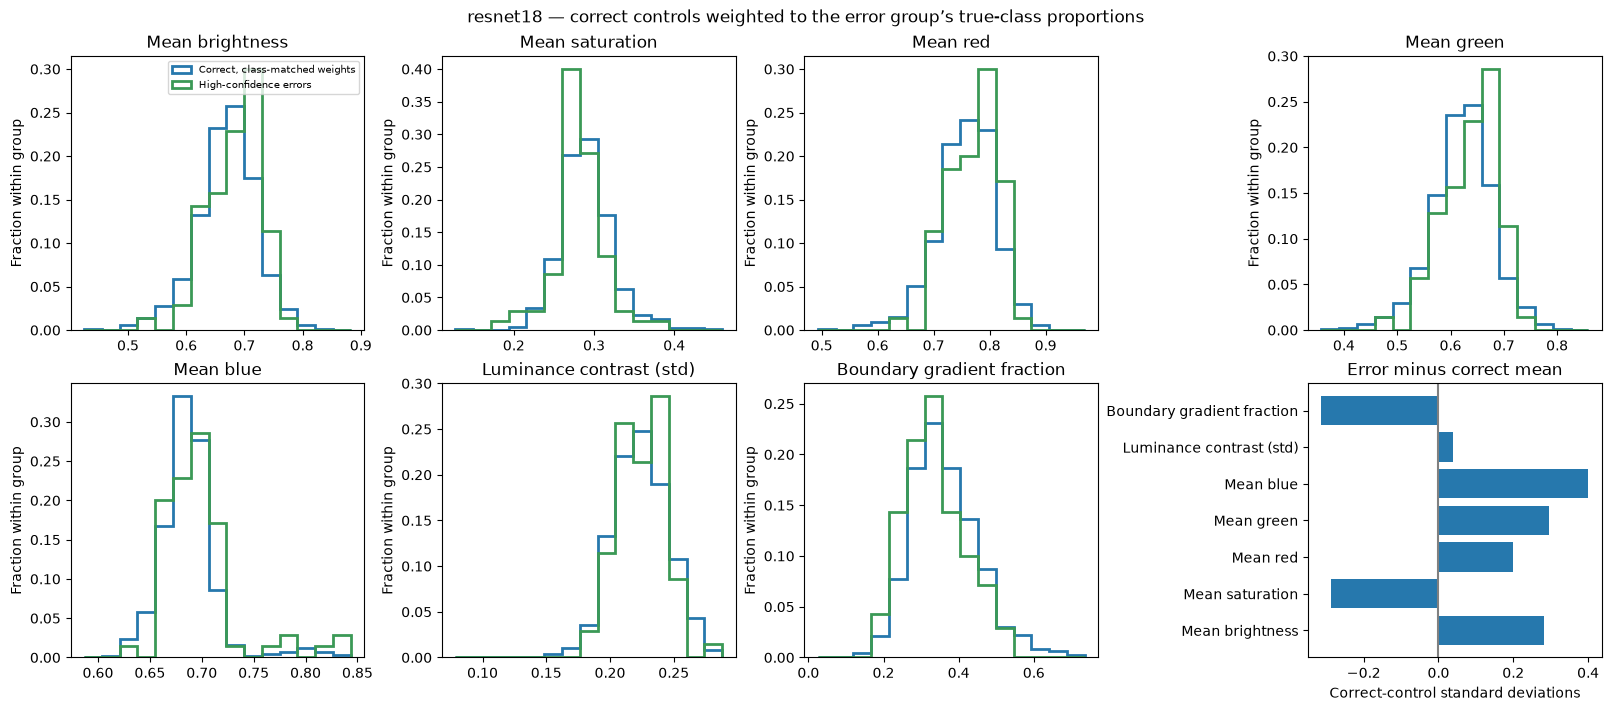

In [20]:
plot_feature_comparison(0)

Compare the feature distributions and standardized effects for ResNet18 errors against correct controls with the same true-class proportions. Errors have higher blue values by 0.40 control SD and lower saturation by 0.29 SD, with substantial overlap between groups. These are appearance associations worth testing, not features that explain or detect every error.

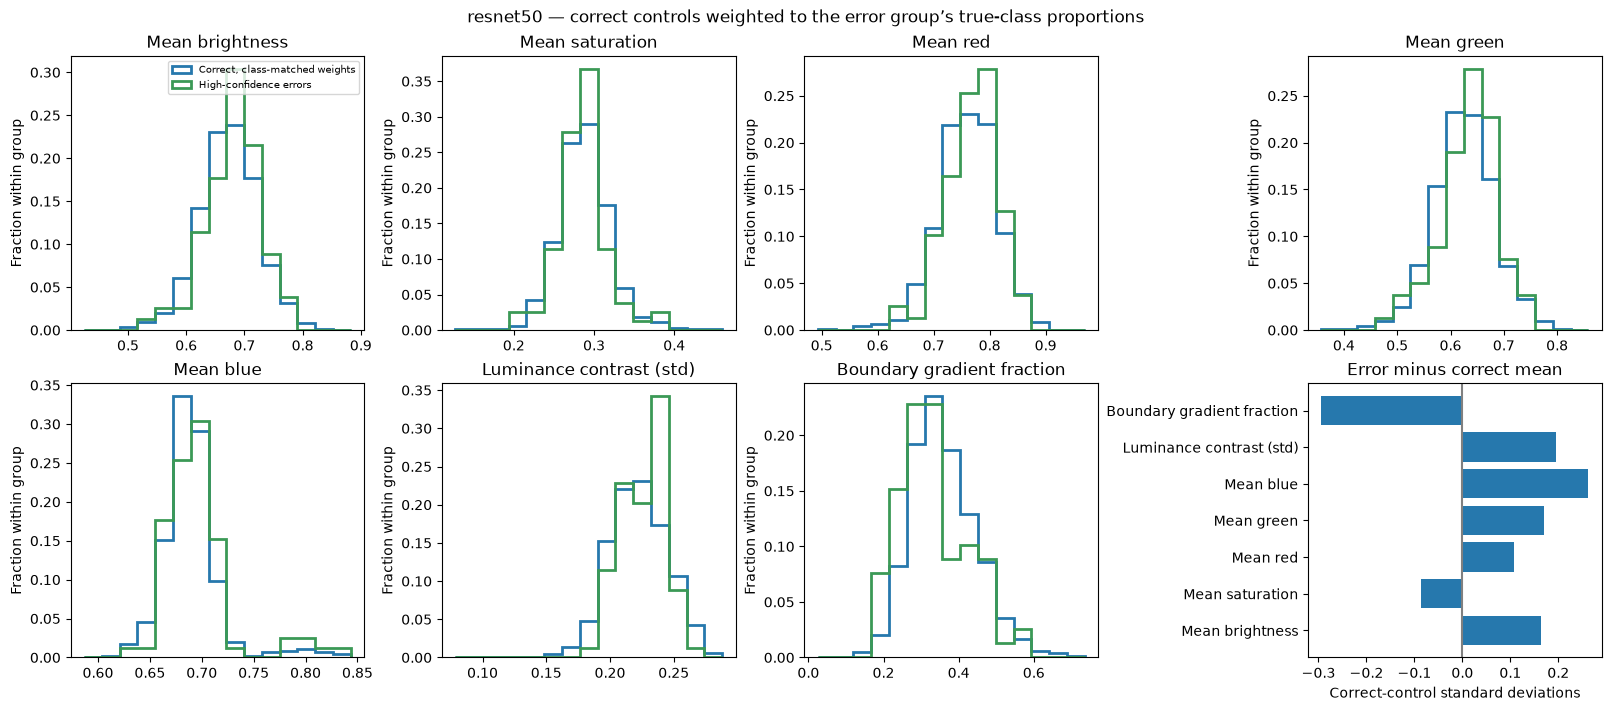

In [21]:
plot_feature_comparison(1)

Look for features that shift consistently between ResNet50 errors and class-weighted correct controls rather than isolated extreme images. Errors have modestly higher blue values by 0.26 control SD and lower boundary gradient fraction by 0.29 SD, without clear separation. The result suggests overlapping appearance differences, not a single error signature or evidence that an annotated cell lies near the border.

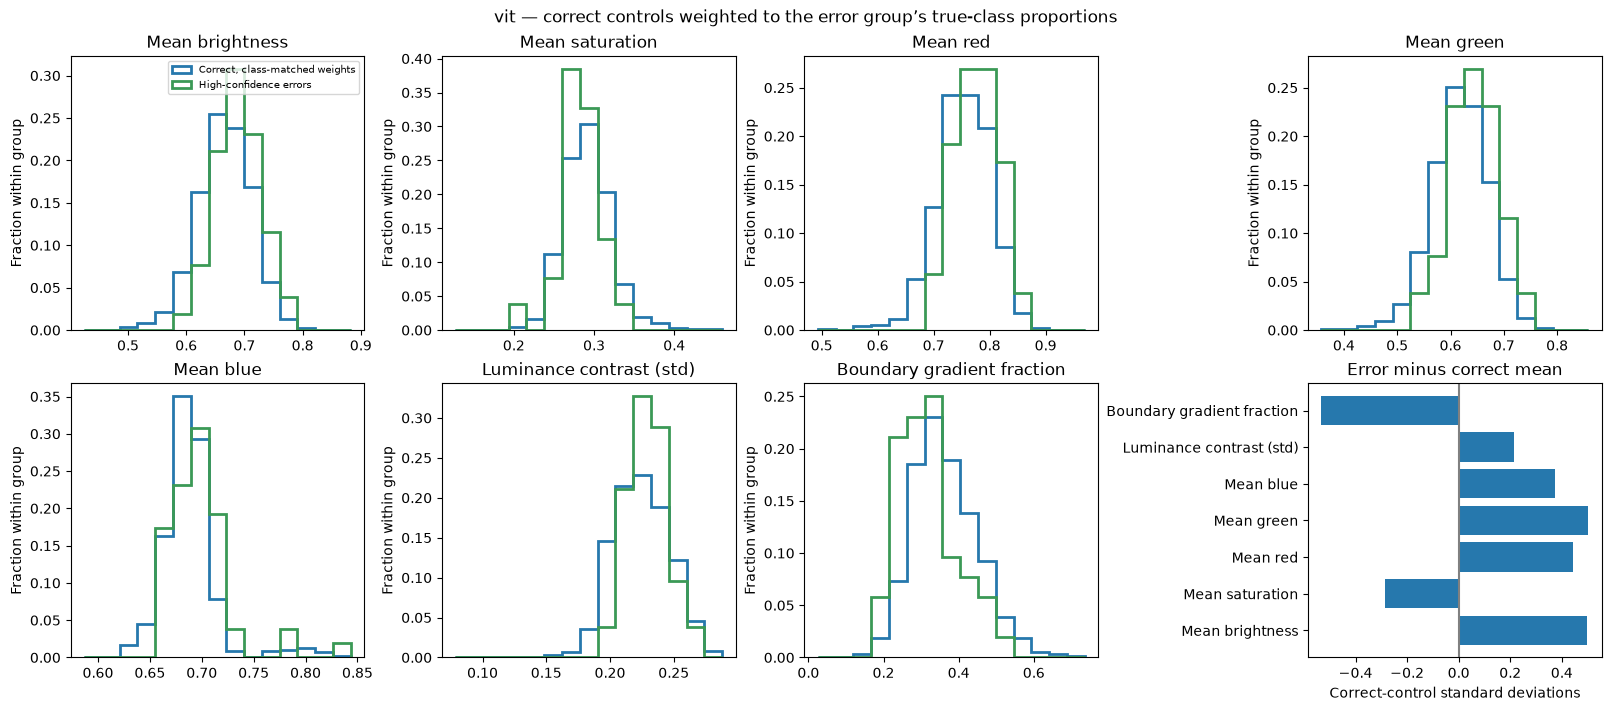

In [22]:
plot_feature_comparison(2)

Compare ViT error/control feature shifts after accounting for their true-class proportions. Errors are brighter by 0.50 control SD and have lower boundary gradient energy by 0.53 SD, while the distributions still overlap. Several related appearance properties may contribute to this association, so the pattern motivates controlled interventions rather than identifying an internal model mechanism.

## Nearest-image matches for the controlled galleries — raw RGB distance, restricted to the relevant true or predicted class

In [23]:
flat = rgb.reshape(len(images), -1).astype(np.float32)
squared = np.square(flat).sum(-1)
neighbor_ids, neighbor_rmse = [], []
for m, ids in enumerate(error_ids):
    distances = np.maximum(squared[:, None] + squared[ids][None, :] - 2 * flat @ flat[ids].T, 0) / flat.shape[1]
    matches, rmses = [], []
    for target in [labels[ids], predicted[m, ids]]:
        allowed = correct[m, :, None] & (confidence[m, :, None] >= threshold) & (labels[:, None] == target[None, :])
        assert allowed.any(axis=0).all(), 'No correct comparison image in a requested class'
        nearest = np.where(allowed, distances, np.inf).argmin(axis=0)
        matches.append(nearest)
        rmses.append(np.sqrt(distances[nearest, np.arange(len(ids))]))
    neighbor_ids.append(np.stack(matches))
    neighbor_rmse.append(np.stack(rmses))


## Load models for interventions — no training; saturation and occlusion act on original 28 × 28 RGB images

In [24]:
import torch
from PIL import Image, ImageEnhance
from transformers import ViTForImageClassification, ViTImageProcessor
from torchvision.models import resnet18
from models.resnet18.models import ResNet50

torch.manual_seed(42)
torch.backends.cudnn.benchmark = False
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
batch_size = 32
models = [resnet18(weights=None, num_classes=8), ResNet50(in_channels=3, num_classes=8)]
checkpoints = ['weights_bloodmnist/resnet18_224_1.pth', 'weights_bloodmnist/resnet50_28_1.pth', 'models/vit']
for model, path in zip(models, checkpoints):
    model.load_state_dict(torch.load(path, map_location='cpu', weights_only=True)['net'])
models.append(ViTForImageClassification.from_pretrained('models/vit', local_files_only=True))
models = [model.to(device).eval() for model in models]
processor = ViTImageProcessor.from_pretrained('models/vit', local_files_only=True)

@torch.inference_mode()
def predict(m, images):
    probabilities, scores = [], []
    for start in range(0, len(images), batch_size):
        batch = images[start:start + batch_size]
        if model_names[m] != 'vit':
            x = torch.from_numpy(batch.copy()).permute(0, 3, 1, 2).to(device).float()
            if model_names[m] == 'resnet18':
                x = torch.nn.functional.interpolate(x, size=(224, 224), mode='nearest')
            logits = models[m]((x / 255 - 0.5) / 0.5)
        else:
            inputs = processor(images=list(batch), return_tensors='pt').to(device)
            logits = models[m](**inputs).logits
        probabilities.append(logits.softmax(-1).cpu().numpy())
        scores.append(logits.cpu().numpy())
    return np.concatenate(probabilities), np.concatenate(scores)

def intervention_predict(m, batch_images):
    return predict(m, batch_images)[0]

for m, ids in enumerate(error_ids):
    if len(ids):
        np.testing.assert_allclose(intervention_predict(m, images[ids]), probabilities[m, ids], atol=1e-5, rtol=1e-4)


## Saturation intervention — HC errors versus nearest same-class correct ≥90%-confident controls; repeated controls are not independent samples

In [25]:
saturation_levels = np.linspace(0.5, 1.5, 11)
saturation_results, saturation_ids = [], []
saturation_cache = {}
if Path('predictions/high_confidence_error_analysis.npz').exists():
    with np.load('predictions/high_confidence_error_analysis.npz', allow_pickle=False) as saved:
        if np.array_equal(saved['baseline_probabilities'], probabilities) and np.array_equal(saved['saturation_levels'], saturation_levels):
            for m, name in enumerate(model_names):
                selected = np.stack((error_ids[m], neighbor_ids[m][0]))
                if np.array_equal(saved[f'{name}_saturation_ids'], selected):
                    saturation_cache[m] = saved[f'{name}_saturation_probabilities']
for m, ids in enumerate(error_ids):
    selected = np.stack((ids, neighbor_ids[m][0]))
    saturation_ids.append(selected)
    if not len(ids):
        saturation_results.append(np.empty((2, 11, 0, 8)))
        continue
    if m in saturation_cache:
        saturation_results.append(saturation_cache[m])
        continue
    inputs = images[selected.ravel()]
    values = []
    for level in saturation_levels:
        changed = np.stack([np.asarray(ImageEnhance.Color(Image.fromarray(image)).enhance(float(level))) for image in inputs])
        values.append(intervention_predict(m, changed).reshape(2, len(ids), 8))
    p = np.stack(values, axis=1)
    saturation_results.append(p)
    np.testing.assert_allclose(p[:, 5], probabilities[m, selected], atol=1e-5, rtol=1e-4)


def plot_saturation(m):
    ids, selected, p = error_ids[m], saturation_ids[m], saturation_results[m]
    original = probabilities[m, selected].argmax(-1)
    retained = np.take_along_axis(p, original[:, None, :, None], axis=-1)[..., 0]
    fig, axes = plt.subplots(2, 2, figsize=(13, 8), layout='constrained')
    for role, name in enumerate(['HC errors', 'Matched correct controls']):
        axes[0, 0].plot(saturation_levels, retained[role].mean(-1), 'o-', label=name)
        axes[0, 1].plot(saturation_levels, (p[role].argmax(-1) == labels[selected[role]]).mean(-1), 'o-', label=name)
        distribution = np.stack([(p[role].argmax(-1) == c).mean(-1) for c in range(8)])
        im = axes[1, role].imshow(distribution, vmin=0, vmax=1, cmap='Blues', aspect='auto')
        axes[1, role].set(title=name, yticks=range(8), yticklabels=class_names,
                          xticks=[0, 5, 10], xticklabels=['0.5', '1.0', '1.5'], xlabel='Saturation factor')
    axes[0, 0].set(title='Support for each original decision', ylabel='Mean probability')
    axes[0, 1].set(title='Fraction selecting the recorded true class', ylabel='Fraction')
    for ax in axes[0]:
        ax.axvline(1, color='gray', ls='--')
        ax.set_xlabel('Saturation factor')
        ax.legend(fontsize=8)
    fig.colorbar(im, ax=axes[1], label='Fraction assigned to each class')
    fig.suptitle(f'{model_names[m]} · same-class paired cohorts · N={len(ids)}')
    plt.show()


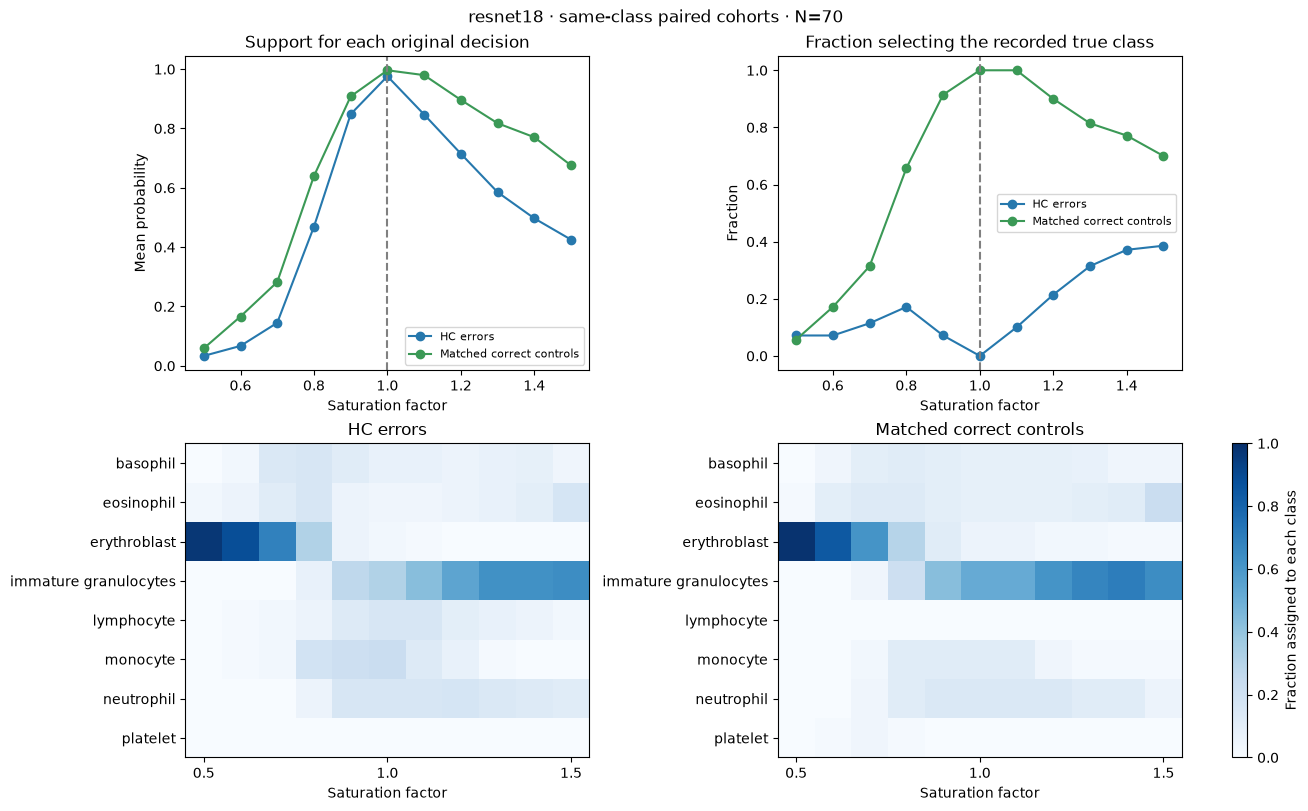

In [26]:
plot_saturation(0)

Compare the destination-class distributions of errors and matched correct controls as saturation decreases. At saturation ×0.5, ResNet18 assigns erythroblast to 68/70 error images and 69/70 controls despite their different original decisions. This shared class collapse indicates dependence on saturation-related appearance, not an effect specific to originally wrong images.

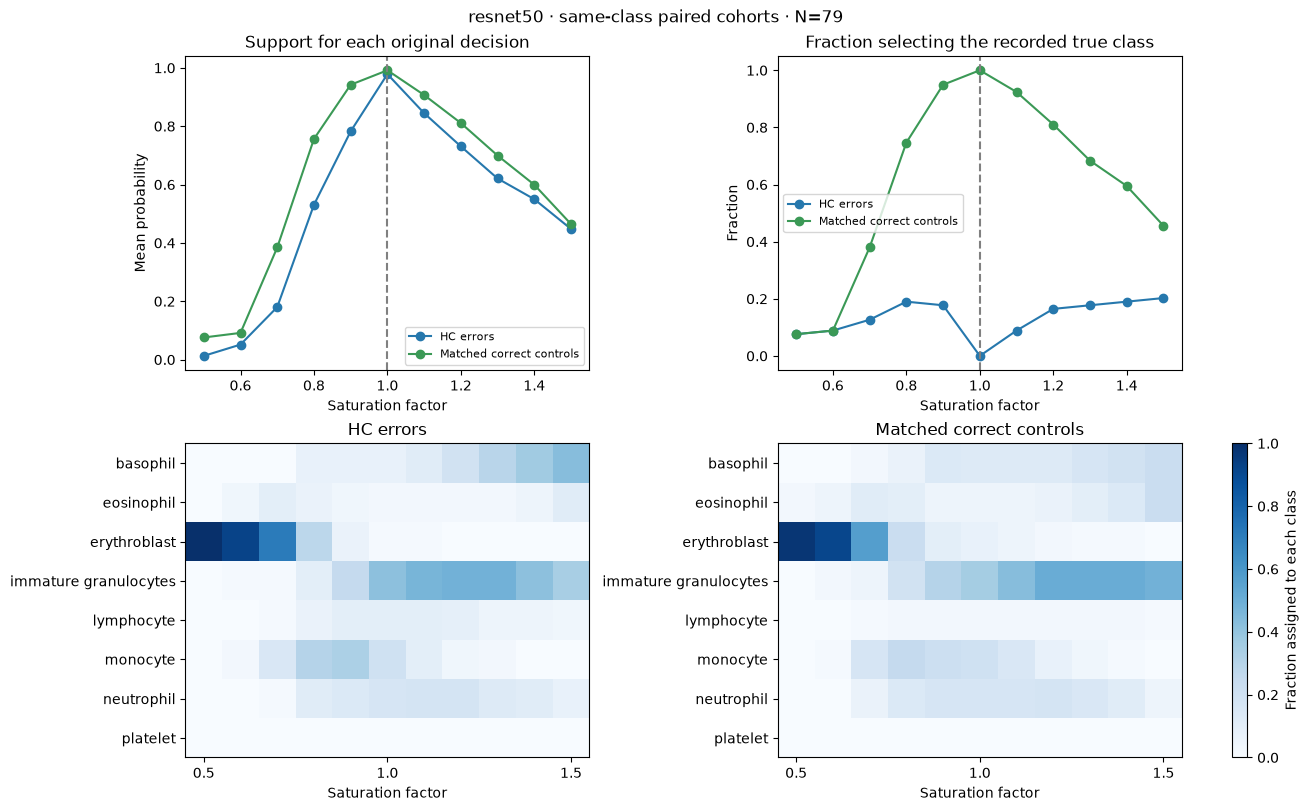

In [27]:
plot_saturation(1)

Check whether desaturation sends ResNet50 errors and same-class correct controls toward the same destination class. At saturation ×0.5, all 79 errors and 77/79 controls are assigned to erythroblast. Because the cohorts have identical true-class composition, this convergence indicates a color-dependent class-attractor response rather than a selective correction of the original errors.

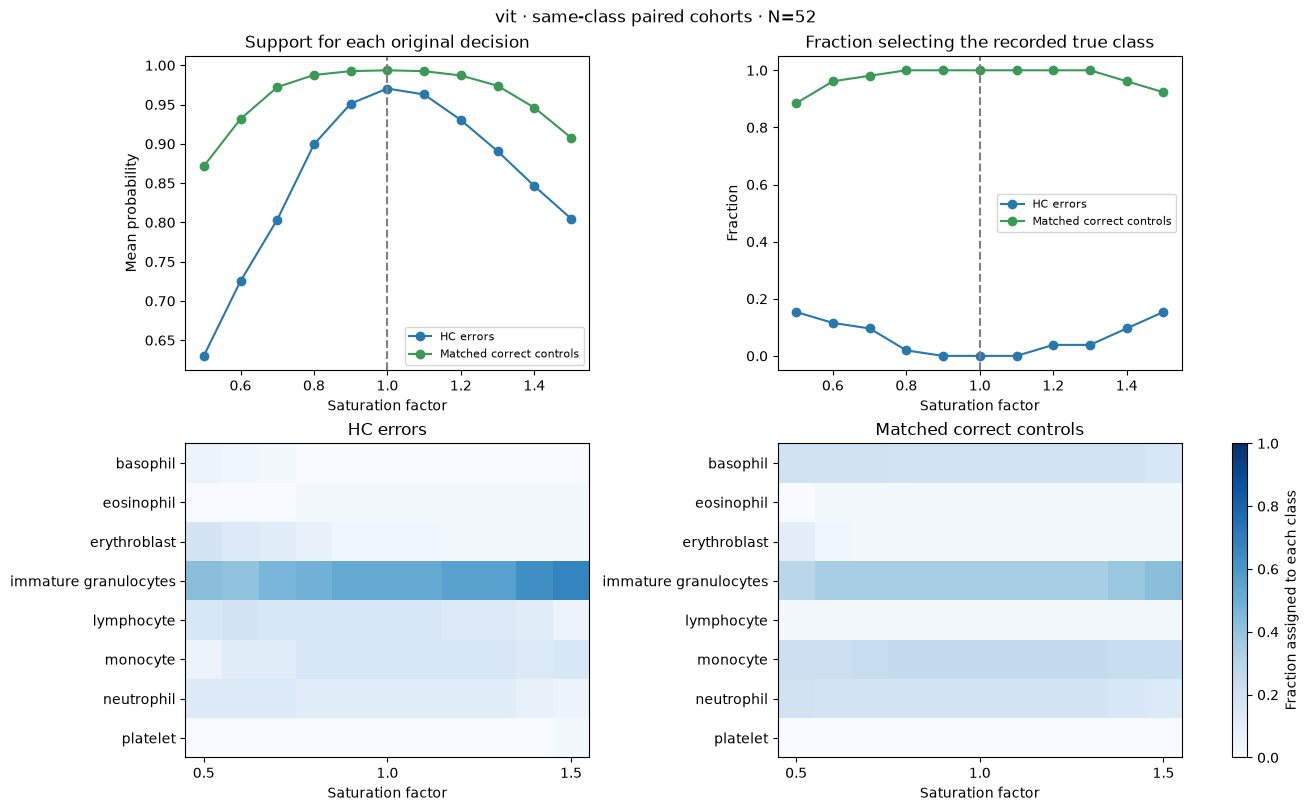

In [28]:
plot_saturation(2)

Compare ViT’s original-decision probability curves for errors and controls alongside the destination-class distributions. At saturation ×0.5, original-decision support drops by 0.340 for errors versus 0.122 for controls, without the near-complete erythroblast collapse seen in the CNNs. ViT therefore shows more error-specific saturation dependence in these cohorts, although the intervention does not identify which internal feature caused the original mistakes.

## Model-wide occlusion — all 3,421 test images, all classes and confidence levels

Each model receives the same 49 gray 4×4 patches before its usual preprocessing. The original predicted class is held fixed when measuring probability loss. Accuracy change uses the complete test population; the high-confidence-error analysis below is a separate conditional view.

In [29]:
import hashlib
from numpy.lib.format import open_memmap

patch_size = 4
positions = np.array([(y, x) for y in range(0, 28, patch_size) for x in range(0, 28, patch_size)])
files = [*checkpoints[:2], 'models/vit/model.safetensors', 'models/vit/config.json', 'models/vit/preprocessor_config.json']
weight_hashes = [hashlib.sha256(Path(path).read_bytes()).hexdigest() for path in files]
signature = hashlib.sha256(images.tobytes() + labels.tobytes() + probabilities.tobytes() + positions.tobytes()
                           + str(weight_hashes).encode() + b'gray128_resnet18-nearest224_resnet50-28_vit-local_v1').hexdigest()
population_path = Path('predictions/occlusion_test.npz')
if not population_path.exists():
    cache = Path('outputs/occlusion_test_v1')
    cache.mkdir(parents=True, exist_ok=True)
    lock = cache / 'signature.txt'
    assert not lock.exists() or lock.read_text() == signature, 'Inputs changed: use a new cache directory.'
    lock.write_text(signature)
    arrays = []
    for filename, shape, dtype in [('probabilities.npy', (3, 49, len(images), 8), 'float32'),
                                    ('logits.npy', (3, 49, len(images), 8), 'float32'), ('done.npy', (3, 49), 'bool')]:
        path = cache / filename
        fresh = not path.exists()
        array = open_memmap(path, mode='w+' if fresh else 'r+', dtype=dtype, shape=shape)
        if fresh and dtype == 'bool':
            array[:] = False
            array.flush()
        arrays.append(array)
    population_p, population_logits, done = arrays
    for m, name in enumerate(model_names):
        np.testing.assert_allclose(predict(m, images[:64])[0], probabilities[m, :64], atol=1e-5, rtol=1e-4)
        for j, (y, x) in enumerate(positions):
            if done[m, j]:
                continue
            changed = images.copy()
            changed[:, y:y + patch_size, x:x + patch_size] = 128
            population_p[m, j], population_logits[m, j] = predict(m, changed)
            population_p.flush()
            population_logits.flush()
            done[m, j] = True
            done.flush()
        print(f'{name}: all {len(images)} test images × 49 patch positions completed')
    np.savez_compressed(population_path, probabilities=population_p, logits=population_logits,
                        sample_index=np.arange(len(images)), labels=labels, baseline_probabilities=probabilities,
                        model_names=model_names, checkpoints=checkpoints, weight_hashes=weight_hashes,
                        class_names=class_names, positions=positions, patch_size=patch_size, fill_rgb=[128]*3,
                        signature=signature, split='test', axes=['model', 'patch', 'image', 'class'])
with np.load(population_path, allow_pickle=False) as saved:
    assert str(saved['signature']) == signature, 'Cached experiment does not match current inputs.'
    population_p = saved['probabilities']
print(f'Model-wide occlusion: {len(images)} shared test images per model; no confidence filtering')


Model-wide occlusion: 3421 shared test images per model; no confidence filtering


In [30]:
population_prediction = population_p.argmax(-1)
population_original = np.take_along_axis(population_p, predicted[:, None, :, None], axis=-1)[..., 0]
population_drop = (confidence[:, None] - population_original).transpose(0, 2, 1).reshape(3, len(labels), 7, 7)
population_correct = population_prediction == labels
population_before = predicted == labels
population_maps = {
    'Original-decision probability drop': population_drop.mean(1),
    'Label flip fraction': (population_prediction != predicted[:, None]).mean(-1).reshape(3, 7, 7),
    'Accuracy change (percentage points)': 100 * (population_correct.mean(-1) - population_before.mean(-1)[:, None]).reshape(3, 7, 7),
}
population_class_drop = np.stack([population_drop[:, labels == c].mean(1) for c in range(8)], axis=1)
population_group_difference = np.full((3, 8, 7, 7), np.nan)
population_group_counts = np.zeros((3, 8, 2), dtype=int)
for m in range(3):
    for c in range(8):
        right = (labels == c) & population_before[m]
        wrong = (labels == c) & ~population_before[m]
        population_group_counts[m, c] = [wrong.sum(), right.sum()]
        if wrong.any() and right.any():
            population_group_difference[m, c] = population_drop[m, wrong].mean(0) - population_drop[m, right].mean(0)

def plot_population_overview():
    fig, axes = plt.subplots(3, 3, figsize=(13, 11), layout='constrained')
    for col, (title, maps) in enumerate(population_maps.items()):
        signed = col != 1
        scale = max(np.abs(maps).max(), 0.01)
        for m, ax in enumerate(axes[:, col]):
            im = ax.imshow(maps[m], cmap='RdBu_r' if signed else 'viridis', vmin=-scale if signed else 0, vmax=scale)
            ax.set(title=f'{model_names[m]} · {title}', xticks=[], yticks=[])
        fig.colorbar(im, ax=axes[:, col], shrink=0.7)
    fig.suptitle('Model-wide occlusion · all 3,421 test images · same 49 gray patches for every model')
    plt.show()

def plot_population_classes(difference=False):
    maps = population_group_difference if difference else population_class_drop
    limit = max(np.nanmax(np.abs(maps)), 0.01)
    fig, axes = plt.subplots(3, 8, figsize=(23, 10), layout='constrained')
    for m in range(3):
        for c, ax in enumerate(axes[m]):
            im = ax.imshow(maps[m, c], cmap='RdBu_r', vmin=-limit, vmax=limit)
            count = f'wrong/right: {population_group_counts[m, c, 0]}/{population_group_counts[m, c, 1]}' if difference else f'N={(labels == c).sum()}'
            ax.set(title=f'{class_names[c]} · {count}', xticks=[], yticks=[])
            if difference and not np.isfinite(maps[m, c]).any():
                ax.text(0.5, 0.5, 'No initial errors', ha='center', transform=ax.transAxes)
        axes[m, 0].set_ylabel(model_names[m])
    fig.colorbar(im, ax=axes, shrink=0.7, label='Wrong minus correct decision-support drop' if difference else 'Mean original-decision probability drop')
    fig.suptitle('Within-class comparison: initially wrong minus initially correct' if difference else 'All test images, grouped by true class')
    plt.show()


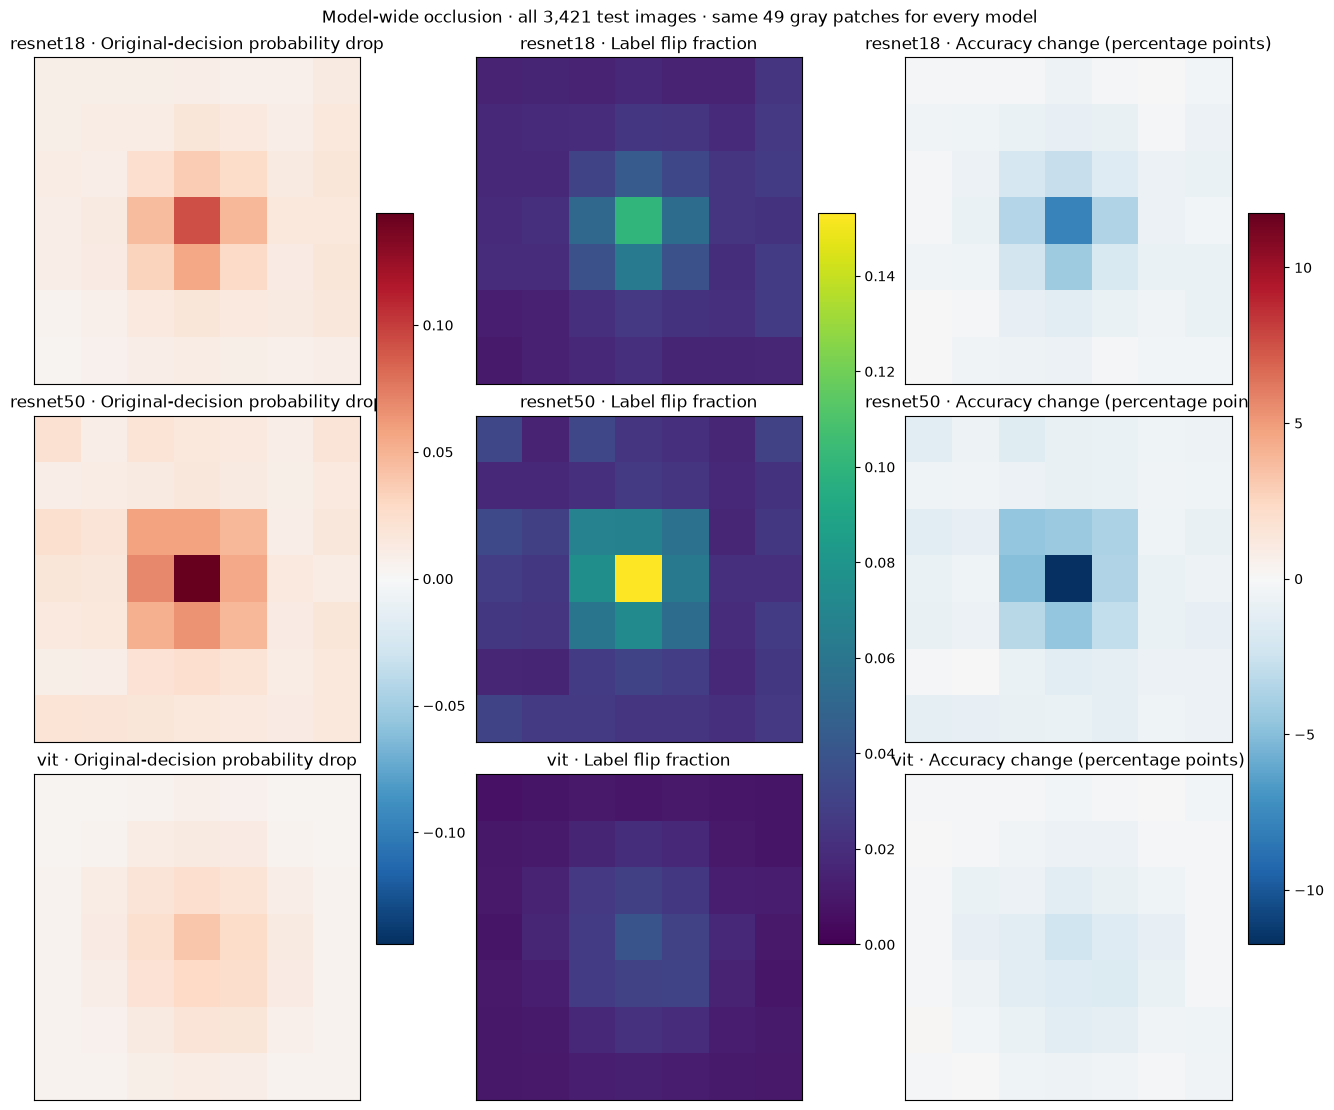

In [31]:
plot_population_overview()

Compare central and outer patches in the original-decision probability maps, using accuracy change separately to assess net correctness. Central/outer mean drops are 0.043/0.011 for ResNet18, 0.066/0.015 for ResNet50 and 0.025/0.008 for ViT. All models depend more on central image content, but these fixed coordinates in centered crops do not identify a nucleus or an attention mechanism.

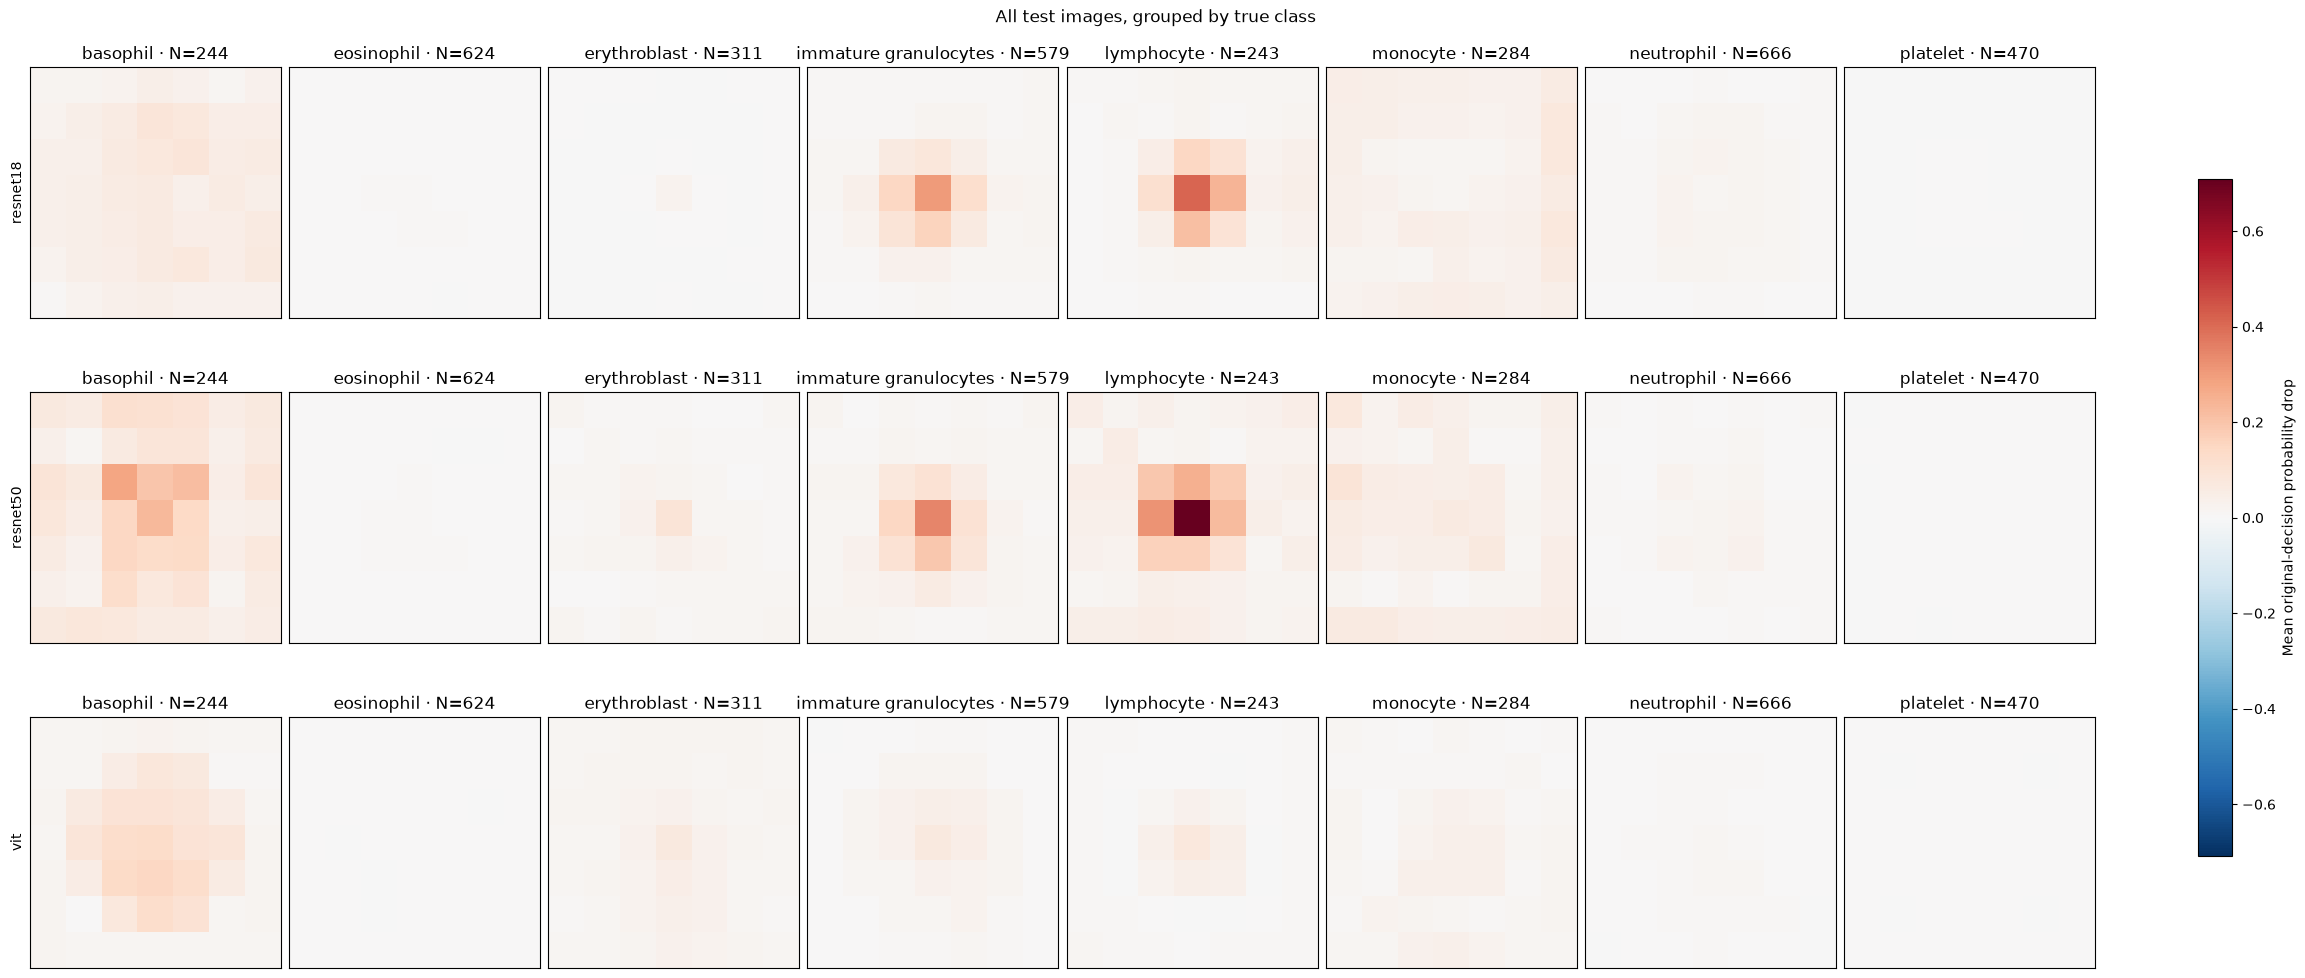

In [32]:
plot_population_classes()

Compare patch responses between true-class rows within each model, with each row averaged over its own images. ResNet50’s mean probability drop is 0.085 for basophils versus 0.009 for neutrophils, with almost no change for platelets. The population average therefore combines class-specific spatial dependencies rather than one common occlusion response.

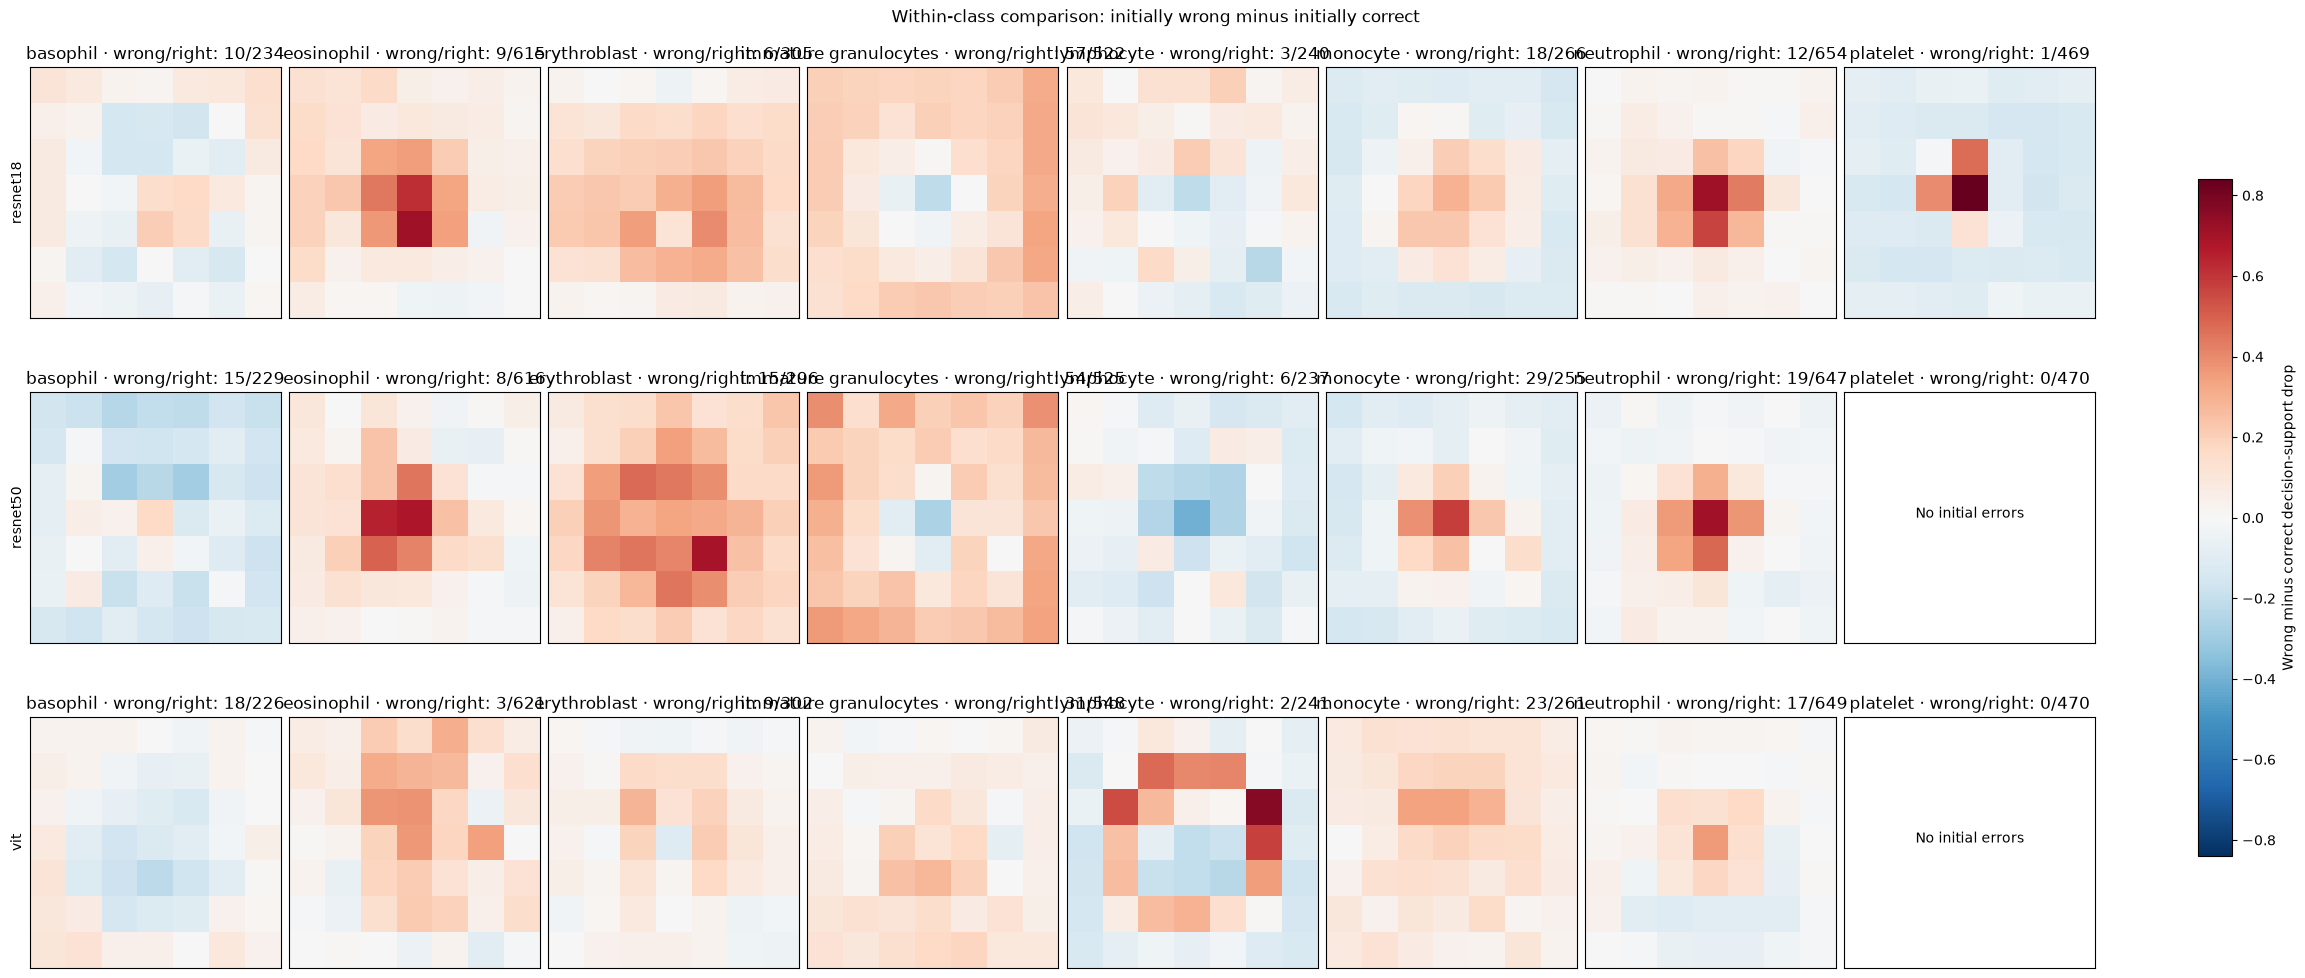

In [33]:
plot_population_classes(difference=True)

Read positive wrong-minus-correct probability-drop values as stronger dependence among original errors within the same true class. ResNet50’s central contrast is +0.212 for monocytes but −0.088 for basophils. Error-related spatial dependence therefore differs by class rather than increasing uniformly, and the matched HC comparison below checks a subgroup with more comparable starting confidence.

## High-confidence-error occlusion — conditional subgroup only; the model-wide population analysis is above

In [34]:
# Reuse the full-test predictions, retaining the original subgroup data format.
patch_size = 4
positions = np.array([(y, x) for y in range(0, 28, patch_size) for x in range(0, 28, patch_size)])
occlusion_results, occlusion_drop = [], []
for m, ids in enumerate(error_ids):
    p = population_p[m][:, ids].copy()
    occlusion_results.append(p)
    target = np.take_along_axis(p, predicted[m, ids][None, :, None], axis=-1)[..., 0]
    occlusion_drop.append((confidence[m, ids][None] - target).T.reshape(len(ids), 7, 7))


## Occlusion aggregated by true class and model — all high-confidence errors; original-decision drop and paired error-minus-control contrast; N = images, not patches; fixed image coordinates are not aligned cell structures

In [35]:
occlusion_counts = np.zeros((len(model_names), 8), dtype=int)
occlusion_class_metrics = {name: np.full((len(model_names), 8, 7, 7), np.nan) for name in
                           ['Mean wrong-class probability drop', 'Mean absolute probability change', 'Fraction corrected']}
for m, ids in enumerate(error_ids):
    patch_predictions = occlusion_results[m].argmax(-1).T.reshape(len(ids), 7, 7)
    corrected = patch_predictions == labels[ids, None, None]
    for c in range(8):
        mask = labels[ids] == c
        occlusion_counts[m, c] = mask.sum()
        if mask.any():
            occlusion_class_metrics['Mean wrong-class probability drop'][m, c] = occlusion_drop[m][mask].mean(0)
            occlusion_class_metrics['Mean absolute probability change'][m, c] = np.abs(occlusion_drop[m][mask]).mean(0)
            occlusion_class_metrics['Fraction corrected'][m, c] = corrected[mask].mean(0)
            print(f'{model_names[m]} · {class_names[c]} · N={mask.sum()} · mean absolute effect={np.abs(occlusion_drop[m][mask]).mean():.3f} · correction fraction across patches={corrected[mask].mean():.1%}')

occlusion_matched_ids = [np.stack((ids, neighbor_ids[m][0])) for m, ids in enumerate(error_ids)]
paired = np.full((3, 8, 7, 7), np.nan)
for m, selected in enumerate(occlusion_matched_ids):
    for c in range(8):
        mask = labels[selected[0]] == c
        if mask.any():
            paired[m, c] = (population_drop[m, selected[0, mask]] - population_drop[m, selected[1, mask]]).mean(0)
occlusion_class_metrics['Error minus matched-control probability drop'] = paired

def plot_occlusion_summary(title):
    maps = occlusion_class_metrics[title]
    signed = title != 'Mean absolute probability change' and title != 'Fraction corrected'
    limit = 1 if title == 'Fraction corrected' else max(np.nanmax(np.abs(maps)), 0.01)
    fig, axes = plt.subplots(len(model_names), 8, figsize=(23, 3.5 * len(model_names)), layout='constrained')
    for m in range(len(model_names)):
        for c, ax in enumerate(axes[m]):
            if occlusion_counts[m, c]:
                im = ax.imshow(maps[m, c], cmap='RdBu_r' if signed else 'viridis',
                               vmin=-limit if signed else 0, vmax=limit)
            else:
                ax.set_facecolor('#eeeeee')
                ax.text(0.5, 0.5, 'No images', ha='center', va='center', transform=ax.transAxes)
            ax.set_title(f'{class_names[c]} (N={occlusion_counts[m, c]})', fontsize=8, wrap=True)
            ax.set_xticks([])
            ax.set_yticks([])
        axes[m, 0].set_ylabel(model_names[m])
    fig.colorbar(im, ax=axes, shrink=0.65, label=title)
    fig.suptitle(f'{title} — each square covers 4 × 4 pixels; small classes are descriptive, not reliable comparisons')
    plt.show()

resnet18 · basophil · N=6 · mean absolute effect=0.136 · correction fraction across patches=1.7%
resnet18 · eosinophil · N=6 · mean absolute effect=0.092 · correction fraction across patches=6.8%
resnet18 · erythroblast · N=4 · mean absolute effect=0.075 · correction fraction across patches=5.6%
resnet18 · immature granulocytes · N=36 · mean absolute effect=0.123 · correction fraction across patches=9.0%
resnet18 · monocyte · N=8 · mean absolute effect=0.061 · correction fraction across patches=4.1%
resnet18 · neutrophil · N=10 · mean absolute effect=0.072 · correction fraction across patches=6.1%
resnet50 · basophil · N=10 · mean absolute effect=0.075 · correction fraction across patches=0.6%
resnet50 · eosinophil · N=4 · mean absolute effect=0.103 · correction fraction across patches=5.1%
resnet50 · erythroblast · N=6 · mean absolute effect=0.136 · correction fraction across patches=12.6%
resnet50 · immature granulocytes · N=28 · mean absolute effect=0.147 · correction fraction acros

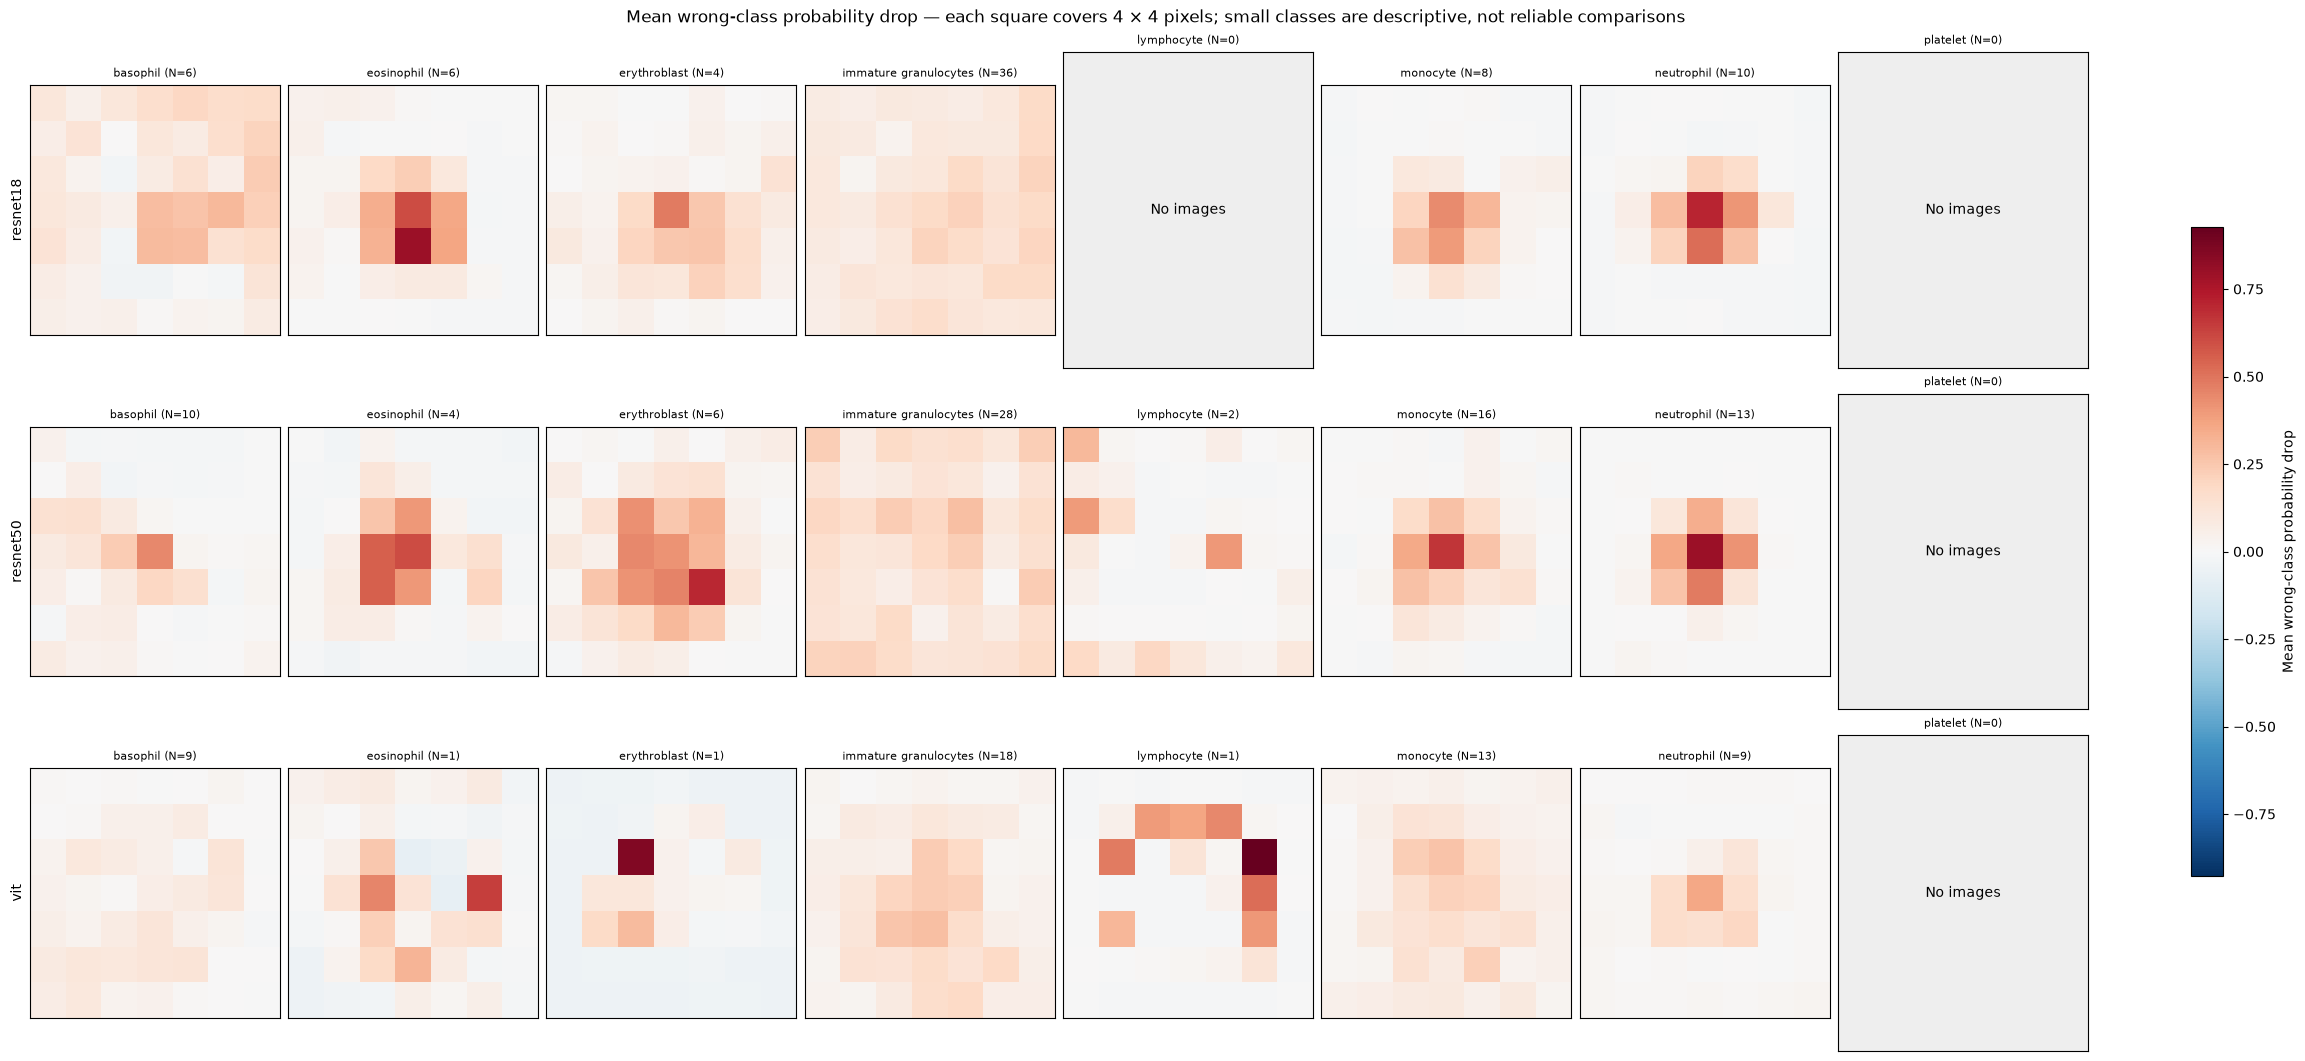

In [36]:
plot_occlusion_summary('Mean wrong-class probability drop')

Read larger positive values as a greater loss of support for the original wrong decision under that patch. Central mean drops among HC errors are 0.204 for ResNet18, 0.239 for ResNet50 and 0.156 for ViT. These maps localize support for wrong decisions, while the paired contrast below tests whether the same locations matter more than they do for correct decisions.

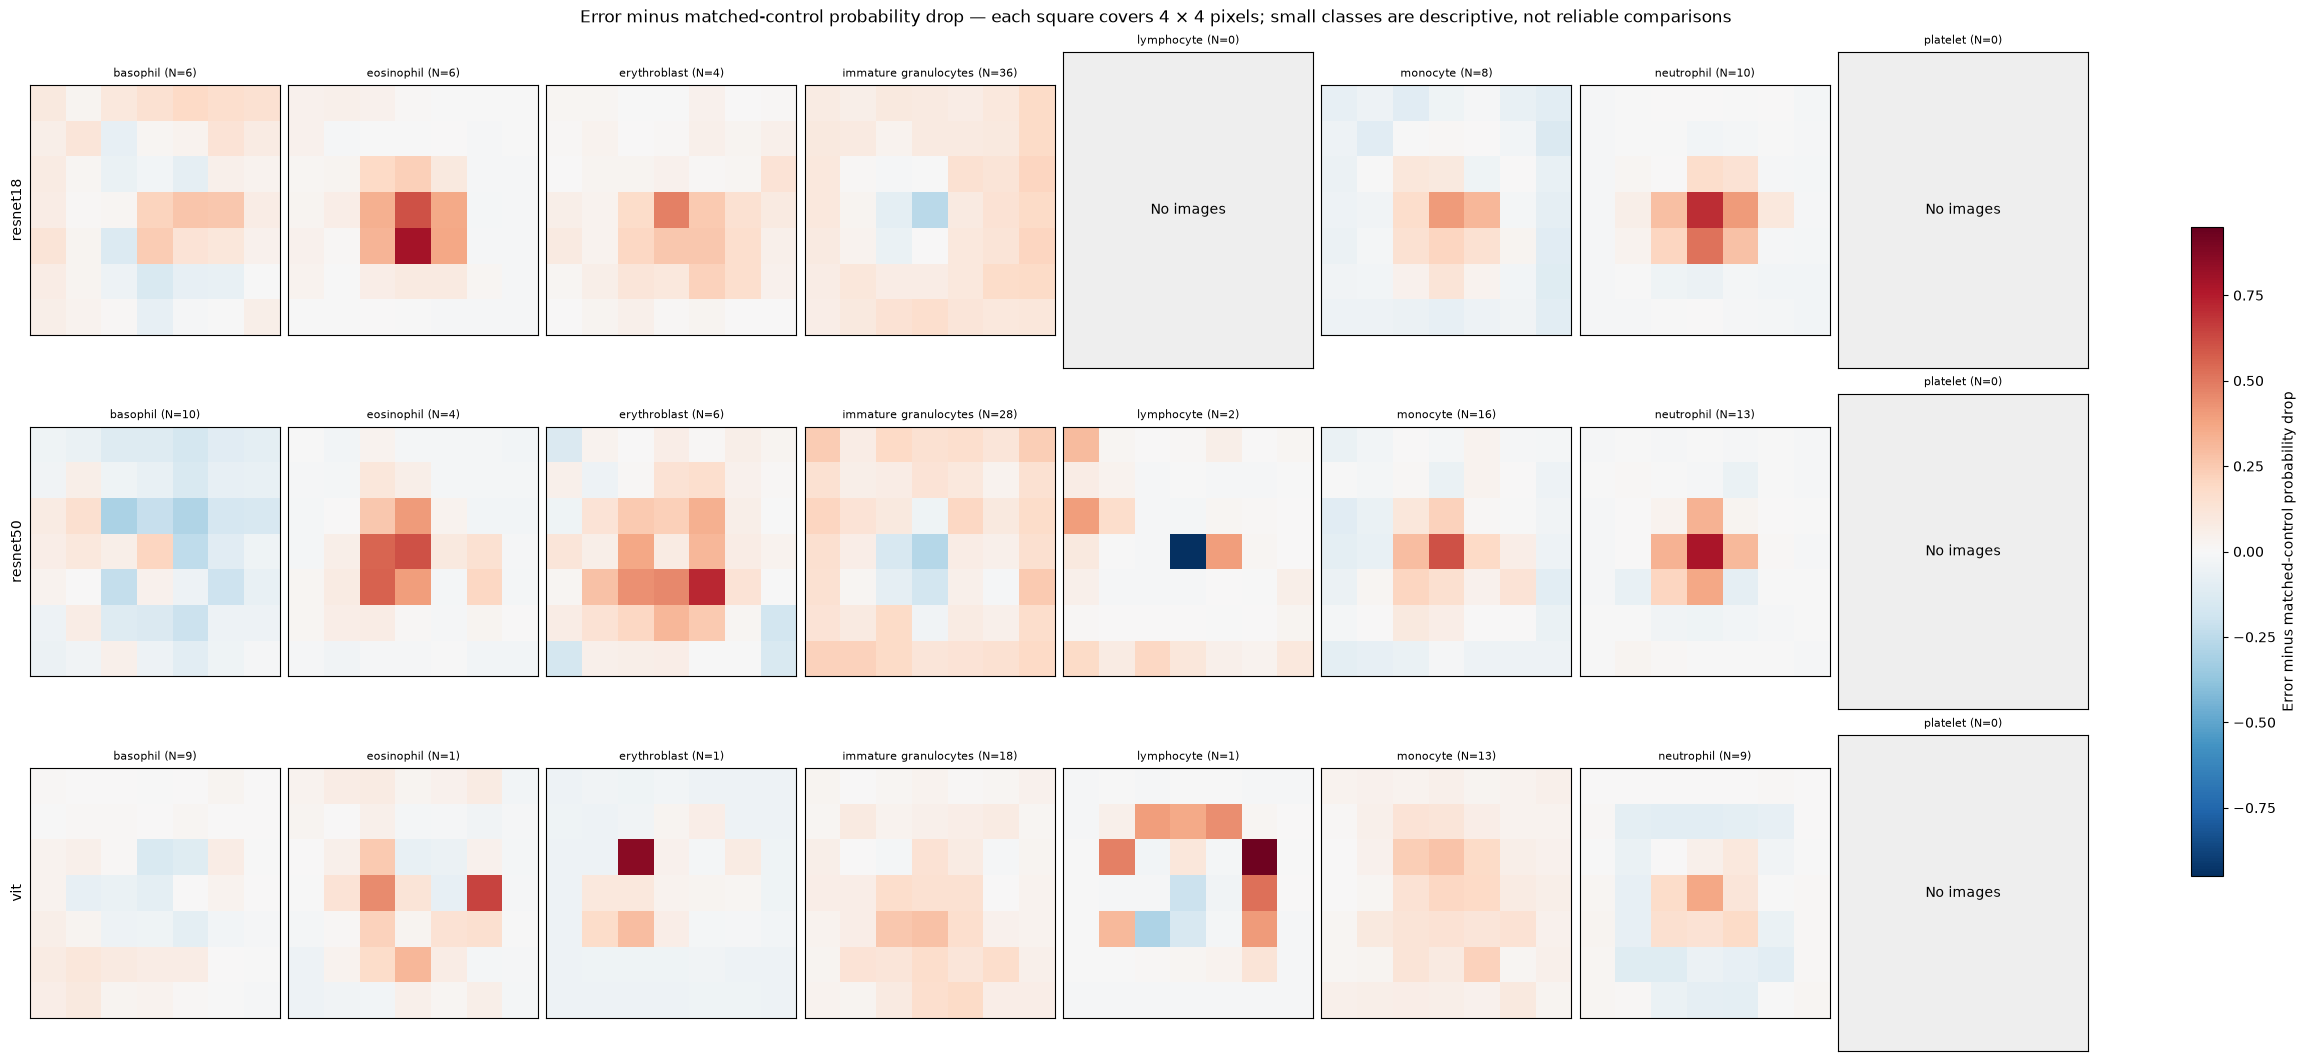

In [37]:
plot_occlusion_summary('Error minus matched-control probability drop')

Read positive error-minus-control values as locations where HC errors lose more original-decision support than their matched correct controls. The additional central drops are 0.104 for ResNet18, 0.098 for ResNet50 and 0.113 for ViT. HC errors therefore show stronger central dependence even after matching true class and the confidence threshold, although each image targets its own original decision and exact confidence is not matched.

## Save all high-confidence-error analysis data — all examples and all intervention probabilities, not just the displayed selections

In [38]:
analysis = dict(shared_indices=shared, union_indices=union, threshold=threshold, split='test',
                model_names=model_names, class_names=class_names, features=features, feature_names=feature_names,
                checkpoints=checkpoints, model_input_resolutions=[224, 28, 224],
                pair_overlap=pair_overlap, pair_jaccard=pair_jaccard,
                feature_sample_index=np.arange(len(labels)), true_labels=labels, baseline_probabilities=probabilities,
                control_weights=np.stack(control_weights), feature_effects=np.stack(feature_effects),
                saturation_levels=saturation_levels, occlusion_positions=positions, patch_size=patch_size,
                occlusion_fill_rgb=[128, 128, 128], neighbor_roles=['true_class', 'predicted_class'],
                saturation_roles=['high_confidence_errors', 'matched_correct_controls'],
                occlusion_class_counts=occlusion_counts, occlusion_grouping='true_class',
                **{f'occlusion_class_{name}': maps for name, maps in occlusion_class_metrics.items()})
for m, name in enumerate(model_names):
    for key, value in dict(error_ids=error_ids[m], confusion=confusions[m], selected_examples=example_ids[m],
                           neighbor_ids=neighbor_ids[m], neighbor_rmse=neighbor_rmse[m],
                           saturation_ids=saturation_ids[m], saturation_probabilities=saturation_results[m],
                           occlusion_probabilities=occlusion_results[m], occlusion_drop=occlusion_drop[m]).items():
        analysis[f'{name}_{key}'] = value
    if len(error_ids[m]):
        j = np.abs(feature_effects[m]).argmax()
        corrections = (saturation_results[m][0].argmax(-1) == labels[error_ids[m]]).sum(-1)
        print(f'{name}: largest descriptive feature shift: {feature_names[j]} ({feature_effects[m][j]:+.2f} control SD)')
        control_errors = (saturation_results[m][1].argmax(-1) != labels[saturation_ids[m][1]]).sum(-1)
        print('Saturation factor / corrected errors / newly wrong matched control pairs:', list(zip(saturation_levels.round(2).tolist(), corrections.tolist(), control_errors.tolist())))
        involved = ((labels[error_ids[m]] == 3) | (predicted[m, error_ids[m]] == 3)).sum()
        print(f'{name}: immature granulocytes occur on either side of {involved}/{len(error_ids[m])} error pairs')
        print(f'{name}: mean largest wrong-class probability drop per image under occlusion: {occlusion_drop[m].max((1, 2)).mean():.3f}')
path = Path('predictions/high_confidence_error_analysis.npz')
np.savez_compressed(path, **analysis)
print(path)
print('Hypotheses to investigate: appearance/staining sensitivity in a subset of errors; visual ambiguity around immature-granulocyte confusions. Saturation can also damage correct controls, so correction counts alone are not evidence of improvement.')
print('Exploratory only: correlated color features, class composition, pixel alignment, unequal neighbor-pool sizes and artificial interventions prevent causal or biological conclusions. Validate hypotheses on new images, not these selected errors.')

resnet18: largest descriptive feature shift: Mean blue (+0.40 control SD)
Saturation factor / corrected errors / newly wrong matched control pairs: [(0.5, 5, 66), (0.6, 5, 58), (0.7, 8, 48), (0.8, 12, 24), (0.9, 5, 6), (1.0, 0, 0), (1.1, 7, 0), (1.2, 15, 7), (1.3, 22, 13), (1.4, 26, 16), (1.5, 27, 21)]
resnet18: immature granulocytes occur on either side of 58/70 error pairs
resnet18: mean largest wrong-class probability drop per image under occlusion: 0.682
resnet50: largest descriptive feature shift: Boundary gradient fraction (-0.29 control SD)
Saturation factor / corrected errors / newly wrong matched control pairs: [(0.5, 6, 73), (0.6, 7, 72), (0.7, 10, 49), (0.8, 15, 20), (0.9, 14, 4), (1.0, 0, 0), (1.1, 7, 6), (1.2, 13, 15), (1.3, 14, 25), (1.4, 15, 32), (1.5, 16, 43)]
resnet50: immature granulocytes occur on either side of 61/79 error pairs
resnet50: mean largest wrong-class probability drop per image under occlusion: 0.761
vit: largest descriptive feature shift: Boundary gradi

## A · Shared and exclusive errors — all 39 shared errors; mark cases with ≥90% confidence in every model; class IDs listed below

Shared errors: 39 with ≥90% confidence in all models: 18
Classes: {0: np.str_('basophil'), 1: np.str_('eosinophil'), 2: np.str_('erythroblast'), 3: np.str_('immature granulocytes'), 4: np.str_('lymphocyte'), 5: np.str_('monocyte'), 6: np.str_('neutrophil'), 7: np.str_('platelet')}


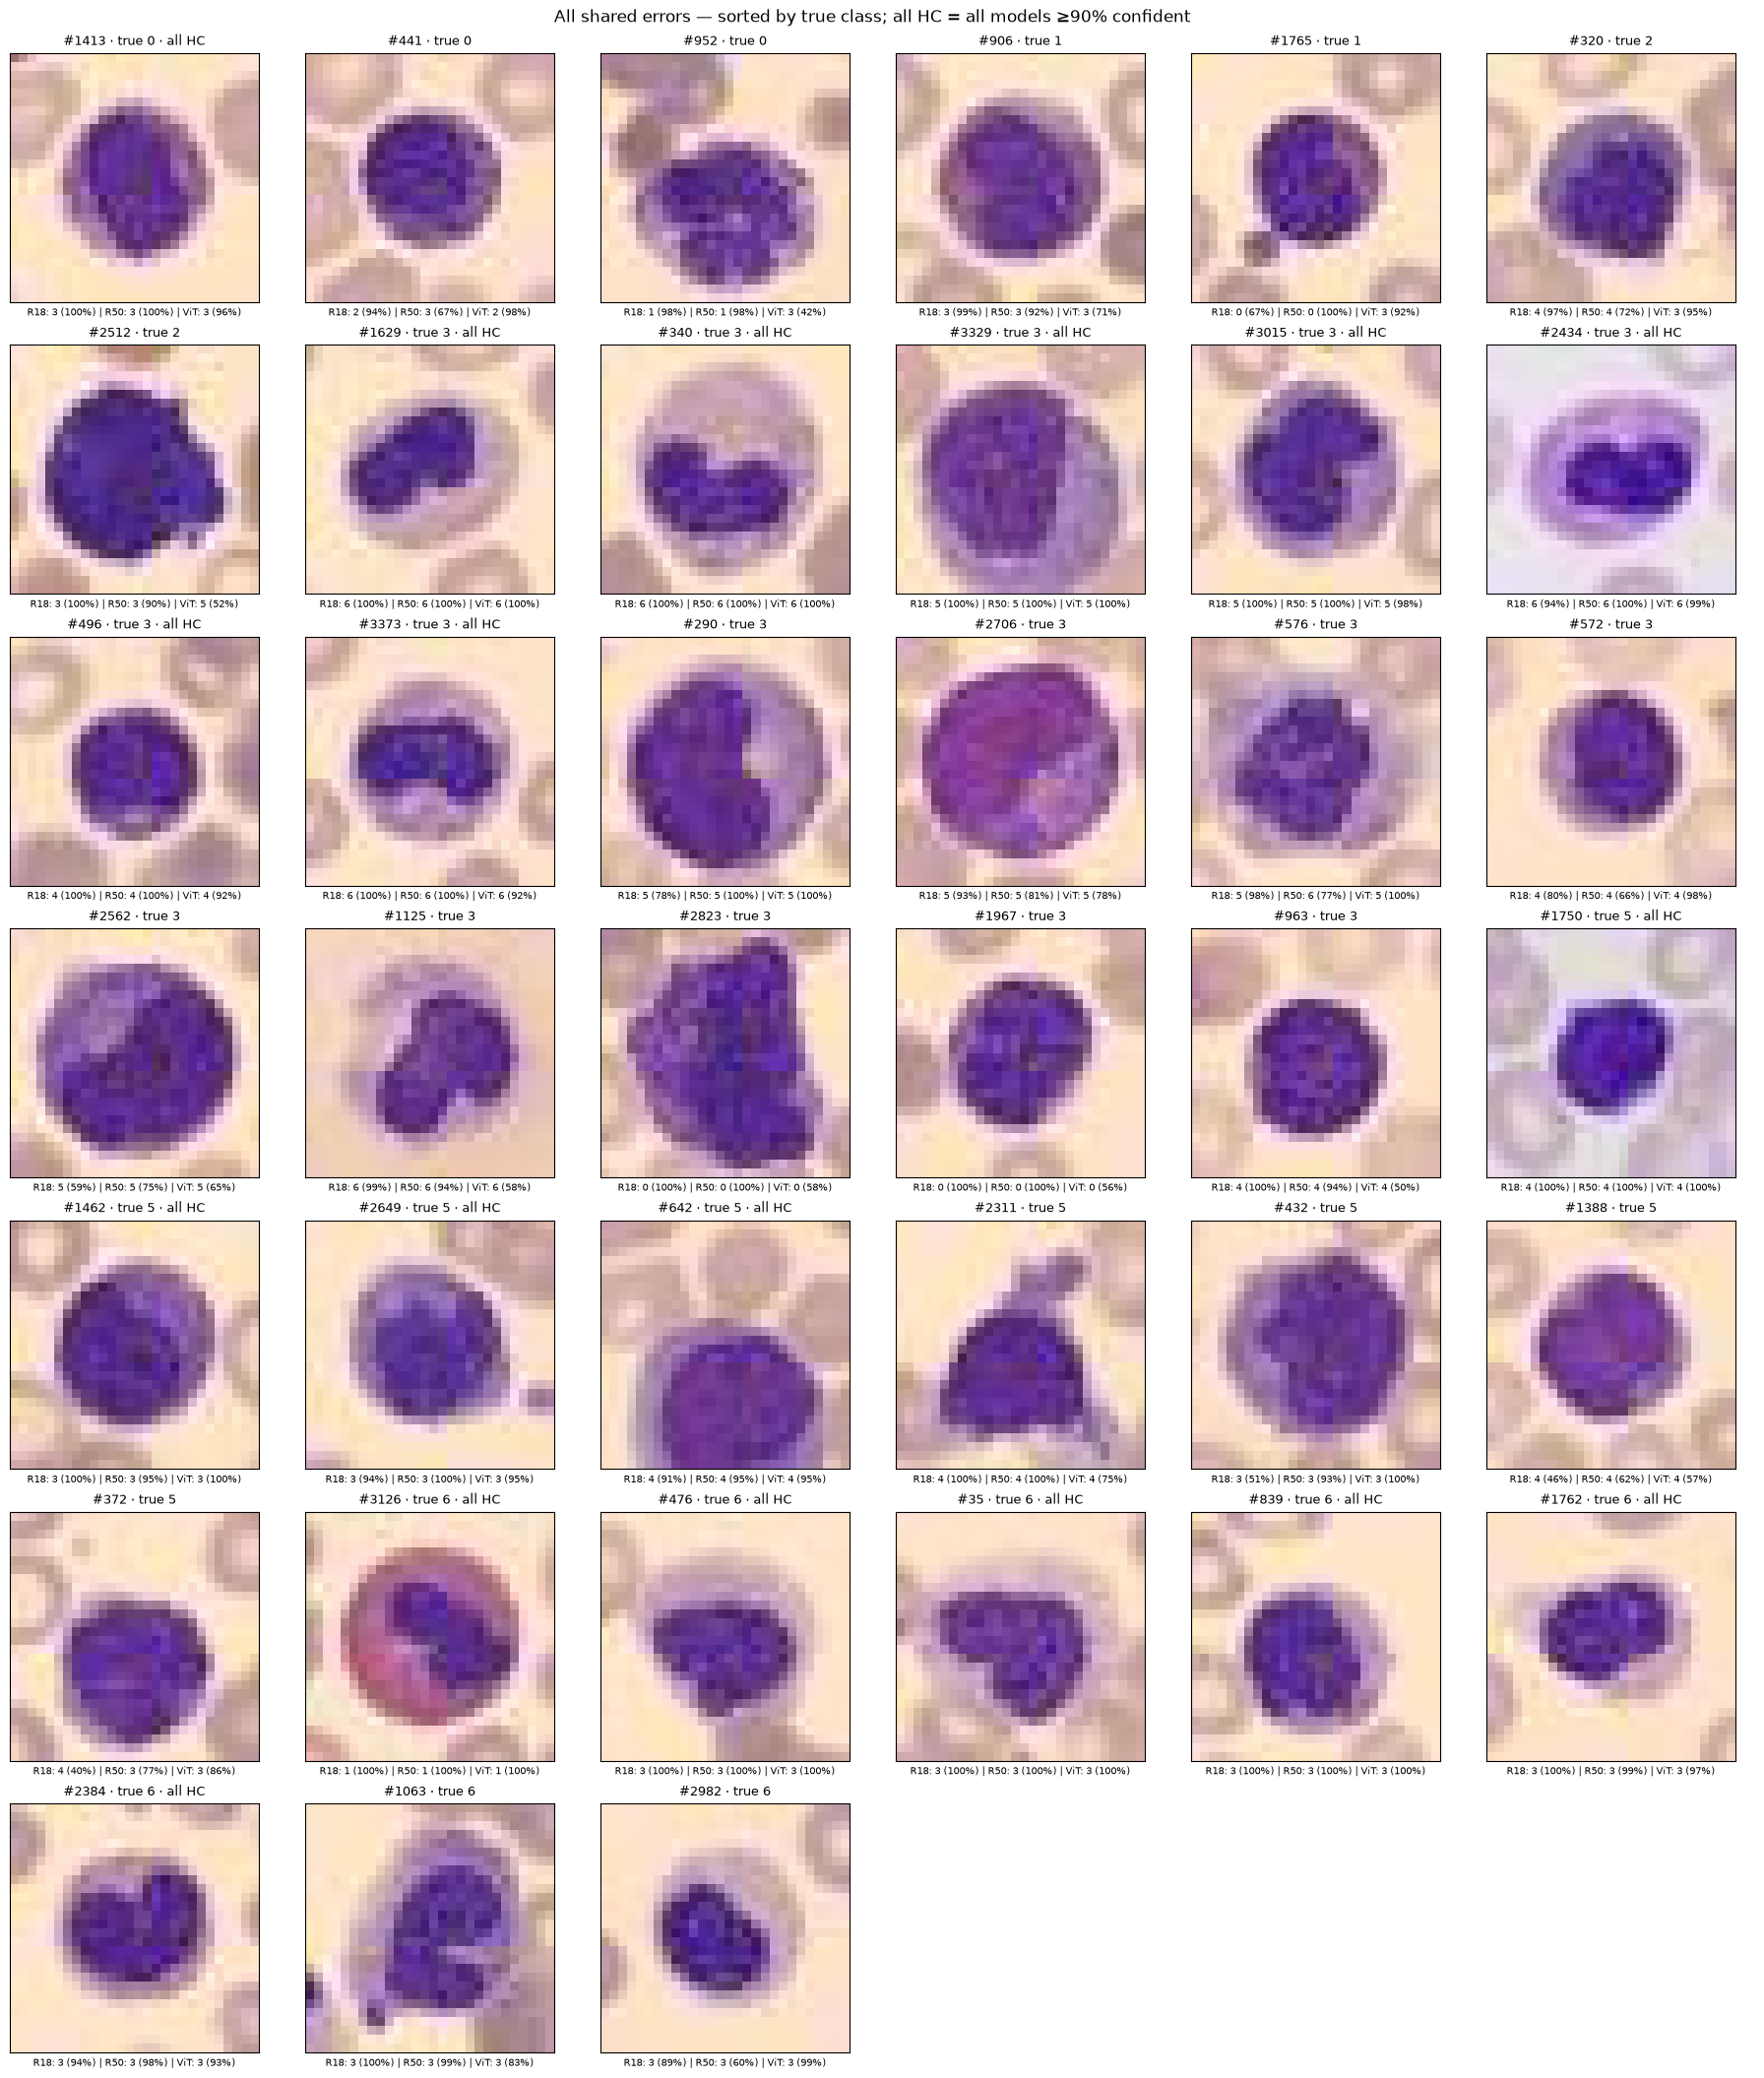

In [39]:
wrong = ~correct
high_wrong = wrong & (confidence >= threshold)
common_wrong = np.flatnonzero(wrong.all(0))
common_hc = np.flatnonzero(high_wrong.all(0))
exclusive_hc = [np.flatnonzero(high_wrong[m] & (wrong.sum(0) == 1)) for m in range(len(model_names))]
print('Shared errors:', len(common_wrong), 'with ≥90% confidence in all models:', len(common_hc))
print('Classes:', dict(enumerate(class_names)))

def gallery(ids, title, columns=6):
    rows = max(1, int(np.ceil(len(ids) / columns)))
    fig, axes = plt.subplots(rows, columns, figsize=(18, 3 * rows), squeeze=False, layout='constrained')
    for ax in axes.flat:
        ax.axis('off')
    for ax, i in zip(axes.flat, ids):
        ax.axis('on')
        ax.imshow(images[i])
        ax.set_title(f'#{i} · true {labels[i]}' + (' · all HC' if high_wrong[:, i].all() else ''), fontsize=9)
        ax.set_xlabel(' | '.join(f'{name}: {predicted[m, i]} ({confidence[m, i]:.0%})'
                                for m, name in enumerate(['R18', 'R50', 'ViT'])), fontsize=7, wrap=True)
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle(title)
    plt.show()

order = np.lexsort((-confidence[:, common_wrong].min(0), labels[common_wrong]))
gallery(common_wrong[order], 'All shared errors — sorted by true class; all HC = all models ≥90% confident')

Look for repeated wrong labels in the shared-error gallery, especially the images marked as highly confident in all models. All models misclassify 39 images, and the 18 shared HC errors receive the same wrong class from all three models, with nine substitutions between immature granulocytes and neutrophils. Agreement therefore leaves recurring class-specific blind spots rather than independently confirming the recorded label.

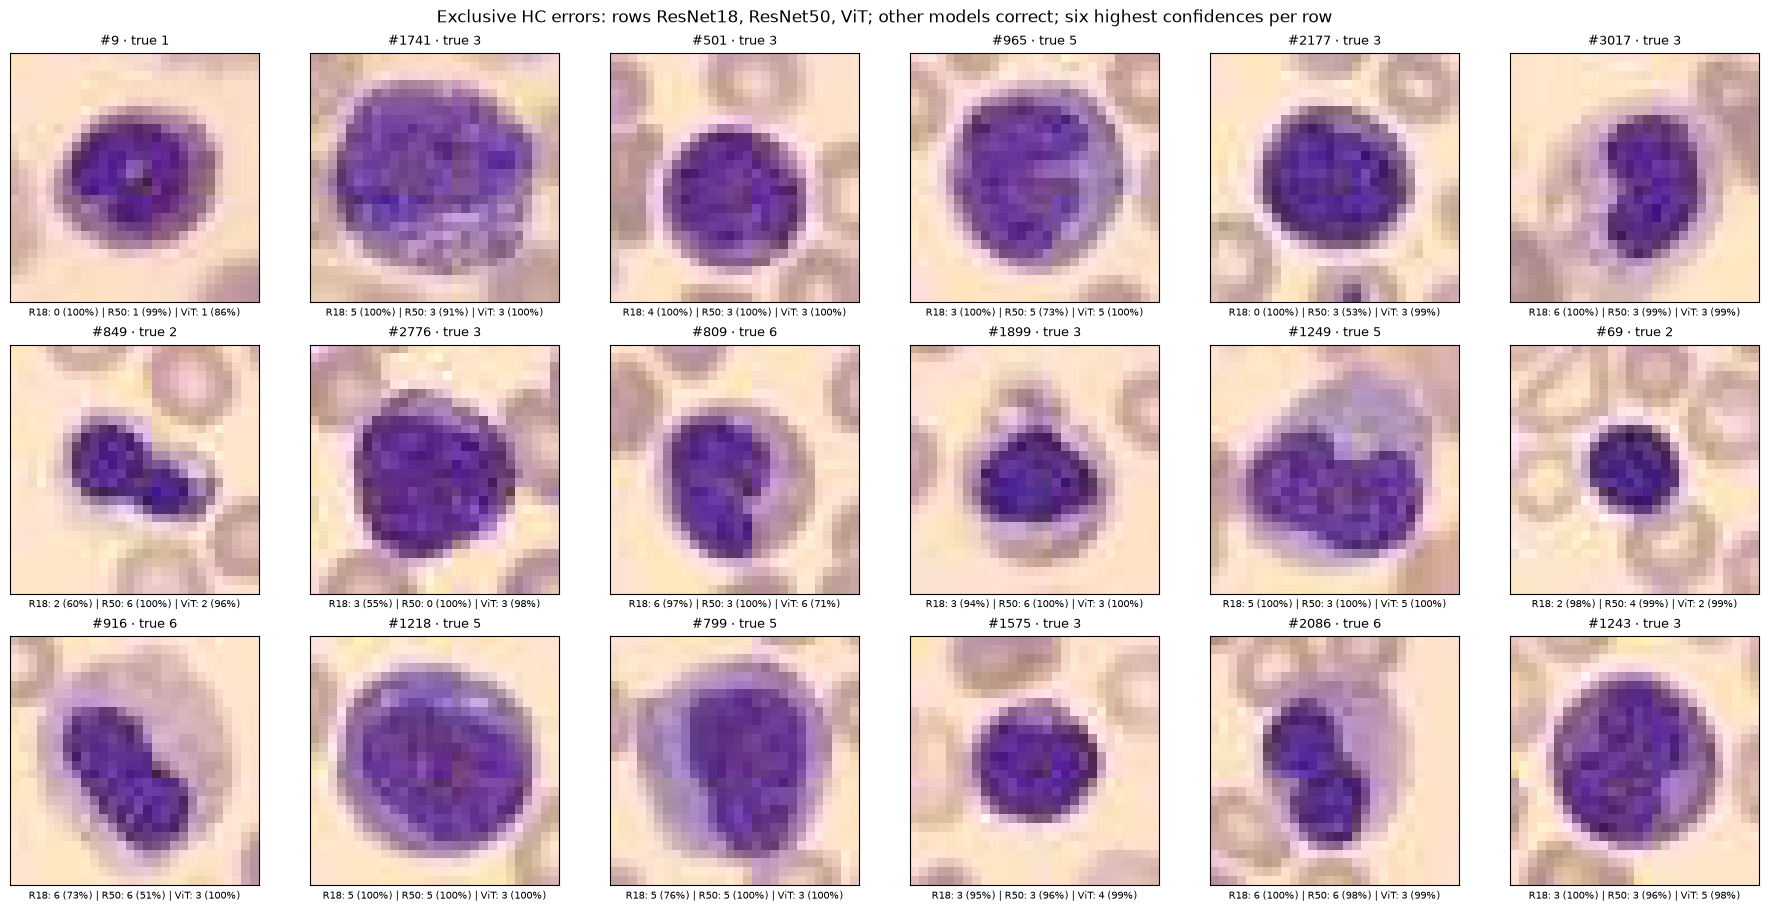

In [40]:
exclusive_examples = np.concatenate([ids[np.argsort(-confidence[m, ids], kind='stable')[:6]]
                                     for m, ids in enumerate(exclusive_hc)])
gallery(exclusive_examples, 'Exclusive HC errors: rows ResNet18, ResNet50, ViT; other models correct; six highest confidences per row')

Compare each row’s selected model with the other two models on the same images. The displayed high-confidence examples are wrong only for ResNet18, only for ResNet50 or only for ViT, while the other models classify them correctly. These exclusive failures show complementary behavior, but confidence-selected examples cannot establish that voting would resolve the shared errors.

## A · Matched images — errors beside similar same-class controls classified correctly with ≥90% confidence by every model

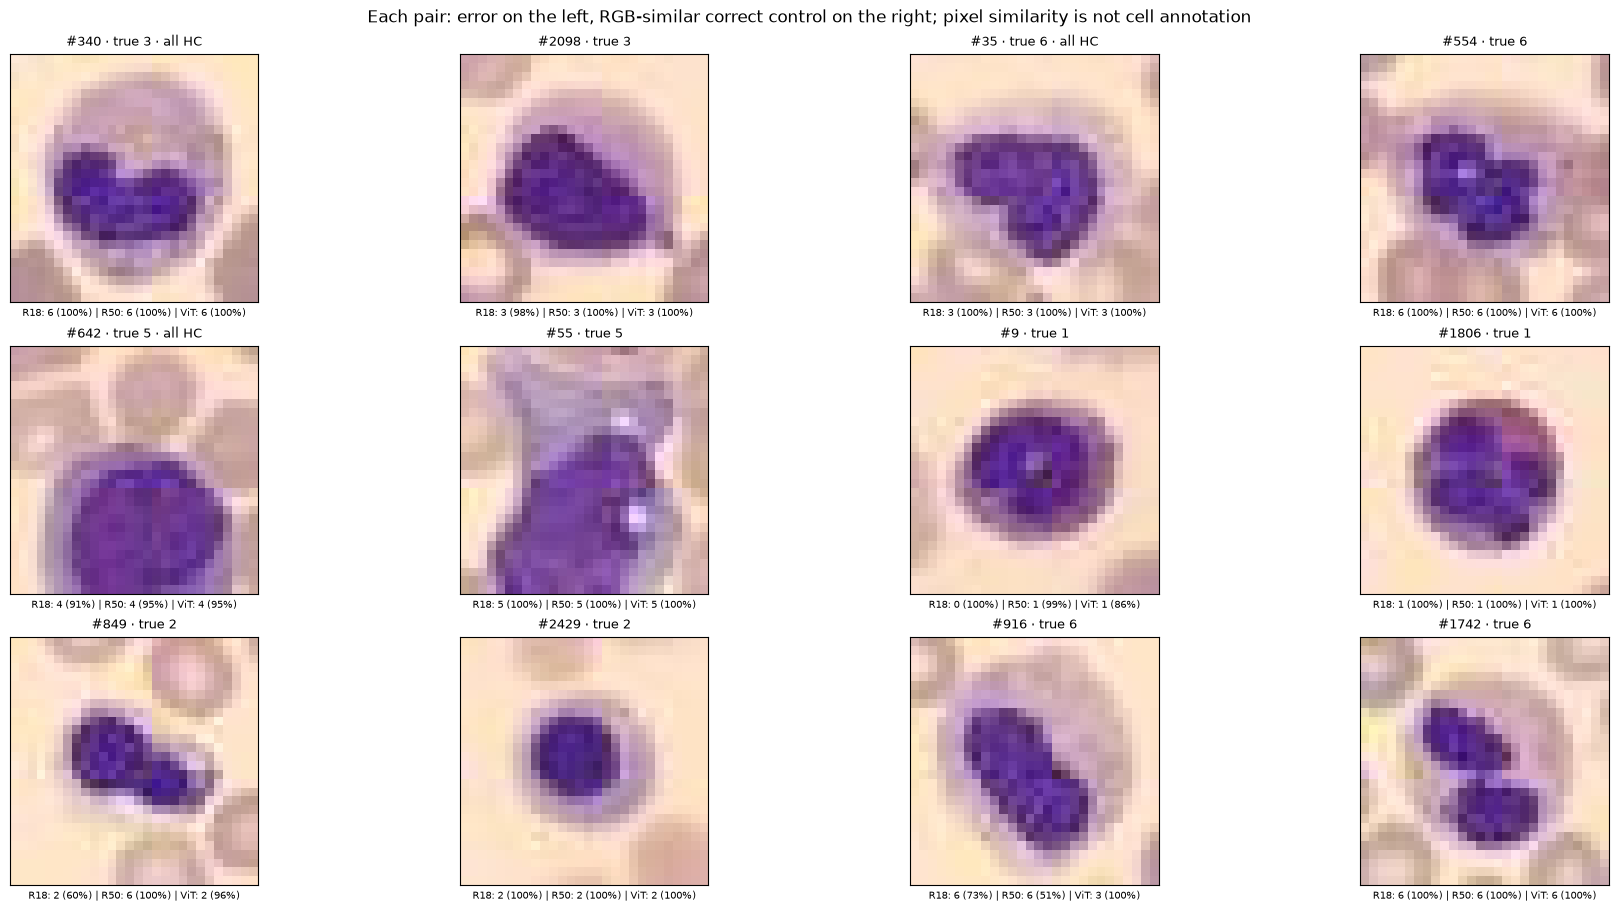

In [41]:
clean = correct.all(0) & (confidence >= threshold).all(0)
largest_classes = np.argsort(-np.bincount(labels[common_hc], minlength=8))[:3]
selected_errors = [common_hc[labels[common_hc] == c][0] for c in largest_classes if (labels[common_hc] == c).any()]
selected_errors += [ids[np.argmax(confidence[m, ids])] for m, ids in enumerate(exclusive_hc) if len(ids)]
gallery_pairs = []
for i in selected_errors:
    allowed = clean & (labels == labels[i])
    assert allowed.any()
    distance = squared + squared[i] - 2 * flat @ flat[i]
    control = np.where(allowed, distance, np.inf).argmin()
    gallery_pairs.append([i, control])
gallery_pairs = np.array(gallery_pairs)
gallery(gallery_pairs.ravel(), 'Each pair: error on the left, RGB-similar correct control on the right; pixel similarity is not cell annotation', columns=4)

Compare each error image with its RGB-near same-class control, using the class and confidence labels to track their different decisions. Pairs #340/#2098 and #35/#554 have similar broad color and layout despite opposite correctness outcomes. Overall appearance alone therefore does not explain every error, while alignment-sensitive RGB matching cannot replace expert assessment of cell structures.

## B · Hypotheses: class concentration and image features — error rate per true class; features versus class-matched controls correct and confident in every model

In [42]:
class_sizes = np.bincount(labels, minlength=8)
class_hc_counts = np.stack([np.bincount(labels[ids], minlength=8) for ids in error_ids])
class_hc_rates = class_hc_counts / class_sizes
cohorts = [common_hc, *exclusive_hc]
cohort_names = ['All three HC wrong', *[f'Only {name} HC wrong' for name in model_names]]
cohort_effects, cohort_weights = [], []
for ids in cohorts:
    weights = np.zeros(len(labels))
    for c in np.unique(labels[ids]):
        mask = clean & (labels == c)
        assert mask.any()
        weights[mask] = (labels[ids] == c).mean() / mask.sum()
    mean = np.average(features, axis=0, weights=weights)
    std = np.sqrt(np.average((features - mean) ** 2, axis=0, weights=weights))
    cohort_effects.append((features[ids].mean(0) - mean) / np.maximum(std, 1e-12))
    cohort_weights.append(weights)
cohort_effects = np.stack(cohort_effects)

def plot_class_rates():
    fig, ax = plt.subplots(figsize=(13, 4), layout='constrained')
    im = ax.imshow(class_hc_rates, cmap='Oranges', vmin=0, aspect='auto')
    ax.set(xticks=range(8), xticklabels=class_names, yticks=range(3), yticklabels=model_names)
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
    for m in range(3):
        for c in range(8):
            ax.text(c, m, f'{class_hc_rates[m, c]:.1%} ({class_hc_counts[m, c]}/{class_sizes[c]})', ha='center', fontsize=8)
    fig.colorbar(im, ax=ax, label='Fraction of ≥90%-confident errors within each true class')
    plt.show()

def plot_shared_features():
    fig, ax = plt.subplots(figsize=(12, 5), layout='constrained')
    limit = max(np.abs(cohort_effects).max(), 0.01)
    im = ax.imshow(cohort_effects, cmap='RdBu_r', vmin=-limit, vmax=limit, aspect='auto')
    ax.set(xticks=range(7), xticklabels=feature_names, yticks=range(4),
           yticklabels=[f'{name} (N={len(ids)})' for name, ids in zip(cohort_names, cohorts)])
    plt.setp(ax.get_xticklabels(), rotation=25, ha='right')
    for row in range(4):
        for col in range(7):
            ax.text(col, row, f'{cohort_effects[row, col]:+.2f}', ha='center')
    fig.colorbar(im, ax=ax, label='Error minus correct control, in control standard deviations')
    plt.show()

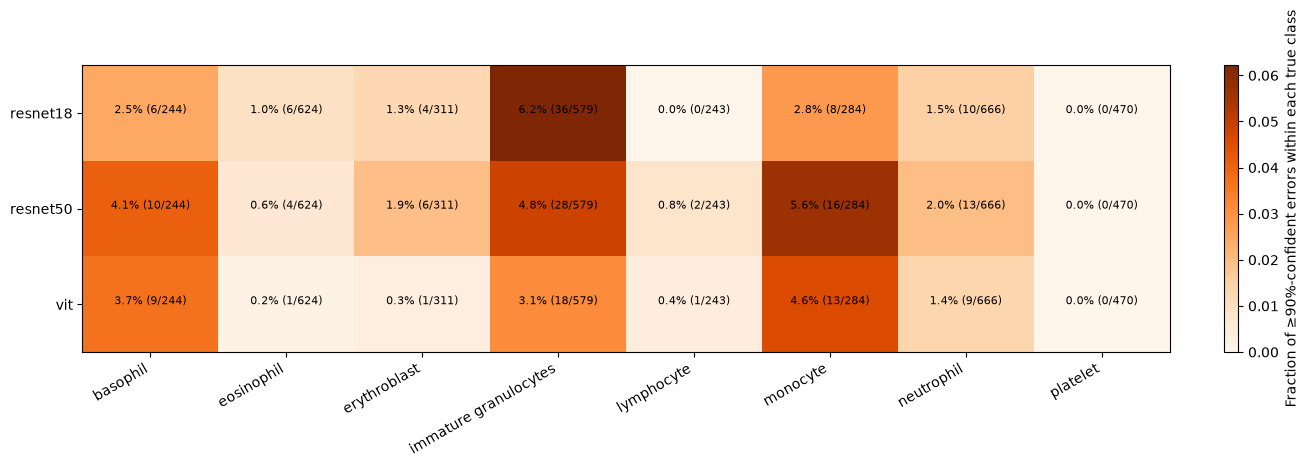

In [43]:
plot_class_rates()

Compare HC-error rates within each true class rather than raw error counts. ResNet18 reaches 6.22% for immature granulocytes versus 2.05% overall, while monocytes have the highest rates for ResNet50 and ViT at 5.63% and 4.58%. Class frequency alone therefore does not explain the error concentration, and the differing rankings indicate checkpoint-specific weaknesses.

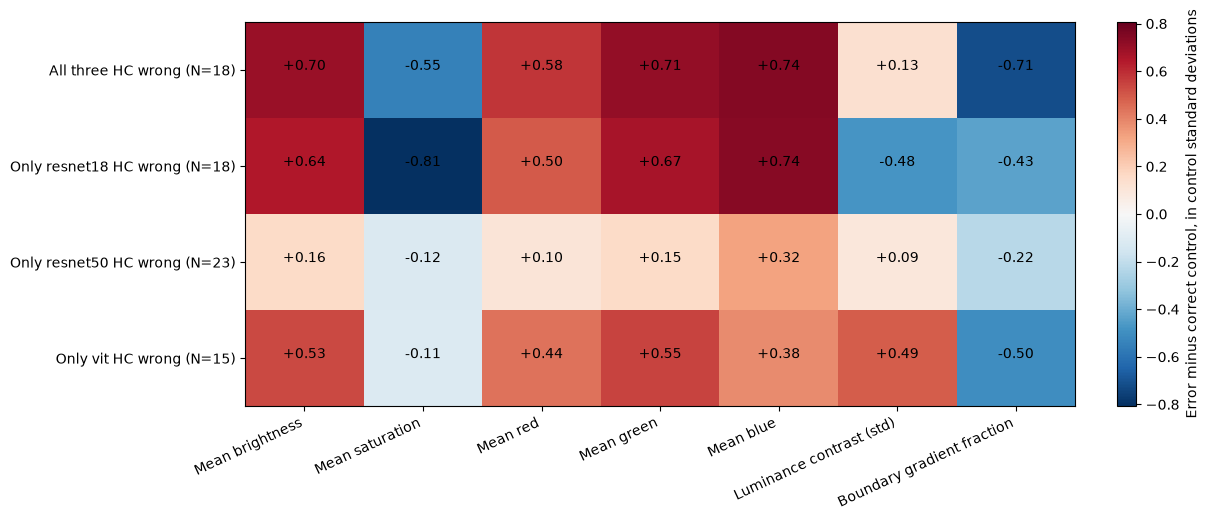

In [44]:
plot_shared_features()

Compare standardized feature shifts across shared and exclusive HC-error groups using class-matched confident correct controls. Shared errors are brighter by 0.70 control SD, have higher blue values by 0.74 SD and lower saturation by 0.55 SD, whereas exclusive groups have different profiles. There is no single appearance signature for all failures, so interventions should distinguish correlated brightness and color effects rather than attribute errors to one feature.

## PCA of all test images — aligned true/predicted-class views of the derived high-confidence-error cohort

In [45]:
pca_path = Path('predictions/test_pca.npz')
if not pca_path.exists():
    from pathlib import Path
    import hashlib
    import numpy as np
    from sklearn.decomposition import PCA
    from sklearn.model_selection import train_test_split
    from sklearn.neighbors import KNeighborsClassifier
    from sklearn.metrics import balanced_accuracy_score
    from threadpoolctl import threadpool_limits

    ROOT = Path('.')
    with np.load(ROOT/'data/bloodmnist.npz', allow_pickle=False) as z:
        images, labels = z['test_images'], z['test_labels'].ravel()
    with np.load(ROOT/'predictions/high_confidence_error_analysis.npz', allow_pickle=False) as z:
        probabilities, model_names, class_names = z['baseline_probabilities'], z['model_names'], z['class_names']
    anchor_pairs = gallery_pairs[:2]
    x = images.reshape(len(images), -1).astype(np.float32) / 255
    indices = np.arange(len(x))
    train, holdout = train_test_split(indices, test_size=0.25, random_state=42, stratify=labels)
    with threadpool_limits(limits=4):
        pca = PCA(n_components=2, svd_solver='randomized', random_state=42)
        xy = pca.fit_transform(x)
        validation_pca = PCA(n_components=2, svd_solver='randomized', random_state=42)
        validation_train = validation_pca.fit_transform(x[train])
        validation_holdout = validation_pca.transform(x[holdout])
        lower, upper = xy.min(0), xy.max(0)
        padding = (upper - lower) * 0.05
        gx, gy = np.meshgrid(np.linspace(lower[0]-padding[0],upper[0]+padding[0],160),
                             np.linspace(lower[1]-padding[1],upper[1]+padding[1],160))
        grid = np.column_stack((gx.ravel(),gy.ravel()))
        predicted = probabilities.argmax(-1)
        grid_labels, agreement, balanced_agreement, majority_agreement = [], [], [], []
        for m in range(len(model_names)):
            surrogate = KNeighborsClassifier(n_neighbors=25, weights='distance')
            surrogate.fit(validation_train, predicted[m, train])
            guesses = surrogate.predict(validation_holdout)
            agreement.append((guesses == predicted[m, holdout]).mean())
            balanced_agreement.append(balanced_accuracy_score(predicted[m, holdout], guesses))
            majority = np.bincount(predicted[m, train],minlength=8).argmax()
            majority_agreement.append((predicted[m, holdout] == majority).mean())
            surrogate.fit(xy, predicted[m])
            grid_labels.append(surrogate.predict(grid).reshape(gx.shape))
        # Suppress unsupported low-density regions rather than extrapolating across the full rectangle.
        density_threshold = np.quantile(surrogate.kneighbors(xy, n_neighbors=6)[0][:,5],0.95)
        support = surrogate.kneighbors(grid,n_neighbors=5)[0][:,4] <= density_threshold
        residual = x[anchor_pairs.ravel()] - pca.inverse_transform(xy[anchor_pairs.ravel()])
        np.testing.assert_allclose(pca.inverse_transform(xy[anchor_pairs.ravel()])+residual,
                                   x[anchor_pairs.ravel()], atol=1e-7)
    np.savez_compressed(ROOT/'predictions/test_pca.npz', coordinates=xy, components=pca.components_, mean=pca.mean_,
                        explained_variance=pca.explained_variance_, explained_variance_ratio=pca.explained_variance_ratio_,
                        sample_index=indices, labels=labels, model_names=model_names, class_names=class_names,
                        predicted_labels=predicted, probabilities=probabilities,
                        high_confidence_wrong=(predicted!=labels)&(probabilities.max(-1)>=0.9),
                        grid_x=gx, grid_y=gy, surrogate_regions=np.stack(grid_labels), support=support.reshape(gx.shape),
                        surrogate_agreement=agreement, surrogate_balanced_agreement=balanced_agreement,
                        majority_agreement=majority_agreement, train_indices=train, holdout_indices=holdout,
                        anchor_pairs=anchor_pairs, anchor_residual=residual, seed=42, n_neighbors=25,
                        input_sha256=hashlib.sha256(images.tobytes()).hexdigest(), split='test',
                        method='centered raw RGB [0,1]; no per-pixel standardization; randomized PCA',
                        validation='PCA and kNN refitted on training partition; held-out black-box-label agreement, not ground-truth accuracy')
    print('Explained variance:',pca.explained_variance_ratio_.tolist())
    for m,name in enumerate(model_names):
        print(name,'held-out surrogate agreement',round(float(agreement[m]),4),
              'balanced',round(float(balanced_agreement[m]),4),'majority',round(float(majority_agreement[m]),4))
    print('Anchor error/control pairs:',anchor_pairs.tolist())

with np.load(pca_path, allow_pickle=False) as saved:
    pca = {key:saved[key] for key in saved.files}
np.testing.assert_allclose(pca['probabilities'], probabilities, atol=1e-9)
np.testing.assert_array_equal(pca['labels'], labels)
for m, name in enumerate(model_names):
    print(name, 'held-out agreement / balanced agreement / majority baseline:',
          ' / '.join(f'{float(pca[key][m]):.2%}' for key in ['surrogate_agreement', 'surrogate_balanced_agreement', 'majority_agreement']))


resnet18 held-out agreement / balanced agreement / majority baseline: 58.29% / 53.85% / 19.63%
resnet50 held-out agreement / balanced agreement / majority baseline: 58.06% / 54.28% / 19.51%
vit held-out agreement / balanced agreement / majority baseline: 57.01% / 53.05% / 18.81%


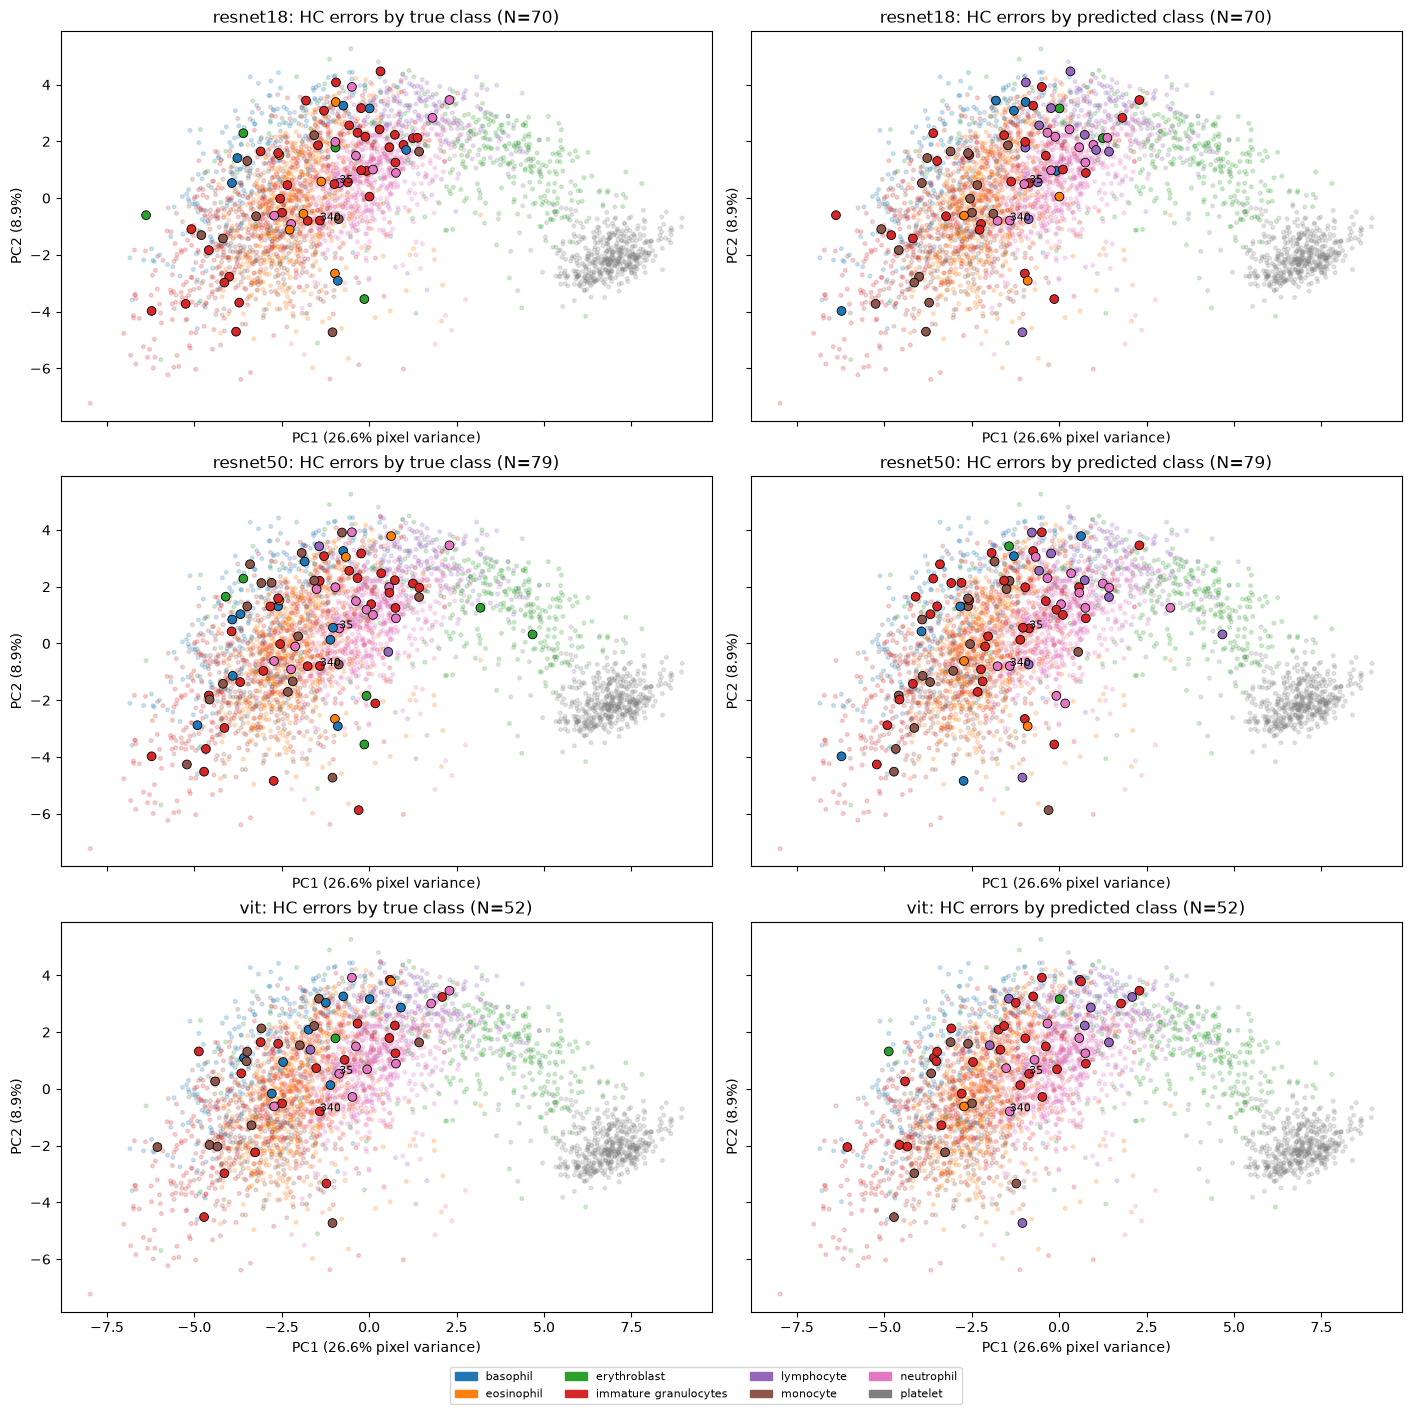

In [46]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
class_colors = plt.get_cmap('tab10')(np.arange(8))
class_cmap = ListedColormap(class_colors)
class_norm = BoundaryNorm(np.arange(9) - 0.5, 8)
xy = pca['coordinates']
fig, axes = plt.subplots(3, 2, figsize=(14, 14), sharex=True, sharey=True, layout='constrained')
for m, name in enumerate(model_names):
    ids = np.flatnonzero(pca['high_confidence_wrong'][m])
    for col, (title, colors) in enumerate([('True class', labels), ('Predicted class', predicted[m])]):
        ax = axes[m, col]
        ax.scatter(*xy.T, c=class_colors[colors], s=7, alpha=0.20)
        ax.scatter(*xy[ids].T, c=class_colors[colors[ids]], s=40, edgecolor='black', linewidth=0.6)
        for i in [340, 35]:
            if i in ids:ax.annotate(str(i), xy[i], fontsize=8)
        ax.set(title=f'{name}: HC errors by {title.lower()} (N={len(ids)})',
               xlabel=f'PC1 ({pca["explained_variance_ratio"][0]:.1%} pixel variance)',
               ylabel=f'PC2 ({pca["explained_variance_ratio"][1]:.1%})')
fig.legend(handles=[Patch(color=class_colors[c], label=class_names[c]) for c in range(8)],
           loc='outside lower center', ncol=4, fontsize=8)
plt.show()

Compare highlighted errors by true class on the left and predicted class on the right, keeping their shared PCA coordinates fixed. The first two PCs retain 35.6% of pixel variance, and PC1 correlates strongly with brightness at +0.91 and saturation at −0.90. This projection mainly summarizes appearance, so overlapping positions or changed class colors do not by themselves explain a model’s decision.

## Empirical decision-region approximation — validate the surrogate against black-box labels, not true labels

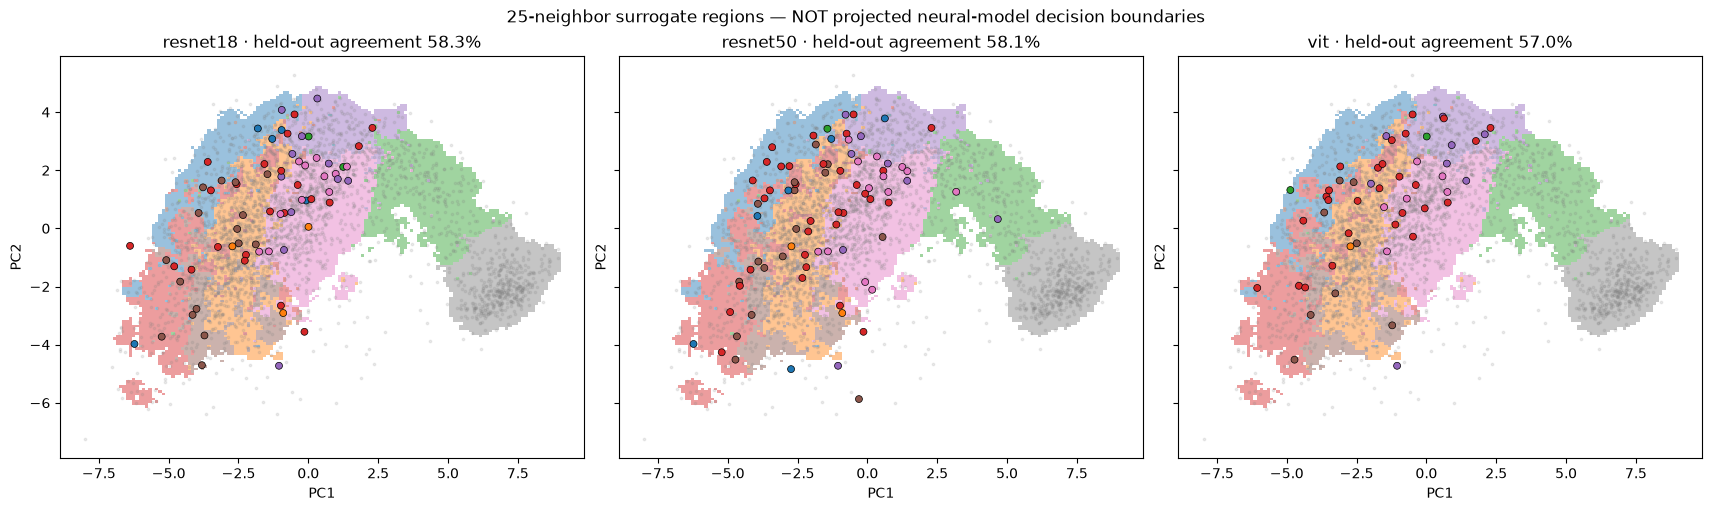

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True, sharey=True, layout='constrained')
for m, ax in enumerate(axes):
    region = np.ma.masked_where(~pca['support'], pca['surrogate_regions'][m])
    ax.pcolormesh(pca['grid_x'], pca['grid_y'], region, cmap=class_cmap, norm=class_norm, shading='auto', alpha=0.45)
    ids = np.flatnonzero(pca['high_confidence_wrong'][m])
    ax.scatter(*xy.T, color='gray', s=3, alpha=0.15)
    ax.scatter(*xy[ids].T, c=class_colors[predicted[m, ids]], s=25, edgecolor='black', linewidth=0.5)
    ax.set(title=f'{model_names[m]} · held-out agreement {pca["surrogate_agreement"][m]:.1%}', xlabel='PC1', ylabel='PC2')
fig.suptitle('25-neighbor surrogate regions — NOT projected neural-model decision boundaries')
plt.show()

Read colored regions as supported 25-neighbor surrogate assignments and use held-out agreement, with PCA and the surrogate refitted on the fit partition, to judge their fidelity. Agreement is only 58.3%, 58.1% and 57.0% for ResNet18, ResNet50 and ViT, despite exceeding the 19–20% majority-label baseline. These regions are therefore low-fidelity empirical approximations, not true projected neural-model decision boundaries.

## Local black-box slices — vary two PCs around real error/control images while keeping the remaining image information fixed

In [48]:
local_path = Path('predictions/pca_blackbox_slices.npz')
if not local_path.exists():
    anchors=pca['anchor_pairs'].ravel()
    axis=np.linspace(-0.5,0.5,41)
    gx,gy=np.meshgrid(axis,axis)
    delta=np.column_stack((gx.ravel(),gy.ravel())) * np.sqrt(pca['explained_variance'])
    output=np.empty((3,len(anchors),41,41,8),dtype=np.float32)
    scores=np.empty_like(output)
    clipped=np.empty((len(anchors),41,41),dtype=np.float32)
    realized=np.empty((len(anchors),41,41,2),dtype=np.float32)
    nearest_switch=np.full((3,len(anchors)),np.nan)
    distance=np.hypot(gx,gy)
    for j,i in enumerate(anchors):
        # Keep the anchor's residual outside the first two PCs, instead of inverse-PCA mean images.
        x=images[i].reshape(-1).astype(np.float32)/255
        raw=x[None]+delta@pca['components']
        clipped[j]=((raw<0)|(raw>1)).mean(-1).reshape(41,41)
        changed=np.rint(np.clip(raw,0,1)*255).astype(np.uint8).reshape(-1,28,28,3)
        np.testing.assert_array_equal(changed[20*41+20],images[i])
        realized[j]=((changed.reshape(len(changed),-1).astype(np.float32)/255-pca['mean'])@pca['components'].T).reshape(41,41,2)
        for m,name in enumerate(model_names):
            p,logits=predict(m,changed)
            output[m,j]=p.reshape(41,41,8)
            scores[m,j]=logits.reshape(41,41,8)
            np.testing.assert_allclose(output[m,j,20,20],probabilities[m,i],atol=1e-5,rtol=1e-4)
            switched=(output[m,j].argmax(-1)!=probabilities[m,i].argmax())&(clipped[j]<=0.05)
            if switched.any():nearest_switch[m,j]=distance[switched].min()
        print(f'Anchor #{i}: all three local black-box maps complete',flush=True)
    with np.load('predictions/occlusion_test.npz',allow_pickle=False) as z:
        checkpoint_hashes=z['weight_hashes']
    np.savez_compressed('predictions/pca_blackbox_slices.npz', probabilities=output,logits=scores,
                        sample_index=anchors,anchor_pairs=pca['anchor_pairs'],labels=labels[anchors],
                        baseline_probabilities=probabilities[:,anchors],model_names=model_names,checkpoints=checkpoints,
                        weight_hashes=checkpoint_hashes,grid_x=gx,grid_y=gy,clip_fraction=clipped,
                        realized_pca_coordinates=realized,components=pca['components'],mean=pca['mean'],
                        explained_variance=pca['explained_variance'],coordinates=pca['coordinates'][anchors],
                        nearest_observed_switch=nearest_switch,seed=42,split='test',max_display_clip_fraction=0.05,
                        method='anchor plus first-two-PC displacement; original residual fixed; clip to [0,1], round to uint8',
                        axes=['model','anchor','PC2 grid row','PC1 grid column','class'])
    assert np.isfinite(output).all() and np.isfinite(scores).all()
    np.testing.assert_allclose(output.sum(-1),1,atol=1e-6)
    for m in range(3):
        exp=np.exp(scores[m].astype(float)-scores[m].max(-1,keepdims=True))
        np.testing.assert_allclose(exp/exp.sum(-1,keepdims=True),output[m],atol=2e-7,rtol=1e-5)
    print('Nearest observed label switch (PC-standard-deviation units; NaN = none on displayed grid):',nearest_switch.tolist())
    print('Fraction of each grid with <=5% clipped pixels:',(clipped<=.05).mean((1,2)).tolist())

with np.load(local_path, allow_pickle=False) as saved:
    local = {key:saved[key] for key in saved.files}
np.testing.assert_allclose(local['baseline_probabilities'], probabilities[:, local['sample_index']], atol=1e-5, rtol=1e-4)

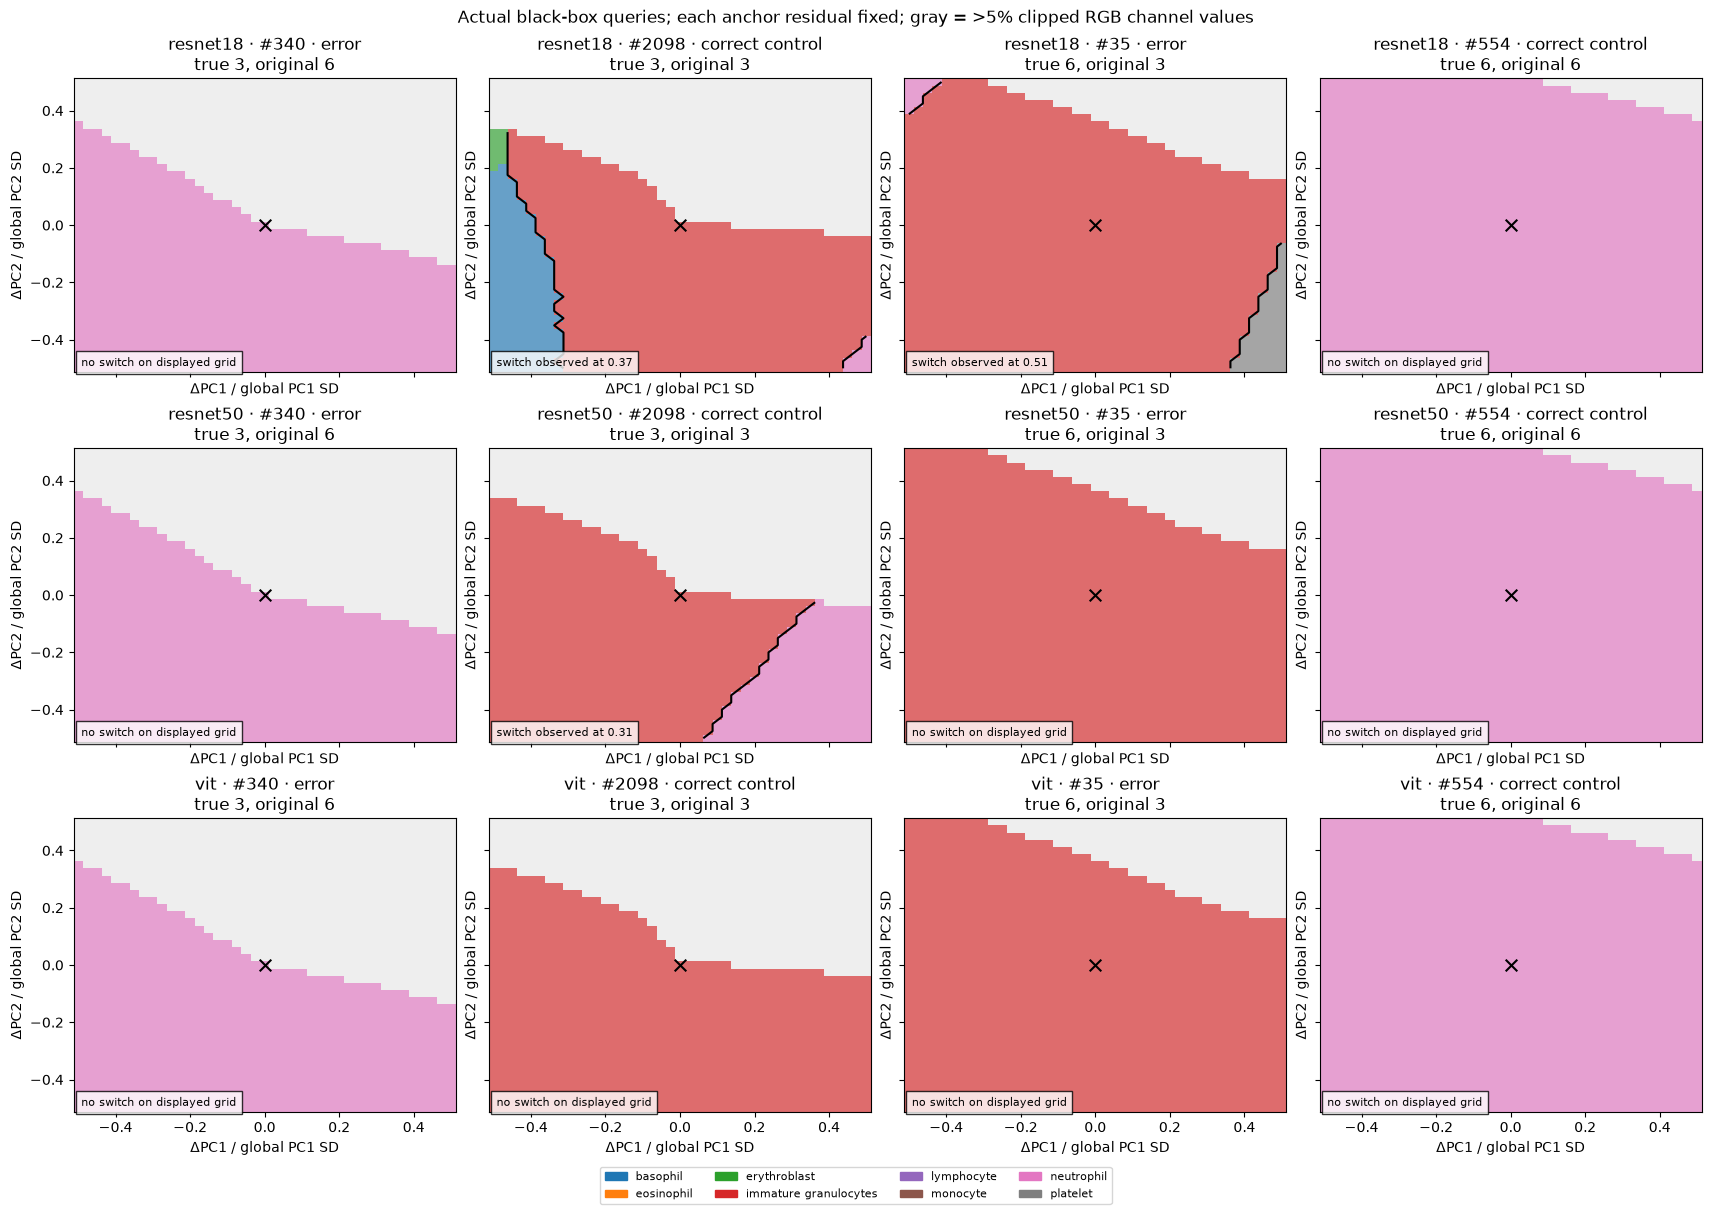

In [49]:
fig, axes = plt.subplots(3, 4, figsize=(17, 12), sharex=True, sharey=True, layout='constrained')
for m, name in enumerate(model_names):
    for j, i in enumerate(local['sample_index']):
        ax = axes[m, j]
        assigned = local['probabilities'][m, j].argmax(-1)
        invalid = local['clip_fraction'][j] > 0.05
        region = np.ma.masked_where(invalid, assigned)
        ax.set_facecolor('#eeeeee')
        ax.pcolormesh(local['grid_x'], local['grid_y'], region, cmap=class_cmap, norm=class_norm, shading='auto', alpha=0.65)
        original = local['baseline_probabilities'][m, j].argmax()
        same = np.ma.masked_where(invalid, assigned == original)
        if same.min() != same.max():ax.contour(local['grid_x'], local['grid_y'], same, levels=[0.5], colors='black')
        ax.scatter(0, 0, marker='x', color='black', s=70)
        nearest = local['nearest_observed_switch'][m, j]
        text = f'switch observed at {nearest:.2f}' if np.isfinite(nearest) else 'no switch on displayed grid'
        ax.set(title=f'{name} · #{i} · {"error" if j % 2 == 0 else "correct control"}\ntrue {labels[i]}, original {original}',
               xlabel='ΔPC1 / global PC1 SD', ylabel='ΔPC2 / global PC2 SD')
        ax.text(0.02, 0.02, text, transform=ax.transAxes, fontsize=8, bbox={'facecolor':'white','alpha':0.8})
fig.legend(handles=[Patch(color=class_colors[c], label=class_names[c]) for c in range(8)],
           loc='outside lower center', ncol=4, fontsize=8)
fig.suptitle('Actual black-box queries; each anchor residual fixed; gray = >5% clipped RGB channel values')
plt.show()

Look for class-color changes around each anchor’s center marker, excluding gray queries where more than 5% of RGB channel values would be clipped. Only three of twelve model/anchor maps contain an admitted switch, with no switch around shared error #340 but switches around correct control #2098 for both CNNs. These selected finite slices do not support errors being consistently closer to a leading-PC boundary, and a constant region is not a global robustness certificate.

## C · Linking errors to stability — same brightness and translation levels; all HC errors versus RGB-near correct ≥90%-confident same-class controls; a changed decision is not necessarily a correction

In [50]:
with np.load('predictions/stability.npz', allow_pickle=False) as saved:
    followup_levels = {kind: saved[f'levels_{kind}'] for kind in ['brightness', 'translation']}
followup = dict(model_names=model_names, threshold=threshold, common_wrong=common_wrong, common_hc=common_hc,
                gallery_pairs=gallery_pairs, class_sizes=class_sizes, class_hc_counts=class_hc_counts,
                cohort_names=cohort_names, cohort_effects=cohort_effects, cohort_weights=np.stack(cohort_weights),
                cohort_roles=['HC errors', 'correct HC controls'], checkpoints=checkpoints)
for m, ids in enumerate(error_ids):
    controls = neighbor_ids[m][0]
    assert correct[m, controls].all() and (confidence[m, controls] >= threshold).all()
    np.testing.assert_array_equal(labels[controls], labels[ids])
    selected = np.stack((ids, controls))
    base = probabilities[m, selected]
    scores = np.load(f'predictions/{model_names[m]}_test.npz')['logits'][selected]
    original = base.argmax(-1)
    original_probability = base.max(-1)
    followup[f'{model_names[m]}_ids'] = selected
    followup[f'{model_names[m]}_exclusive_hc'] = exclusive_hc[m]
    followup[f'{model_names[m]}_baseline'] = base
    followup[f'{model_names[m]}_baseline_logits'] = scores.reshape(2, len(ids), 8)
    print(f'{model_names[m]}: {len(ids)} errors, {len(np.unique(controls))} unique controls; mean baseline confidence {original_probability[0].mean():.1%} / {original_probability[1].mean():.1%}')
    for col, (kind, values) in enumerate(followup_levels.items()):
        with np.load('predictions/stability.npz', allow_pickle=False) as saved:
            p = saved[kind][m, :, 0][:, selected].transpose(1, 0, 2, 3)
            logits = saved[f'logits_{kind}'][m, :, 0][:, selected].transpose(1, 0, 2, 3)
        delta = np.take_along_axis(p, original[:, None, :, None], axis=-1)[..., 0] - original_probability[:, None]
        followup[f'{model_names[m]}_{kind}'] = p
        followup[f'{model_names[m]}_{kind}_logits'] = logits
        print(f'{model_names[m]} {kind}: mean probability drop for errors {-delta[0].mean():.3f}, controls {-delta[1].mean():.3f}')
followup.update({f'levels_{kind}': values for kind, values in followup_levels.items()})
np.savez_compressed('predictions/high_confidence_followup.npz', **followup)

def plot_targeted_followup():
    fig, axes = plt.subplots(3, 2, figsize=(13, 10), layout='constrained')
    for m, model in enumerate(model_names):
        ids = followup[f'{model}_ids'][0]
        base = followup[f'{model}_baseline']
        original, original_probability = base.argmax(-1), base.max(-1)
        for col, (kind, values) in enumerate(followup_levels.items()):
            p = followup[f'{model}_{kind}']
            delta = np.take_along_axis(p, original[:, None, :, None], axis=-1)[..., 0] - original_probability[:, None]
            for role, name in enumerate(['HC errors', 'Correct HC controls']):
                y = 100 * delta[role].mean(-1)
                assert change_limits[0] <= y.min() and y.max() <= change_limits[1], 'Change would be clipped.'
                axes[m, col].plot(values, y, 'o-', label=name)
            axes[m, col].axhline(0, color='gray', ls='--')
            axes[m, col].set(title=f'{model_names[m]} · {kind} · N={len(ids)} pairs',
                              xlabel=kind, ylabel='Change (percentage points)', ylim=change_limits)
            axes[m, col].grid(alpha=0.2)
    axes[0, 0].legend()
    fig.suptitle('Targeted follow-up using stability levels: errors versus class-matched correct decisions')
    plt.show()

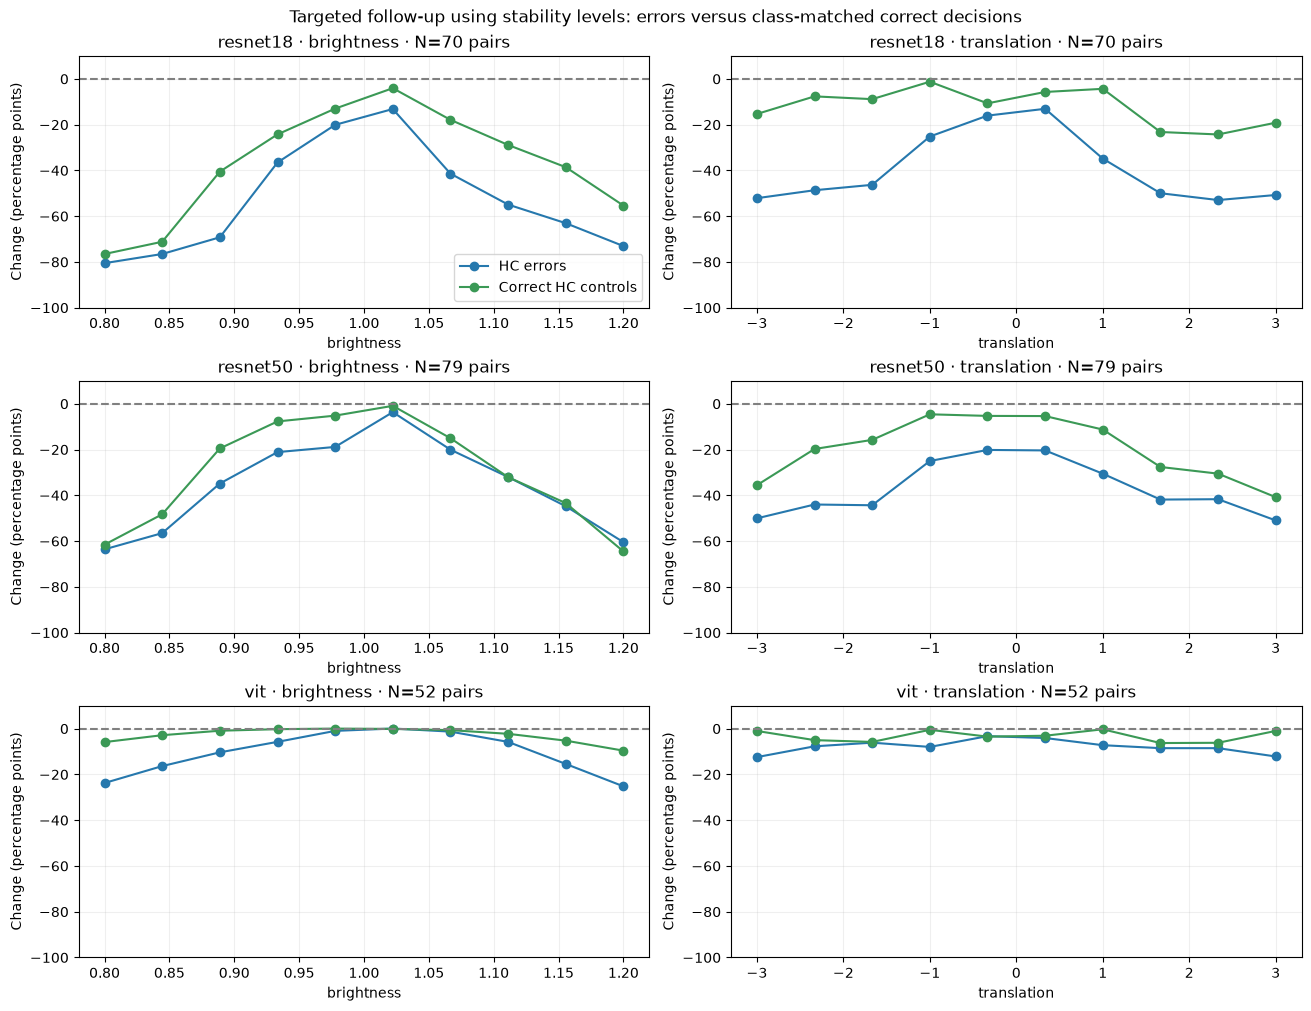

In [51]:
plot_targeted_followup()

Compare original-class probability changes for HC errors and same-class HC-correct controls at identical brightness and translation levels. Errors lose more support under both operations in all three models, including a mean ResNet18 translation drop of 39.0 percentage points versus 12.0 for controls. Transformation response may therefore add information beyond high starting confidence, but differing baseline confidence and potentially wrong replacement labels prevent treating it as an established error detector.

## Findings

- **Shared class substitutions:** Compare the repeated labels in the shared gallery with the exclusive-error examples. All models misclassify 39 images, including 18 shared HC errors with identical wrong labels and nine immature-granulocyte/neutrophil substitutions. These recurring substitutions reveal shared class competition, while exclusive errors show that the checkpoints do not share every weakness.
- **Class and color dependence:** Compare per-class HC-error rates with the destination classes reached under desaturation. Immature granulocytes have ResNet18’s highest rate at 6.22%, monocytes have the highest ResNet50/ViT rates at 5.63%/4.58%, and desaturation sends almost all CNN errors and matched controls to erythroblast. The results indicate class-specific weaknesses and a shared color-dependent class attractor, not a selective repair of the original errors.
- **Appearance versus decision geometry:** Compare error/control appearance shifts with surrogate fidelity and actual local boundary crossings. Shared errors are brighter by 0.70 control SD, but the PCA surrogate reproduces only 57–58% of held-out decisions and error #340 has no switch while correct control #2098 crosses for both CNNs. Appearance associations therefore do not establish that HC errors are consistently closer to a leading-PC boundary.
- **Spatial support for wrong decisions:** Compare population occlusion with same-class HC error-minus-control contrasts rather than interpreting central dependence alone. ResNet50’s central error contrast differs in sign between monocytes and basophils, while paired HC errors show additional central drops of 0.104, 0.098 and 0.113 for ResNet18, ResNet50 and ViT. Wrong decisions can therefore have stronger spatial dependence than comparable correct decisions, without those fixed patches identifying anatomical structures.
- **Direction-specific instability:** Compare the targeted brightness/translation responses with the mostly constant local PCA slices. HC errors lose more original-class support than their correct controls under both operations, including 39.0 versus 12.0 percentage points for ResNet18 translation, while only three local PCA maps contain an admitted label switch. High confidence therefore does not imply uniformly stable or fragile decisions, because the chosen perturbation direction matters.

**Limits:** Treat these test-only results as exploratory rather than independent confirmation of selected hypotheses. Paired intervention controls match true class and confidence threshold but not exact confidence and can be reused; feature-distribution controls are class-weighted, and ResNet18/ViT resize to 224×224 whereas ResNet50 uses 28×28 with different resizing methods. Correlated features, potentially out-of-distribution or label-changing transformations, and selected finite clipped PCA slices limit causal and global robustness claims.


## At-a-glance summary — decision changes versus confident errors

The left map shows how often the answer changes, while the right shows how often the answer is wrong with confidence ≥90%. Each cell averages the ten tested levels equally after averaging noise repeats within each image; darker colors mean higher percentages, using one shared color scale. These are averages over the displayed ranges rather than equal-severity comparisons, and the right-hand values include pre-existing errors.

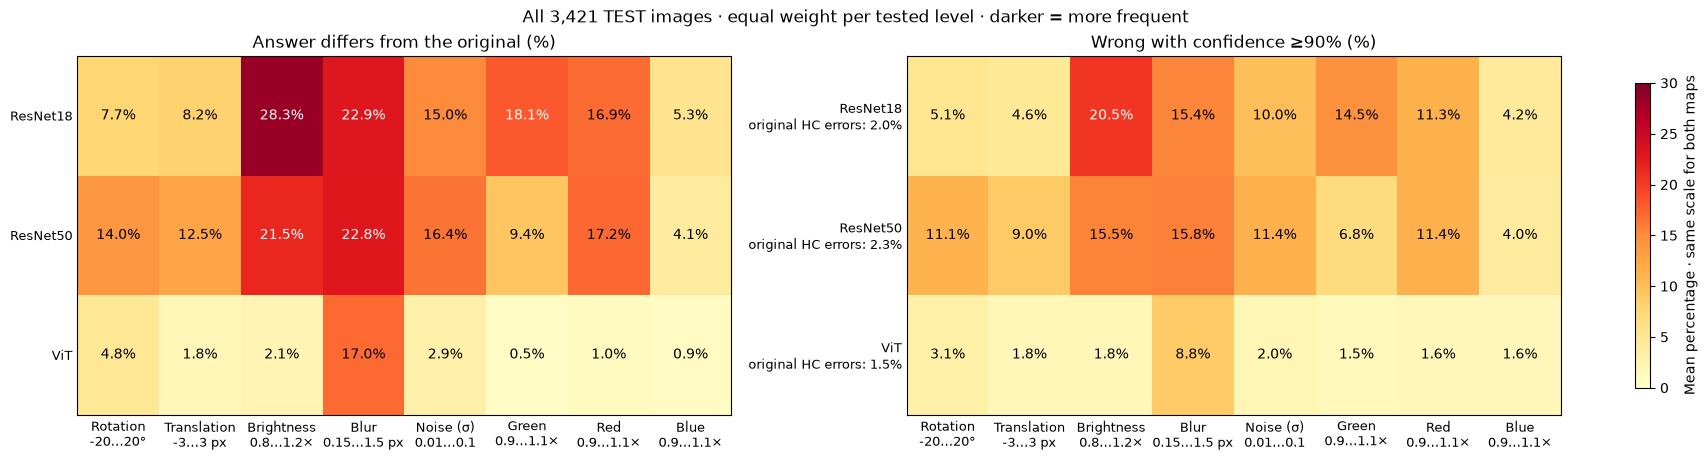

In [52]:
# Combine stability and confidence into one overview; reuse the full-test predictions.
with np.load('predictions/stability.npz', allow_pickle=False) as saved:
    np.testing.assert_array_equal(saved['indices'], np.arange(len(labels)))
    np.testing.assert_array_equal(saved['labels'], labels)
    np.testing.assert_array_equal(saved['baseline'], probabilities)
    summary_kinds = [key[7:] for key in saved.files if key.startswith('levels_')]
    summary_levels = {kind: saved[f'levels_{kind}'] for kind in summary_kinds}
    summary_flips, summary_errors = [], []
    for kind in summary_kinds:
        p = saved[kind]
        assigned = p.argmax(-1)
        summary_flips.append((assigned != predicted[:, None, None, :]).mean(2).mean((1, 2)))
        summary_errors.append(((assigned != labels) & (p.max(-1) >= threshold)).mean(2).mean((1, 2)))
summary_matrices = 100 * np.stack([np.stack(summary_flips, axis=1), np.stack(summary_errors, axis=1)])
summary_baseline = 100 * ((predicted != labels) & (confidence >= threshold)).mean(-1)
units = {'rotation': '°', 'translation': ' px', 'brightness': '×', 'blur': ' px',
         'noise': '', 'green_scale': '×', 'red_scale': '×', 'blue_scale': '×'}
short_names = ['Rotation', 'Translation', 'Brightness', 'Blur', 'Noise (σ)', 'Green', 'Red', 'Blue']
column_labels = [f'{name}\n{summary_levels[kind].min():g}…{summary_levels[kind].max():g}{units[kind]}'
                 for name, kind in zip(short_names, summary_kinds)]
summary_limit = max(10, 10 * np.ceil(summary_matrices.max() / 10))
fig, axes = plt.subplots(1, 2, figsize=(17, 4.5), layout='constrained')
for j, (ax, matrix, title) in enumerate(zip(axes, summary_matrices,
        ['Answer differs from the original (%)', f'Wrong with confidence ≥{threshold:.0%} (%)'])):
    im = ax.imshow(matrix, cmap='YlOrRd', vmin=0, vmax=summary_limit, aspect='auto')
    row_labels = ['ResNet18', 'ResNet50', 'ViT']
    if j == 1:
        row_labels = [f'{name}\noriginal HC errors: {rate:.1f}%' for name, rate in zip(row_labels, summary_baseline)]
    ax.set(title=title, xticks=range(8), xticklabels=column_labels, yticks=range(3), yticklabels=row_labels)
    ax.tick_params(axis='both', length=0, labelsize=9)
    for m in range(3):
        for k in range(8):
            ax.text(k, m, f'{matrix[m, k]:.1f}%', ha='center', va='center',
                    color='white' if matrix[m, k] > 0.6 * summary_limit else 'black', fontsize=10)
fig.colorbar(im, ax=axes, shrink=0.85, label='Mean percentage · same scale for both maps')
fig.suptitle(f'All {len(labels):,} TEST images · equal weight per tested level · darker = more frequent')
plt.show()


Compare model rows for broad differences, then use the transformation columns to identify exceptions to those patterns. ViT changes labels on only 0.5–2.9% of images under color scaling, brightness, translation and noise but on 17.0% under blur, while ResNet18 reaches 28.3% label changes and 20.5% confident errors under brightness changes. ViT’s stability advantage is therefore intervention-specific, while ResNet18’s brightness response shows that changing answers often does not produce a useful uncertainty warning.